# Investigating Vanishing Gradients and Early-Layer Trainability Across Network Depth in Deep MLPs on BloodMNIST

**Research Project - The Effects of Vanishing Gradients in Deep Neural Networks**

## Overview

This project investigates how network depth affects gradient propagation and early-layer trainability in multilayer perceptrons (MLPs) using the BloodMNIST dataset.

The study consists of two controlled experiments:

- **Stage A — Network Depth:** Compare MLPs with 2, 5, 10, and 20 hidden layers under a fixed Sigmoid–Xavier–SGD configuration.
- **Stage B — Activation Functions:** Compare Sigmoid, Tanh, and ReLU at a fixed depth of 5 hidden layers using the same Xavier Uniform initialization and training protocol.

The experiments measure layer-wise RMS weight gradients, normalized first-layer weight displacement, training-loss dynamics, and validation accuracy and macro-F1 across three random seeds.

## Notebook Organization

| Part | Description |
|---|---|
| **0 — Setup** | Import the required Python libraries. |
| **1 — Data Pipeline & Configuration** | Configure experiments; load, preprocess, and inspect BloodMNIST. |
| **2 — MLP Architecture** | Define and verify the configurable constant-width MLP. |
| **3 — Training & Validation** | Implement the training and evaluation procedures. |
| **4 — Gradient Measurements** | Implement layer-wise gradient recording and early-layer weight displacement measurements. |
| **5 — Pilot & Pipeline Verification** | Verify the end-to-end pipeline and finalize experimental settings. |
| **6 — Stage A: Network Depth** | Conduct the depth comparison and analyze gradient propagation and trainability. |
| **7 — Stage B: Activation Functions** | Conduct the controlled activation comparison at fixed D5. |
| **8 — Final Analysis & Reporting** | Verify results, prepare summary tables, and interpret findings, limitations, and conclusions. |


## Part 0 — Setup & Library Imports

Import the Python libraries and dependencies required for data preprocessing, MLP construction, training, gradient measurements, evaluation, and visualization throughout the notebook.

Experimental configuration, random seeds, and device selection are defined in Part 1.


In [2]:
import sys
print(sys.executable)

/opt/anaconda3/bin/python


In [3]:
%pip install torch torchvision medmnist scikit-learn matplotlib pandas numpy

# Basic libraries
import random
import time
import math
import json

# Libraries for data
import numpy as np
import pandas as pd

# Libraries for graphs and visualization
import matplotlib.pyplot as plt

# Deep learning
import torch
import torch.nn as nn
import torch.optim as optim  
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader 
from pathlib import Path
from torch.utils.data import TensorDataset
from dataclasses import dataclass
from torchvision.utils import make_grid

# Using scikit-learn for evaluation
from sklearn.metrics import f1_score

Note: you may need to restart the kernel to use updated packages.


## Part 1 — Data Pipeline & Experimental Configuration

### 1. Overview & Objectives

Part 1 prepares the BloodMNIST dataset and establishes a consistent experimental configuration for the gradient-vanishing study.

BloodMNIST contains RGB images of size 28 × 28 pixels across eight classes. The official dataset splits include 11,959 training, 1,712 validation, and 3,421 test images. Each image has shape `[3, 28, 28]` and is flattened into 2,352 input features by the MLP in Part 2.

RGB normalization statistics are computed from the training split only and applied to all three splits. The test split is reserved and excluded from the main experimental comparisons.

This part also defines the training settings and random-seed controls used in Stage A (network depth) and Stage B (activation functions).

### 2. Workflow & Section Guide

| Section | Main Task |
|---|---|
| **1.1 — Dataset Setup** | Import BloodMNIST and inspect dataset metadata. |
| **1.2 — Configuration** | Define experimental settings, random-seed control, and computing device. |
| **1.3 — Training Statistics** | Compute RGB mean and standard deviation from raw training images. |
| **1.4 — Preprocessing** | Define tensor conversion and channel-wise normalization. |
| **1.5 — Dataset Splits** | Load the official training, validation, and test datasets. |
| **1.6 — DataLoaders** | Create mini-batches with batch size 128 for training and 1,024 for evaluation. |
| **1.7 — Dataset Sizes** | Verify sample counts against official metadata. |
| **1.8 — Batch Inspection** | Check image and label shapes and data types. |
| **1.9 — Input Dimensions** | Verify that each flattened image contains 2,352 features. |
| **1.10 — Normalization Check** | Inspect RGB statistics and numerical validity. |
| **1.11 — Class Distribution** | Examine sample counts across the eight classes. |
| **1.12 — Class Visualization** | Display one training image from each class. |
| **1.13 — Reproducibility Check** | Verify DataLoader shuffling with fixed random seeds. |
| **1.14 — Batch Visualization** | Display eight images from a separate inspection DataLoader. |

Sections 1.1–1.6 establish the data pipeline; Sections 1.7–1.14 verify the prepared inputs.

### 3. Important Objects & Their Roles

| Object / Function | Defined In | Role |
|---|---|---|
| `Config` / `cfg` | 1.2 | Configuration class and instance containing model, training, and experiment settings. |
| `set_seed()` / `device` | 1.2 | Random-seed control and computing device selection. |
| `raw_train_dataset` | 1.3 | Raw training data used to calculate RGB normalization statistics. |
| `BLOODMNIST_MEAN`, `BLOODMNIST_STD` | 1.4 | Training-derived per-channel normalization statistics. |
| `transform` | 1.4 | Shared `ToTensor()` and `Normalize()` preprocessing pipeline. |
| `train_dataset`, `val_dataset`, `test_dataset` | 1.5 | Official BloodMNIST dataset splits with preprocessing attached. |
| `train_loader`, `val_loader`, `test_loader` | 1.6 | DataLoaders that provide mini-batches for training and evaluation. |
| `get_first_batch(seed)` | 1.13 | Inspection helper for checking reproducible first-batch shuffling. |
| `inspect_loader` / `imshow()` | 1.14 | Utilities for batch visualization, separate from the main training pipeline. |

**Key distinctions:**

- A `Dataset` provides individual image–label samples, while a `DataLoader` groups them into mini-batches.
- Section 1.9 checks the flattened input dimension; the MLP performs the actual flattening internally using `nn.Flatten()`.
- `get_first_batch(seed)` and `inspect_loader` are inspection utilities. Part 5 defines `make_train_loader(seed)` to create fresh seeded DataLoaders for experimental runs.

### 4. Expected Outcomes & Role in the Experiment

Part 1 produces verified BloodMNIST datasets, training-derived normalization statistics, reproducible DataLoaders, and a shared experimental configuration.

These components support controlled comparisons of network depth in Stage A and activation functions at fixed depth in Stage B.

No model training or hypothesis testing is performed in this part.  

---   

### 1.1 — BloodMNIST Package Setup & Dataset Metadata

**Objective**

Import BloodMNIST and inspect its metadata to identify the dataset specifications needed for preprocessing and model configuration.

**Procedure**

1. Install `medmnist` if needed.
2. Import `BloodMNIST`, `INFO`, and image preprocessing utilities.
3. Retrieve and display the dataset metadata using `info = INFO["bloodmnist"]`.

**Expected Results**

The required dataset utilities are imported, and the BloodMNIST metadata is displayed, including image dimensions, class labels, and official split sizes.

**Important Distinction**

`BloodMNIST` is the dataset class, while `INFO` contains metadata and `info` stores the metadata for BloodMNIST. Dataset instances and DataLoaders are created in later sections.

In [4]:
# Install medmnist. 
%pip install -q medmnist

Note: you may need to restart the kernel to use updated packages.


In [5]:
# Import dataset BloodMNIST
import medmnist
from medmnist import BloodMNIST, INFO
from torchvision import transforms

In [6]:
# Check information of BloodMNIST
info = INFO['bloodmnist']
print(info)

{'python_class': 'BloodMNIST', 'description': 'The BloodMNIST is based on a dataset of individual normal cells, captured from individuals without infection, hematologic or oncologic disease and free of any pharmacologic treatment at the moment of blood collection. It contains a total of 17,092 images and is organized into 8 classes. We split the source dataset with a ratio of 7:1:2 into training, validation and test set. The source images with resolution 3×360×363 pixels are center-cropped into 3×200×200, and then resized into 3×28×28.', 'url': 'https://zenodo.org/records/10519652/files/bloodmnist.npz?download=1', 'MD5': '7053d0359d879ad8a5505303e11de1dc', 'url_64': 'https://zenodo.org/records/10519652/files/bloodmnist_64.npz?download=1', 'MD5_64': '2b94928a2ae4916078ca51e05b6b800b', 'url_128': 'https://zenodo.org/records/10519652/files/bloodmnist_128.npz?download=1', 'MD5_128': 'adace1e0ed228fccda1f39692059dd4c', 'url_224': 'https://zenodo.org/records/10519652/files/bloodmnist_224.npz

### 1.2 — Experimental Configuration & Reproducibility

**Objective**

Define shared experimental settings, initialize random-seed controls, and select the computing device for the BloodMNIST study.

**Procedure**

1. Define a `Config` dataclass containing dataset paths, batch sizes, MLP dimensions, activation and initialization settings, optimizer hyperparameters, network depths, random seeds, and output directory.
2. Implement `set_seed(seed)` to initialize Python, NumPy, and PyTorch random-number generators.
3. Create `cfg = Config()` and select Apple MPS or CPU based on availability.
4. Set the initial random seed and display the configuration, device, and PyTorch version.

**Purpose**

Keep training conditions consistent while varying the intended experimental factor:

- **Stage A — Depth:** Compare D2, D5, D10, and D20 using Sigmoid and Xavier Uniform initialization.
- **Stage B — Activation:** Compare Sigmoid, Tanh, and ReLU at fixed D5 depth using the same initialization rule.

Both stages use SGD (learning rate 0.1, momentum 0, weight decay 0), 20 epochs, and three random seeds (0, 1, 2).

The learning rate is initially provisional, and `cfg.loss_threshold` is set to `None`. Part 5 verifies the learning rate and sets the loss threshold before the main experiments.

**Expected Results**

A `cfg` object containing the experimental settings, a reusable `set_seed()` function, and a selected computing device. The configuration and environment information are displayed for verification.

**Important Distinctions**

- `Config` defines the settings; `cfg` is its instance. The MLP architecture is defined separately in Part 2.
- `set_seed()` controls random-number generation but does not guarantee complete determinism across all hardware and operations.

In [ ]:
# Configuration: setup hyperparameters for the whole experiment
@dataclass
class Config:
    # Data
    data_dir: str = "./data"
    batch_size: int = 128
    eval_batch_size: int = 1024 

    # Model: 2352 -> 256 -> ... -> 256 -> 8
    input_dim: int = 3 * 28 * 28           
    hidden_dim: int = 256
    num_classes: int = 8  

    # Stage A baseline
    activation: str = "sigmoid"           
    init: str = "xavier_uniform"           

    # Optimizer  
    optimizer: str = "sgd"                 
    lr: float = 0.1                       
    momentum: float = 0.0
    epochs: int = 20  
    weight_decay: float = 0.0

    # Convergence threshold (used for H2: epochs-to-threshold)
    loss_threshold: float = None           

    # Experiment. 
    depths: tuple = (2, 5, 10, 20)   
    seeds: tuple = (0, 1, 2)  

    #Results
    results_dir: str = "./results"


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


cfg = Config()
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
set_seed(cfg.seeds[0])

print(cfg)
print("device:", device, "| torch:", torch.__version__)

Config(data_dir='/Users/utmbpblack25/Documents/WorkingProjects/data', batch_size=128, eval_batch_size=1024, input_dim=2352, hidden_dim=256, num_classes=8, activation='sigmoid', init='xavier_uniform', optimizer='sgd', lr=0.1, momentum=0.0, epochs=20, weight_decay=0.0, loss_threshold=None, depths=(2, 5, 10, 20), seeds=(0, 1, 2), results_dir='./results')
device: mps | torch: 2.14.1


### 1.3 — Load Raw Training Data & Compute RGB Normalization Statistics

**Objective**

Load the raw BloodMNIST training images and compute per-channel RGB mean and standard deviation for image normalization.

**Procedure**

1. Load the official training split into `raw_train_dataset` without applying a normalization transform.
2. Compute the mean and standard deviation across all training images and spatial positions for each RGB channel.
3. Divide the statistics by 255 to express them on the `[0, 1]` pixel-value scale.
4. Display the resulting RGB mean and standard deviation.  

**Expected Results**

- `raw_train_dataset`: Raw BloodMNIST training dataset.
- `train_mean`: Three mean values corresponding to the R, G, and B channels.
- `train_std`: Three standard deviation values corresponding to the R, G, and B channels.  

These statistics are used to define the normalization transform in Section 1.4.  

**Important distinction:**  

`raw_train_dataset` provides unnormalized images for computing statistics. The normalized `train_dataset` used for model training is created in Section 1.5.


In [8]:
# Load raw training data (without normalization)
raw_train_dataset = BloodMNIST(
    split="train",
    root=cfg.data_dir,
    download=True
)

# Calculate per-channel mean and std from train images only
train_mean = raw_train_dataset.imgs.mean(axis=(0, 1, 2)) / 255.0
train_std = raw_train_dataset.imgs.std(axis=(0, 1, 2)) / 255.0

print("Train mean (RGB):", train_mean)
print("Train std  (RGB):", train_std)


Train mean (RGB): [0.79434784 0.65965901 0.69619251]
Train std  (RGB): [0.21563033 0.24160339 0.11788897]


### 1.4 — Define Image Preprocessing & Normalization

**Objective**

Define a reusable preprocessing transform using the training-derived RGB statistics from Section 1.3.

**Procedure**

1. Convert `train_mean` and `train_std` to Python lists (`BLOODMNIST_MEAN` and `BLOODMNIST_STD`).
2. Create a `transforms.Compose` pipeline with:
   - `ToTensor()`: Convert each RGB image to a tensor of shape `[3, 28, 28]`, with pixel values scaled to `[0, 1]`.
   - `Normalize()`: Normalize each channel using its training-derived mean and standard deviation.

**Expected Results**

A `transform` object ready to apply the same preprocessing to the official training, validation, and test datasets in Section 1.5.  

In [9]:
# Convert train statistics to Python lists
BLOODMNIST_MEAN = train_mean.tolist()
BLOODMNIST_STD = train_std.tolist()

# Define image transforms
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=BLOODMNIST_MEAN,
        std=BLOODMNIST_STD
    )
])


### 1.5 — Load Official BloodMNIST Dataset Splits

**Objective**

Load the official BloodMNIST training, validation, and test splits using the shared preprocessing transform from Section 1.4.

**Procedure**

1. Create `train_dataset`, `val_dataset`, and `test_dataset` using `split="train"`, `"val"`, and `"test"`, respectively.
2. Apply the same `transform` and data directory (`cfg.data_dir`) to all three datasets.

**Expected Results**

Three preprocessed `BloodMNIST` dataset objects:

| Dataset | Samples | Role |
|---|---:|---|
| `train_dataset` | 11,959 | Training model parameters |
| `val_dataset` | 1,712 | Evaluating models without weight updates |
| `test_dataset` | 3,421 | Reserved for independent evaluation; not used in the main experiments |

Each dataset provides image–label pairs with the shared preprocessing applied to its images.

**Important Distinction**

A `Dataset` provides individual samples. Section 1.6 creates `DataLoader` objects to organize these samples into mini-batches.

In [10]:
# Load training dataset
train_dataset = BloodMNIST(
    split="train",
    root=cfg.data_dir,
    transform=transform,
    download=True
)

# Load validation dataset
val_dataset = BloodMNIST(
    split="val",
    root=cfg.data_dir,
    transform=transform,
    download=True
)

# Load test dataset
test_dataset = BloodMNIST(
    split="test",
    root=cfg.data_dir,
    transform=transform,
    download=True
)


### 1.6 — Create Training, Validation & Test DataLoaders

**Objective**

Create DataLoaders for training and evaluation with consistent batch sizes and controlled data shuffling.

**Procedure**

1. Initialize a `torch.Generator` using the first experimental seed (`cfg.seeds[0] = 0`).
2. Create `train_loader` with batch size 128 and `shuffle=True`, using the seeded generator.
3. Create `val_loader` and `test_loader` with batch size 1,024 and `shuffle=False`.

**Expected Results**

| DataLoader | Batch Size | Shuffle | Role |
|---|---:|---|---|
| `train_loader` | 128 | Yes | Supply training mini-batches |
| `val_loader` | 1,024 | No | Supply validation mini-batches |
| `test_loader` | 1,024 | No | Supply reserved test mini-batches |

Each DataLoader provides batches of images and their corresponding labels.

**Important Distinction**

The `train_loader` created here uses a seeded generator for initial data inspection and pipeline development. Part 5 defines `make_train_loader(seed)` to create a fresh DataLoader for each experimental run, ensuring that training shuffling starts from the assigned seed rather than reusing an advanced generator state.

In [11]:
# Set seed for training batch shuffling
seed = cfg.seeds[0]
g = torch.Generator().manual_seed(seed)

# Training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=cfg.batch_size,
    shuffle=True,
    generator=g
)

# Validation DataLoader
val_loader = DataLoader(
    val_dataset,
    batch_size=cfg.eval_batch_size,
    shuffle=False
)

# Test DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=cfg.eval_batch_size,
    shuffle=False
)


### 1.7 — Verify Official Dataset Split Sizes

**Objective**

Verify that the loaded BloodMNIST datasets match the official sample counts reported in MedMNIST metadata.

**Procedure**

1. Display the number of samples in each dataset using `len()`.
2. Retrieve the official split sizes from `INFO["bloodmnist"]["n_samples"]`.
3. Use `assert` statements to check the loaded sample counts against the official metadata.

**Expected Results**

| Dataset | Expected Samples |
|---|---:|
| Training | 11,959 |
| Validation | 1,712 |
| Test | 3,421 |

All assertions pass, and the code prints `Dataset sizes: OK`.

In [12]:
# Check official dataset sizes
print("Train samples:", len(train_dataset))
print("Val samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

# Verify sizes against official MedMNIST metadata
official = INFO["bloodmnist"]["n_samples"]

assert len(train_dataset) == official["train"]
assert len(val_dataset) == official["val"]
assert len(test_dataset) == official["test"]

print("Dataset sizes: OK")


Train samples: 11959
Val samples: 1712
Test samples: 3421
Dataset sizes: OK


### 1.8 — Inspect Training Batch Shapes & Data Types

**Objective**

Verify that the training DataLoader returns image and label tensors with the expected shapes and data types.

**Procedure**

1. Retrieve one mini-batch using `next(iter(train_loader))`.
2. Display the shapes and data types of `images` and `labels`.
3. Use assertions to verify the image dimensions `[B, 3, 28, 28]` and label dimensions `[B, 1]`, where `B` is the batch size.

**Expected Results**

| Tensor | Shape | Data Type |
|---|---|---|
| `images` | `[128, 3, 28, 28]` | `torch.float32` |
| `labels` | `[128, 1]` | `torch.int64` |

All shape assertions pass, and the code prints `Batch shapes: OK`.

In [13]:
# Get one batch
images, labels = next(iter(train_loader))

# Inspect shapes and data types
print("Images shape:", images.shape)
print("Images dtype:", images.dtype)

print("Labels shape:", labels.shape)
print("Labels dtype:", labels.dtype)

# Check expected dimensions
assert images.ndim == 4
assert images.shape[1:] == (3, 28, 28)
assert labels.shape == (images.shape[0], 1)

print("Batch shapes: OK")


Images shape: torch.Size([128, 3, 28, 28])
Images dtype: torch.float32
Labels shape: torch.Size([128, 1])
Labels dtype: torch.int64
Batch shapes: OK


### 1.9 — Verify Flattened MLP Input Dimensions

**Objective**

Verify that each BloodMNIST image can be flattened into 2,352 features (`3 × 28 × 28`), matching the MLP input dimension.

**Procedure**

1. Flatten the image batch using `images.flatten(start_dim=1)`, preserving the batch dimension.
2. Display the original and flattened tensor shapes.
3. Assert that the flattened feature dimension matches `cfg.input_dim`.

**Expected Results**

- Original shape: `[128, 3, 28, 28]`
- Flattened shape: `[128, 2352]`
- The assertion passes, and the code prints `MLP input dimension: OK`.

**Important Distinction**

Flattening here is only an input-dimension check. The MLP in Part 2 performs flattening internally using `nn.Flatten()`; `flat_images` is not passed separately to the model during training.

In [14]:
# Check flattened image dimensions
flat_images = images.flatten(start_dim=1)

print("Original shape:", images.shape)
print("Flattened shape:", flat_images.shape)

# Verify input dimension for MLP
assert flat_images.shape[1] == cfg.input_dim

print("MLP input dimension: OK")


Original shape: torch.Size([128, 3, 28, 28])
Flattened shape: torch.Size([128, 2352])
MLP input dimension: OK


### 1.10 — Verify Image Normalization & Numerical Validity

**Objective**

Verify that the normalized training images have valid numerical values and reasonable RGB statistics before model training.

**Procedure**

1. Display the training-derived RGB means (`BLOODMNIST_MEAN`) and standard deviations (`BLOODMNIST_STD`).
2. Assert that all training-derived standard deviations are positive.
3. Compute the per-channel mean and standard deviation of the normalized image batch.
4. Use `torch.isfinite()` to verify that all values in the inspected batch are finite.

**Expected Results**

- All training-derived RGB standard deviations are positive.
- The normalized batch has RGB means near 0 and standard deviations near 1.
- All numerical checks pass, and the code prints `Normalization checks: OK`.

**Important Distinction**

Batch statistics need not equal exactly 0 and 1 because normalization uses statistics computed from the entire training split, not the inspected mini-batch.

In [15]:
# Display normalization statistics
print("Training mean (RGB):", BLOODMNIST_MEAN)
print("Training std (RGB):", BLOODMNIST_STD)

# Verify that standard deviations are positive
assert np.all(train_std > 0)

# Inspect the normalized images in one batch
print("Batch mean (RGB):", images.mean(dim=(0, 2, 3)))
print("Batch std (RGB):", images.std(dim=(0, 2, 3), correction=0))

# Check for invalid values
assert torch.isfinite(images).all()

print("Normalization checks: OK")


Training mean (RGB): [0.7943478411516793, 0.6596590061729182, 0.6961925053489914]
Training std (RGB): [0.2156303262263197, 0.24160339316316254, 0.11788897317002958]
Batch mean (RGB): tensor([0.0223, 0.0223, 0.0033])
Batch std (RGB): tensor([0.9833, 0.9795, 0.9816])
Normalization checks: OK


### 1.11 — Inspect & Verify Class Distribution

**Objective**

Examine the class distribution across the official BloodMNIST splits and verify that class counts match the dataset sizes.

**Procedure**

1. Retrieve the eight official class labels from `INFO["bloodmnist"]["label"]`.
2. Use `np.bincount()` to count samples in each class for the training, validation, and test splits.
3. Display class counts and verify that their totals match the corresponding dataset sizes.
4. Plot the training-set class distribution using a horizontal bar chart.

**Purpose**

Identify class imbalance and provide context for interpreting validation accuracy and macro-F1 in later experiments.

**Expected Results**

- Class counts for all eight classes across the three dataset splits.
- A horizontal bar chart showing the training-set class distribution.
- All count checks pass, and the code prints `Class distribution checks: OK`.

Class       Train      Val     Test
0             852      122      244
1            2181      312      624
2            1085      155      311
3            2026      290      579
4             849      122      243
5             993      143      284
6            2330      333      666
7            1643      235      470

Class distribution checks: OK


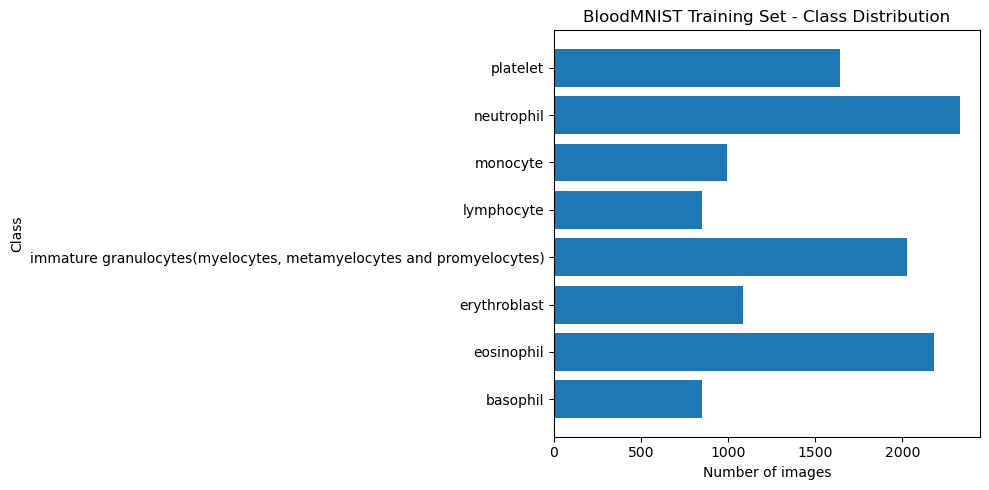

In [20]:
# Get official class names
class_names = INFO["bloodmnist"]["label"]

# Count samples in each class for each split
train_counts = np.bincount(
    train_dataset.labels.flatten(),
    minlength=cfg.num_classes
)

val_counts = np.bincount(
    val_dataset.labels.flatten(),
    minlength=cfg.num_classes
)

test_counts = np.bincount(
    test_dataset.labels.flatten(),
    minlength=cfg.num_classes
)

# Display class distribution
print(f"{'Class':<8} {'Train':>8} {'Val':>8} {'Test':>8}")

for i in range(cfg.num_classes):
    print(
        f"{i:<8} "
        f"{train_counts[i]:>8} "
        f"{val_counts[i]:>8} "
        f"{test_counts[i]:>8}"
    )

# Verify that class counts match dataset sizes
assert train_counts.sum() == len(train_dataset)
assert val_counts.sum() == len(val_dataset)
assert test_counts.sum() == len(test_dataset)

print("\nClass distribution checks: OK")

# Get class names for visualization
names = [class_names[str(i)] for i in range(cfg.num_classes)]

# Plot training class distribution
plt.figure(figsize=(10, 5))
plt.barh(names, train_counts)
plt.xlabel("Number of images")
plt.ylabel("Class")
plt.title("BloodMNIST Training Set - Class Distribution")
plt.tight_layout()
plt.show()


**1.11 - Output Interpretation**

The training set shows class imbalance, with neutrophils having the most samples (2,330) and lymphocytes the fewest (849). All class-count checks pass.

This imbalance supports reporting macro-F1 alongside accuracy, since macro-F1 gives equal weight to each class regardless of its frequency.  

---  

### 1.12 — Visualize One Training Image per Class

**Objective**

Display one training image from each of the eight BloodMNIST classes to inspect representative examples of the classification task.

**Procedure**

1. Find the first training sample belonging to each class (0–7).
2. Retrieve the corresponding normalized images from `train_dataset`.
3. Reverse normalization using `BLOODMNIST_MEAN` and `BLOODMNIST_STD` for visualization.
4. Rearrange image dimensions from `[C, H, W]` to `[H, W, C]` and display all eight images.

**Expected Results**

A figure showing eight training images, one per class, labeled with their class indices (0–7).

**Important Distinction**

Reversing normalization is performed only for visualization. It does not change the dataset or the normalized inputs used for model training.

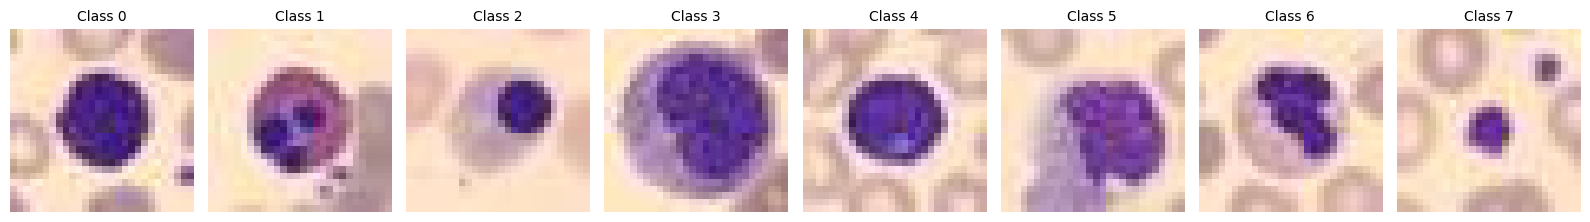

In [17]:
# Get training labels
train_labels = train_dataset.labels.reshape(-1)

# Prepare mean and std for undoing normalization
mean = torch.tensor(BLOODMNIST_MEAN).view(3, 1, 1)
std = torch.tensor(BLOODMNIST_STD).view(3, 1, 1)

# Create a figure with 8 images
fig, axes = plt.subplots(1, cfg.num_classes, figsize=(16, 3))

for i in range(cfg.num_classes):
    # Find the first image belonging to class i
    idx = np.where(train_labels == i)[0][0]

    # Get the normalized image
    image, label = train_dataset[int(idx)]

    # Undo normalization for visualization
    image = image * std + mean

    # Convert [C, H, W] to [H, W, C]
    image = image.permute(1, 2, 0)

    # Display image
    axes[i].imshow(image.clamp(0, 1).numpy())
    axes[i].set_title(f"Class {i}", fontsize=10)
    axes[i].axis("off")

plt.tight_layout()
plt.show()


### 1.13 — Verify DataLoader Shuffling Reproducibility

**Objective**

Verify that independently created training DataLoaders produce identical first mini-batches when initialized with the same random seed.

**Procedure**

1. Define `get_first_batch(seed)` to create a shuffled training DataLoader using a freshly seeded `torch.Generator`.
2. Retrieve two first batches using seed 42 and one using seed 43.
3. Use `torch.equal()` and assertions to compare images and labels from the same-seed batches.
4. Check whether the first image batches differ between seeds 42 and 43.

**Expected Results**

- Seed 42 produces identical first-batch images and labels across both calls.
- The assertions pass, and the code prints `Same seed reproduces the first batch: OK`.
- Different seeds are expected to produce different first batches, displayed as `True`.

**Important Distinction**

This check verifies first-batch reproducibility, not complete training determinism. Part 5 defines `make_train_loader(seed)` to create fresh seeded DataLoaders for the main experimental runs.

In [18]:
# Get the first batch using a specific seed
def get_first_batch(seed):
    g = torch.Generator().manual_seed(seed)

    loader = DataLoader(
        train_dataset,
        batch_size=cfg.batch_size,
        shuffle=True,
        generator=g
    )

    return next(iter(loader))


# Same seed
images_a, labels_a = get_first_batch(42)
images_b, labels_b = get_first_batch(42)

# Different seed
images_c, labels_c = get_first_batch(43)

# Verify reproducibility
assert torch.equal(images_a, images_b)
assert torch.equal(labels_a, labels_b)

print("Same seed reproduces the first batch: OK")
print(
    "Different seeds give different first batches:",
    not torch.equal(images_a, images_c)
)


Same seed reproduces the first batch: OK
Different seeds give different first batches: True


### 1.14 — Visualize a Batch of Eight BloodMNIST Images

**Objective**

Display eight training images from a DataLoader to visually inspect the prepared BloodMNIST inputs and their class labels.

**Procedure**

1. Define `imshow(img)` to convert image tensors to NumPy arrays and reverse RGB normalization for display.
2. Create `inspect_loader` with batch size 8 and `shuffle=False`.
3. Retrieve one batch of images and labels.
4. Use `make_grid()` to arrange the images in a single row, display the grid, and print their class indices.

**Expected Results**

- A horizontal grid of eight BloodMNIST training images displayed on the original RGB scale.
- A list of eight corresponding class indices.

**Important Distinction**

Unlike Section 1.12, which displays one image per class, this section shows a DataLoader batch without requiring all classes to be represented. The separate `inspect_loader` and reversed normalization are used only for visualization; the training pipeline remains unchanged.

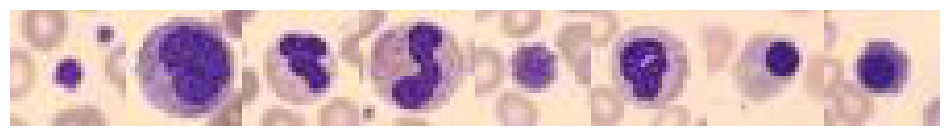

Labels: [7, 3, 6, 6, 7, 6, 2, 2]


In [19]:
# Convert mean and std to arrays for broadcasting
mean = np.array(BLOODMNIST_MEAN).reshape(3, 1, 1)
std = np.array(BLOODMNIST_STD).reshape(3, 1, 1)

# Function to display normalized images
def imshow(img):
    np_img = img.detach().cpu().numpy()
    np_img = np_img * std + mean  # Undo normalization
    np_img = np.clip(np_img, 0, 1)
    np_img = np.transpose(np_img, (1, 2, 0))

    plt.figure(figsize=(12, 3))
    plt.imshow(np_img)
    plt.axis("off")
    plt.show()

# Create a separate DataLoader for inspection
inspect_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=False
)

# Get one batch containing 8 images
images, labels = next(iter(inspect_loader))

# Display the 8 images
grid = make_grid(images, nrow=8, padding=0)
imshow(grid)

# Display their labels
print("Labels:", labels.squeeze(1).tolist())


## Part 2 — Configurable Constant-Width MLP (Model Construction & Verification)

### 1. Overview & Objectives

Part 2 implements a configurable Multi-Layer Perceptron (MLP) for investigating how network depth and activation functions affect gradient propagation and trainability.

The model uses the following architecture:

`2352 → 256 → ... → 256 → 8`

- **Input:** 2,352 features from flattened BloodMNIST images (`3 × 28 × 28`).
- **Hidden layers:** Configurable depth with 256 neurons per layer.
- **Activation:** Sigmoid, Tanh, or ReLU, applied consistently across all hidden layers.
- **Output:** Eight raw logits, one per class, without Softmax.
- **Initialization:** Xavier Uniform (gain = 1) for Linear weights and zero initialization for biases.

The architecture excludes Batch Normalization, Dropout, and residual connections to keep the comparisons focused on depth and activation choice.

### 2. Workflow & Section Guide

| Section | Main Task |
|---|---|
| **2.1 — Define Configurable MLP** | Implement `ConstantWidthMLP` with configurable depth and activation functions. |
| **2.2 — Initialize Weights and Biases** | Apply Xavier Uniform initialization and set Linear biases to zero. |
| **2.3 — Build MLP Model** | Define `build_model()` to construct models with specified depths, activations, and random seeds. |
| **2.4 — Verify D2 Model** | Inspect the D2 architecture and verify its forward-pass output. |
| **2.5 — Verify Model Depths** | Check forward passes and output dimensions for D2, D5, D10, and D20. |
| **2.6 — Verify Model Parameters** | Check parameter counts and zero-initialized biases. |
| **2.7 — Verify Reproducibility** | Confirm that identical model configurations and random seeds produce identical initial parameters. |

Sections 2.1–2.3 implement the model construction functions; Sections 2.4–2.7 verify the resulting architectures.

### 3. Important Objects & Their Roles

| Object / Function | Role |
|---|---|
| `ConstantWidthMLP(nn.Module)` | Define the configurable MLP architecture. |
| `__init__()` | Create the hidden layers, activation function, and output layer. |
| `forward()` | Flatten input images and compute the model's output logits. |
| `linear_layers()` | Return Linear layers in input-to-output order for gradient and parameter analysis. |
| `initialize_weights(model)` | Apply Xavier Uniform initialization to Linear weights and initialize biases to zero. |
| `build_model(depth, seed, activation=None)` | Construct and initialize a model using the specified configuration and random seed. |
| `count_params(model)` / `expected_params(depth)` | Compute actual and expected parameter counts for verification. |

### 4. Expected Outcomes & Role in the Experiment

Part 2 produces a verified MLP architecture that supports:

- **Stage A:** D2, D5, D10, and D20 with Sigmoid activation.
- **Stage B:** Sigmoid, Tanh, and ReLU at fixed D5 depth.

All configurations use a hidden width of 256 and the same Xavier Uniform initialization rule. Each model contains `depth + 1` Linear layers, including the output layer, and produces logits with shape `[B, 8]`, where `B` is the batch size.

These models are used by the training pipeline in Part 3 and the gradient-measurement procedures in Part 4. **No model training or gradient analysis is performed in Part 2.**  

---  

### 2.1 — Define Configurable Constant-Width MLP

**Objective**

Define a reusable MLP architecture with configurable network depth and activation function, while keeping the hidden width fixed at 256 neurons.

**Procedure**

1. Create `ConstantWidthMLP(nn.Module)` with configurable `depth`, `input_dim`, `hidden_dim`, `num_classes`, and `activation`.
2. Use `nn.Flatten()` to convert images from `[B, 3, 28, 28]` to `[B, 2352]`.
3. Use `nn.ModuleList()` and a loop to construct `depth` hidden Linear layers, followed by one output Linear layer.
4. Apply Sigmoid, Tanh, or ReLU after each hidden Linear layer.
5. Define `linear_layers()` to return the Linear layers in input-to-output order for subsequent gradient measurements.
6. Define `forward()` to compute the model's output logits.

**Purpose**

Provide a consistent architecture for comparing network depths in Stage A and activation functions in Stage B.

**Expected Results**

A configurable MLP class with the architecture:

`2352 → 256 → ... → 256 → 8`

The class supports D2, D5, D10, and D20, corresponding to 2, 5, 10, and 20 hidden Linear layers, respectively. Each model has one additional output Linear layer and produces eight raw logits per image.

**Important Distinction**

This section defines the MLP class but does not instantiate or train a model. The output layer has no final activation because `nn.CrossEntropyLoss()` expects raw logits.

In [ ]:
class ConstantWidthMLP(nn.Module):                   

    def __init__(                                      
                 self,                                 
                 depth,                                 
                 input_dim=2352,                      
                 hidden_dim=256,                        
                 num_classes=8,                         
                 activation="sigmoid"                   
                 ):

        super().__init__()                              

        if depth < 1:                                        
            raise ValueError("depth must be at least 1")     

        # Flatten input images
        self.flatten = nn.Flatten()                      

        # Create hidden layers 
        self.hidden_layers = nn.ModuleList()             

        for i in range(depth):                           
            in_features = input_dim if i == 0 else hidden_dim     

            self.hidden_layers.append(                   
                nn.Linear(in_features, hidden_dim)       
            )                                           

        # Choose activation function (The same activation type is used after every hidden layer)
        if activation == "sigmoid":                      
            self.activation = nn.Sigmoid()
                                                         
        elif activation == "tanh":                       
            self.activation = nn.Tanh()

        elif activation == "relu":                       
            self.activation = nn.ReLU()

        else:
            raise ValueError(f"Unsupported activation: {activation}")    

        # Create the final output Linear layer.
        self.output_layer = nn.Linear(hidden_dim, num_classes)            

    # Return all Linear layers in input-to-output order (useful for measuring gradients in Part 4)
    def linear_layers(self):
        return [*self.hidden_layers, self.output_layer]   

    def forward(self, x):                                 

        # Flatten each image into a one-dimensional feature vector, [B, 3, 28, 28] -> [B, 2352]. The batch dimension B is preserved.
        x = self.flatten(x)

        # Pass data through hidden layers one by one
        for layer in self.hidden_layers:         
            x = self.activation(layer(x))        
                                               
                                                
                                                 
                                                 
         # Return raw logits
        x = self.output_layer(x)                 

        return x                                


### 2.2 — Initialize Weights and Biases

**Objective**

Define a consistent initialization procedure for all Linear layers using Xavier Uniform weights and zero biases.

**Procedure**

1. Define `initialize_weights(model)` to iterate through the model's modules.
2. Identify Linear layers using `isinstance(layer, nn.Linear)`.
3. Apply Xavier Uniform initialization (`gain=1.0`) to each Linear weight matrix:

   $$
   W \sim U(-a,a), \qquad a=\sqrt{\frac{6}{fan_{in}+fan_{out}}}
   $$

4. Initialize all Linear biases to zero using `nn.init.zeros_()`.

**Purpose**

Apply the same initialization rule across network depths and activation functions to support controlled experimental comparisons.

**Expected Results**

A reusable `initialize_weights(model)` function that initializes all hidden and output Linear layers with Xavier Uniform weights and zero biases.

**Important Distinction**

PyTorch initializes Linear layers automatically when they are created. This function replaces the default initialization with the specified experimental rule. Weights and biases remain trainable during model optimization.

In [ ]:
def initialize_weights(model):        

    for layer in model.modules():     

        if isinstance(layer, nn.Linear):  

            nn.init.xavier_uniform_(layer.weight, gain=1.0)                                               
            
            # Initialize all bias values to zero (applies to both hidden and output layers). zeros_() also modifies the existing tensor in place.
            nn.init.zeros_(layer.bias)


### 2.3 — Build MLP Model

**Objective**

Define a reusable function to construct MLP models with specified depths, activation functions, and random seeds.

**Procedure**

1. Define `build_model(depth, seed, activation=None)`.
2. Use `cfg.activation` (Sigmoid) when no activation is specified.
3. Set the PyTorch random seed using `torch.manual_seed(seed)`.
4. Create a `ConstantWidthMLP` instance using the specified depth and activation, along with the dimensions stored in `cfg`.
5. Apply `initialize_weights(model)` to initialize Linear weights with Xavier Uniform and biases with zeros.
6. Return the initialized model.

**Purpose**

Standardize model construction and initialization across experimental conditions without repeating the same code.

**Expected Results**

A reusable `build_model()` function that supports:

- **Stage A:** D2, D5, D10, and D20 with Sigmoid activation.
- **Stage B:** Sigmoid, Tanh, and ReLU at fixed D5 depth.

Each call returns a newly constructed MLP with the specified architecture and initialization rule.

**Important Distinction**

Using the same architecture and seed produces identical initial parameters under the same execution conditions. Different network depths may produce different initial weights even when the same seed is used.

`build_model()` constructs and initializes a model; it does not train or evaluate it.

In [ ]:
# Define a reusable function to build an MLP model with controlled initialization
def build_model(depth, seed, activation=None):    
                                                                                                                                                    
    # Use baseline activation (cfg.activation) if none is specified
    if activation is None:                        
        activation = cfg.activation               

    # Set the PyTorch random seed before creating the model.
    torch.manual_seed(seed)        

    # Create MLP
    model = ConstantWidthMLP(      
        depth=depth,               
        input_dim=cfg.input_dim,   
        hidden_dim=cfg.hidden_dim,
        num_classes=cfg.num_classes,
        activation=activation
    )

    # Initialize weights and biases
    initialize_weights(model)      # Apply Xavier Uniform 

    # Return the initialized model object
    return model                   


### 2.4 — Verify D2 MLP Architecture & Forward Pass

**Objective**

Verify that the D2 MLP has the expected architecture and produces valid output logits from BloodMNIST images before training.

**Procedure**

1. Build a D2 model using the first experimental seed (`cfg.seeds[0] = 0`), Sigmoid activation, and Xavier Uniform initialization.
2. Display the model architecture to inspect its Linear layers and dimensions.
3. Retrieve eight normalized training images and combine them into a batch.
4. Perform a forward pass using `model.eval()` and `torch.no_grad()`.
5. Assert that the output has shape `[8, 8]`, contains only finite values, and uses a Linear output layer.

**Expected Results**

- **Architecture:** `2352 → 256 → 256 → 8`, with Sigmoid after each hidden Linear layer.
- **Input shape:** `[8, 3, 28, 28]`.
- **Output shape:** `[8, 8]`, containing eight logits per image.
- All assertions pass, and the code prints `D2 forward pass: OK`.

**Important Distinction**

This section checks an untrained model's forward pass. `torch.no_grad()` disables gradient tracking, and `model.eval()` sets evaluation mode; neither operation trains or updates model parameters.

The final Linear layer returns raw logits without an additional activation, as required by `nn.CrossEntropyLoss()`.

In [ ]:
# Create the baseline D2 MLP.
model_d2 = build_model(   
    depth=2,              
    seed=cfg.seeds[0]     
)

# Display the architecture of the D2 model (PyTorch prints all registered modules and their dimensions)
print(model_d2)

# Get 8 images directly from the BloodMNIST training dataset.
sample_images = torch.stack(
    [train_dataset[i][0] for i in range(8)]   
)                                           
                                                                        
# Forward pass through model D2 without gradient tracking
# 8 images BloodMNIST [8, 3, 28, 28] -> Flatten [8, 3*28*28] or [8, 2352] -> Hidden Layer 1 + Sigmoid [8, 256] -> Hidden Layer 2 + Sigmoid [8, 256] -> Output Linear Layer [8, 8]. Results are logits with shape [8, 8].
model_d2.eval()       

with torch.no_grad():  

    logits = model_d2(sample_images)   
                                        
                                        
# Print the input and output tensor shapes.
print("Input shape:", sample_images.shape)
print("Output shape:", logits.shape)

# Verify that the output shape is correct [8, 8]
assert logits.shape == (8, cfg.num_classes)  

# Verify that all output values are finite (output values are not NaN, +inf, or -inf)
assert torch.isfinite(logits).all()          
                                            

# Verify that the output layer is Linear (raw logits)
assert isinstance(model_d2.output_layer, nn.Linear)

print("Output layer: Linear (raw logits, no final activation) - OK")

print("D2 forward pass: OK")                 


ConstantWidthMLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (hidden_layers): ModuleList(
    (0): Linear(in_features=2352, out_features=256, bias=True)
    (1): Linear(in_features=256, out_features=256, bias=True)
  )
  (activation): Sigmoid()
  (output_layer): Linear(in_features=256, out_features=8, bias=True)
)
Input shape: torch.Size([8, 3, 28, 28])
Output shape: torch.Size([8, 8])
Output layer: Linear (raw logits, no final activation) - OK
D2 forward pass: OK


### 2.5 Check models D2, D5, D10, D20
**Objective:** Confirm that the same configurable MLP class correctly constructs and runs networks with 2, 5, 10, and 20 hidden layers.

**Procedure:**

1. Iterate over the configured depths: D2, D5, D10, and D20.

2. Build a new model for each depth using the same hidden width, activation function, Xavier initialization rule, and random seed.

3. Pass the same batch of 8 BloodMNIST images through each model.

4. Verify that each network contains exactly depth + 1 Linear layers, including the output layer.

5. Verify that every model returns finite logits with shape [8, 8].

**Expected Result:**

- D2: 2 hidden layers + 1 output layer.

- D5: 5 hidden layers + 1 output layer.

- D10: 10 hidden layers + 1 output layer.

- D20: 20 hidden layers + 1 output layer.

- All models produce outputs with shape [8, 8].

**Purpose:** Ensure that changing the depth parameter correctly changes the number of hidden layers while preserving the required input and output dimensions.

These checks verify model construction and forward computation, not training performance.

In [ ]:
# Loop through the depths defined in Config.
# Example: cfg.depths = (2, 5, 10, 20). The loop runs four times, creating one model per depth.
for depth in cfg.depths:
    model = build_model(              # Build a new model for the current depth. Each model uses:
        depth=depth,                  # - The same hidden width (256)
        seed=cfg.seeds[0]             # - The same baseline activation (Sigmoid)
    )                                 # - The same initialization rule (Xavier Uniform)
                                      # - The same experimental seed

    model.eval()                      

    with torch.no_grad():             
        logits = model(sample_images) # Reuse the same 8 images from Section 2.4. 

    # Check the total number of Linear layers.
    assert len(model.linear_layers()) == depth + 1  

    # Check that the output has 8 logits per image.
    assert logits.shape == (8, cfg.num_classes)

    # Check that the output contains no NaN or infinity.
    assert torch.isfinite(logits).all()

    # Print the current model's depth and output shape.
    print(f"D{depth}: output shape = {logits.shape} - OK") 

# Print the final message after all four models pass.
print("All MLP architectures: OK")


D2: output shape = torch.Size([8, 8]) - OK
D5: output shape = torch.Size([8, 8]) - OK
D10: output shape = torch.Size([8, 8]) - OK
D20: output shape = torch.Size([8, 8]) - OK
All MLP architectures: OK


### 2.6 — Verify Model Parameters & Bias Initialization

**Objective**

Verify that D2, D5, D10, and D20 have the expected parameter counts and zero-initialized Linear biases.

**Procedure**

1. Define `count_params(model)` to count model parameters using `p.numel()`.
2. Define `expected_params(depth)` to calculate the theoretical parameter count for a constant-width MLP:

   $$
   P(D) = (2352 \times 256 + 256) + (D-1)(256^2 + 256) + (256 \times 8 + 8)
   $$

   where \(D\) is the number of hidden layers. Each term includes both weights and biases.

3. Build models for D2, D5, D10, and D20, and assert that their actual parameter counts match the calculated values.
4. Verify that all Linear layer biases are initialized to zero.

**Expected Results**

| Model | Linear Layers (Including Output) | Total Parameters |
|---|---:|---:|
| D2 | 3 | 670,216 |
| D5 | 6 | 867,592 |
| D10 | 11 | 1,196,552 |
| D20 | 21 | 1,854,472 |

All parameter-count and bias-initialization checks pass, and each model prints its parameter count followed by `OK`.

**Important Distinction**

All models have the same hidden width of 256 neurons, but deeper models contain more layers and therefore more parameters. Zero-initialized biases remain trainable during optimization.

In [ ]:
# Define a function to count all model parameters.
def count_params(model):
    return sum(p.numel() for p in model.parameters()) # returns the trainable parameter tensors, including Linear weights and biases. 
                                                      
                                                    



# Calculate the expected number of parameters (This formula assumes the constant-width MLP architecture)
def expected_params(depth):  # Read model dimensions from Config.

    d = cfg.input_dim        # d: input dimension = 2352
    h = cfg.hidden_dim       # h: hidden width = 256
    c = cfg.num_classes      # c: output classes = 8

    first_hidden = d * h + h                     
    other_hidden = (depth - 1) * (h * h + h)     
    output = h * c + c                           

    return first_hidden + other_hidden + output  


# Check all four model depths and verify parameters & biases.
for depth in cfg.depths:

    model = build_model(depth=depth, seed=cfg.seeds[0])  # Create a model using the baseline configuration.

    actual = count_params(model)                         

    expected = expected_params(depth)                   

    assert actual == expected                            

    # Verify all bias initialization are zero for every Linear layer
    for layer in model.linear_layers():
        assert torch.count_nonzero(layer.bias).item() == 0   
                                                            

    print(f"D{depth}: {actual:,} parameters - OK")          
                                                            


D2: 670,216 parameters - OK
D5: 867,592 parameters - OK
D10: 1,196,552 parameters - OK
D20: 1,854,472 parameters - OK


### 2.7 Verify Model Initialization Reproducibility
**Objective:** Verify that models with identical architectures and random seeds receive identical initial parameters.

**Procedure:**

1. Create two D10 models using the same random seed (seed=0).

2. Create a third D10 model using a different seed (seed=1).

3. Compare corresponding weights and biases across models using torch.equal().

4. Verify that the two models created with the same seed have identical parameters.

5. Verify that at least one parameter tensor differs when using different seeds.

**Expected Result:**

- Same architecture + same seed → identical initial parameters.

- Same architecture + different seeds → different initial weights.

**Purpose:** Verify that model initialization is reproducible under the same configuration.

Using the same seed across different depths does not imply identical weights because the architectures contain different numbers of parameters.

In Stage B, models with the same depth and seed will use identical initial parameters while changing only the activation function (Sigmoid, Tanh, or ReLU).

This test verifies initialization reproducibility, not full training reproducibility. DataLoader shuffling and other sources of randomness will be controlled during the experiments.

In [ ]:
# Build three models with the same architecture and seeds (D10).
model_a = build_model(depth=10, seed=0)  # model_a and model_b use the same seed (0).
model_b = build_model(depth=10, seed=0)
model_c = build_model(depth=10, seed=1)  # model_c uses a different seed (1).

# Check that the same seed gives identical parameters (Check whether model_a and model_b (with same seed) have identical parameters)
same_seed = all(                
    torch.equal(p1, p2)         
    for p1, p2 in zip(         
        model_a.parameters(),   
        model_b.parameters()    
    )
)                               

# Check that different seeds give different parameters (Check whether model_a and model_c have any differences)
different_seed = any(           
    not torch.equal(p1, p2)     
    for p1, p2 in zip(
        model_a.parameters(),
        model_c.parameters()
    )
)

# Models with the same architecture and seed must match.
assert same_seed

# Different seeds should produce different initial parameters.
assert different_seed

# Print success if both checks pass.
print("Model initialization reproducibility: OK")


Model initialization reproducibility: OK


## Part 3 — Training & Validation Pipeline

### 1. Overview & Objectives

Part 3 implements reusable training and validation functions for the configurable MLP models defined in Part 2.

The training pipeline uses mini-batch Stochastic Gradient Descent (SGD) to update model parameters, while the validation pipeline evaluates classification performance without updating weights.

Both procedures use CrossEntropyLoss for the eight-class BloodMNIST task, providing consistent training and evaluation methods for Stage A (network depth) and Stage B (activation functions).

### 2. Workflow & Section Guide

| Section | Main Task |
|---|---|
| **3.1 — Define Cross-Entropy Loss** | Create `nn.CrossEntropyLoss()` for eight-class classification. |
| **3.2 — Define SGD Optimizer** | Initialize a D2 model and configure SGD using the shared hyperparameters. |
| **3.3 — Train One Epoch** | Implement `train_one_epoch()` for forward propagation, backpropagation, parameter updates, and training-loss calculation. |
| **3.4 — Evaluate Model** | Implement `evaluate()` to calculate validation loss, accuracy, and macro-F1 without parameter updates. |
| **3.5 — Short D2 Training Trial** | Verify the training and validation pipeline using two short training passes of five mini-batches each. |

Sections 3.1–3.4 define the training and evaluation components; Section 3.5 checks that they work together.

### 3. Important Objects & Their Roles

| Object / Function | Role |
|---|---|
| `criterion` | CrossEntropyLoss used for training and validation. |
| `model_d2_train` | Freshly initialized D2 model used for the integration trial. |
| `optimizer` | SGD optimizer configured with learning rate 0.1, momentum 0, and weight decay 0. |
| `train_one_epoch()` | Perform forward and backward passes, update parameters, and return sample-weighted mean training loss. |
| `evaluate()` | Calculate validation loss, accuracy, and macro-F1 without gradient tracking or parameter updates. |
| `max_batches` | Optional argument to limit training batches during debugging. |

**Key distinctions:**

- `loss.backward()` computes gradients; `optimizer.step()` updates model parameters.
- Training and validation losses are averaged across samples, accounting for unequal batch sizes.
- Validation macro-F1 is calculated from predictions across the complete validation set, giving equal weight to all eight classes.

### 4. Expected Outcomes & Role in the Experiment

Part 3 establishes reusable training and validation functions and verifies their basic operation through a short D2 trial.

The trial processes five training mini-batches per pass for two passes, with full validation after each pass. These are debugging runs, not complete training epochs or main experimental results.

Part 4 extends the training procedure with gradient and weight-displacement measurements. Part 5 integrates the components, verifies the learning rate, and finalizes the training protocol before the controlled experiments in Parts 6–7.

The main experiments use plain SGD with learning rate 0.1, confirmed during the Part 5 pilot, and report training loss, validation loss, accuracy, and macro-F1 alongside gradient and trainability measurements.  

---  

### 3.1 — Define Cross-Entropy Loss

**Objective**

Define the CrossEntropyLoss function used for MLP training and validation.

**Procedure**

1. Create `criterion = nn.CrossEntropyLoss()`.
2. Use the same loss function for training and validation, with:
   - **Logits:** Raw model outputs of shape `[B, 8]`.
   - **Labels:** Integer class indices of shape `[B]`, ranging from 0 to 7.

In [ ]:
# Define the classification loss function
criterion = nn.CrossEntropyLoss()  


### 3.2 — Define SGD Optimizer

**Objective**

Initialize a D2 MLP and configure the SGD optimizer for model training.

**Procedure**

1. Create a fresh D2 model using `build_model()` and move it to the selected device.
2. Initialize `torch.optim.SGD()` with the model's parameters and the settings from `cfg`:
   - Learning rate: `0.1`
   - Momentum: `0`
   - Weight decay: `0`
3. Display the model's device and confirm that the optimizer was created.

**Purpose**

Use plain SGD to update model parameters based on gradients computed during backpropagation:

$$
W_{t+1} = W_t - \eta \nabla_W L_t
$$

where $\eta$ is the learning rate and $\nabla_W L_t$ is the gradient of the current mini-batch loss with respect to the weights.

The learning rate is provisional at this stage and will be verified in the Part 5 pilot.

**Expected Results**

A freshly initialized D2 model and an SGD optimizer connected to its parameters. No parameter updates occur until `optimizer.step()` is called during training.

In [ ]:
# Create a fresh D2 model for training (separate from the model checks in Part 2)
model_d2_train = build_model(
    depth=2,                       
    seed=cfg.seeds[0]              
).to(device)                       

# Configure SGD using the experimental settings from Part 0
optimizer = torch.optim.SGD(
    model_d2_train.parameters(),   
    lr=cfg.lr,                     
    momentum=cfg.momentum,         
    weight_decay=cfg.weight_decay  
)

print("Model device:", next(model_d2_train.parameters()).device)
print("SGD optimizer created successfully.")


Model device: mps:0
SGD optimizer created successfully.


### 3.3 — Train One Epoch

**Objective**

Implement a reusable training function that performs forward propagation, backpropagation, and SGD parameter updates over training mini-batches.

**Procedure**

1. Set the model to training mode using `model.train()`.
2. Iterate through training batches, moving images and labels to the selected device. Convert labels from `[B, 1]` to `[B]` with integer type `torch.int64`.
3. For each batch:
   - Clear previous gradients using `optimizer.zero_grad()`.
   - Compute logits and CrossEntropyLoss.
   - Check that the loss is finite.
   - Compute gradients using `loss.backward()`.
   - Update model parameters using `optimizer.step()`.
4. Accumulate batch losses weighted by batch size and calculate the mean loss across processed samples.
5. Return the average training loss.

**Purpose**

Provide a consistent training procedure for comparing MLP architectures and activation functions across experimental conditions.

**Expected Results**

A reusable `train_one_epoch()` function that performs SGD updates and returns the sample-weighted mean training loss as a scalar.

**Important Distinction**

By default, the function processes the full training DataLoader. Setting `max_batches` limits training to a specified number of mini-batches for debugging, rather than a complete epoch.

In [ ]:
# Train the model for one epoch (or a limited number of batches for debugging)
def train_one_epoch(model, loader, criterion, optimizer, device, max_batches=None):

    model.train()            
    total_loss = 0.0        
    total_samples = 0       

    # Process mini-batches from the training DataLoader
    for batch_idx, (images, labels) in enumerate(loader):

        if max_batches is not None and batch_idx >= max_batches:
            break           

        images = images.to(device)                     # Images: [B, 3, 28, 28]
        labels = labels.squeeze(-1).long().to(device)  # Labels: [B, 1] -> [B], int64 for CrossEntropyLoss

        # Forward pass, loss calculation, and backpropagation
        optimizer.zero_grad()              
        logits = model(images)             # Forward: [B, 3, 28, 28] -> [B, 8]
        loss = criterion(logits, labels)   

        if not torch.isfinite(loss).item():
            raise ValueError("Training loss is NaN or infinite")

        loss.backward()                    
        optimizer.step()                   

        # Track mean training loss, accounting for different batch sizes
        batch_size = images.size(0)        
        total_loss += loss.item() * batch_size  
        total_samples += batch_size        

    if total_samples == 0:
        raise ValueError("No training samples were processed")

    epoch_loss = total_loss / total_samples  

    return epoch_loss


### 3.4 — Evaluate Model on the Validation Set

**Objective**

Implement a reusable evaluation function to measure classification performance on the BloodMNIST validation set without updating model parameters.

**Procedure**

1. Set the model to evaluation mode using `model.eval()` and disable gradient tracking with `torch.no_grad()`.
2. Iterate through validation batches, move images and labels to the selected device, and convert labels to integer class indices of shape `[B]`.
3. Compute logits and CrossEntropyLoss, then obtain predicted classes using `argmax(dim=1)`.
4. Calculate sample-weighted validation loss and accuracy, while collecting predictions and labels across the complete validation set.
5. Compute macro-F1 using `f1_score()` with all eight classes included and return the evaluation metrics.

**Purpose**

Provide consistent validation measurements for comparing network depths and activation functions across experimental conditions.

**Expected Results**

A reusable `evaluate()` function that returns a dictionary containing:

| Key | Metric |
|---|---|
| `loss` | Mean CrossEntropyLoss per validation image |
| `accuracy` | Proportion of correctly classified validation images |
| `macro_f1` | Unweighted mean F1 score across eight classes |

**Important Distinction**

Validation does not perform backpropagation or parameter updates. Macro-F1 is calculated from predictions across the complete validation set, rather than averaging batch-level F1 scores.

In [ ]:
# Evaluate classification performance without updating model parameters
def evaluate(model, loader, criterion, device, num_classes):

    model.eval()             
    total_loss = 0.0         
    total_correct = 0        
    total_samples = 0        

    all_labels = []          
    all_predictions = []     

    # Run inference without building computational graphs
    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)                     
            labels = labels.squeeze(-1).long().to(device)  

            # Calculate validation loss and predicted classes
            logits = model(images)             
            loss = criterion(logits, labels)   
            predictions = logits.argmax(dim=1)  

            # Accumulate loss and accuracy statistics
            batch_size = images.size(0)        
            total_loss += loss.item() * batch_size  
            total_correct += (predictions == labels).sum().item()  
            total_samples += batch_size       

            # Store labels and predictions for dataset-level macro-F1
            all_labels.extend(labels.cpu().tolist())            
            all_predictions.extend(predictions.cpu().tolist())  

    if total_samples == 0:
        raise ValueError("No validation samples were processed")

    # Calculate metrics over the complete validation dataset
    val_loss = total_loss / total_samples       
    val_accuracy = total_correct / total_samples  

    val_macro_f1 = f1_score(
        all_labels,                            
        all_predictions,                       
        labels=list(range(num_classes)),     
        average="macro",                        
        zero_division=0                      
    )

    # Return all validation metrics in a dictionary
    return {
        "loss": val_loss,
        "accuracy": val_accuracy,
        "macro_f1": val_macro_f1
    }


### 3.5 — Short D2 Training Trial

**Objective**

Verify that the training and validation pipeline runs correctly using a short D2 training trial before the main experiments.

**Procedure**

1. Use the D2 model and SGD optimizer initialized in Section 3.2.
2. Run two training passes, each limited to five mini-batches using `max_batches=5`.
3. After each pass, evaluate the model on the complete validation set to calculate loss, accuracy, and macro-F1.
4. Check that all training and validation metrics are finite.
5. Display the metrics after each pass.

**Expected Results**

- Training and validation execute without errors.
- All recorded losses and evaluation metrics are finite.
- The code displays results for both passes and prints `D2 training and validation trial: OK`.

**Important Distinction**

Each training pass processes only five mini-batches, not a complete epoch. This trial checks pipeline execution rather than final model performance. The main experiments use freshly initialized models and full training epochs.

In [ ]:
# Run a short D2 training trial to verify the training and validation pipeline
debug_epochs = 2                 
debug_batches = 5                

for epoch in range(1, debug_epochs + 1):

    # Train D2 on a small number of batches
    train_loss = train_one_epoch(
        model=model_d2_train,     # Fresh D2 model created in Section 3.2
        loader=train_loader,      
        criterion=criterion,      
        optimizer=optimizer,      
        device=device,            
        max_batches=debug_batches 
    )

    # Evaluate D2 on the complete validation dataset
    val_metrics = evaluate(
        model=model_d2_train,     
        loader=val_loader,        
        criterion=criterion,      
        device=device,
        num_classes=cfg.num_classes
    )

    # Check that losses and validation metrics are numerically valid
    assert np.isfinite(train_loss)               
    assert all(np.isfinite(v) for v in val_metrics.values())  

    # Print the results of this debugging epoch
    print(
        f"Epoch {epoch}/{debug_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Val Accuracy: {val_metrics['accuracy']:.4f} | "
        f"Val Macro-F1: {val_metrics['macro_f1']:.4f}"
    )

print("\nD2 training and validation trial: OK")


Epoch 1/2 | Train Loss: 2.0538 | Val Loss: 1.9291 | Val Accuracy: 0.2009 | Val Macro-F1: 0.0521
Epoch 2/2 | Train Loss: 1.9125 | Val Loss: 1.8861 | Val Accuracy: 0.2500 | Val Macro-F1: 0.1229

D2 training and validation trial: OK


## Part 4 — Gradient & Trainability Measurements

### 1. Overview & Objectives

Part 4 implements reusable measurements to investigate gradient attenuation and early-layer trainability during MLP training.

Two primary measurements are introduced:

1. **Layer-wise RMS weight gradients:** Measure the magnitude of weight gradients in each hidden Linear layer to examine gradient attenuation across network depth.
2. **Normalized first-layer weight displacement:** Measure how much the first hidden layer's weights have changed relative to their initialization.

For hidden layer \(\ell\), the RMS weight gradient is:

$$
G_\ell = \sqrt{\frac{1}{N_\ell}\sum_{i=1}^{N_\ell}\left(\frac{\partial L}{\partial W_{\ell,i}}\right)^2}
$$

The normalized first-layer weight displacement after epoch \(e\) is:

$$
C_1(e) = \frac{\|W_1(e)-W_1(0)\|_F}{\|W_1(0)\|_F}
$$

These measurements support H1 (depth-dependent gradient attenuation) and H2 (the relationship between gradient attenuation and early-layer trainability). They are also used in Stage B to compare activation functions.

### 2. Workflow & Section Guide

| Section | Main Task |
|---|---|
| **4.1 — Measure RMS Gradients** | Implement `safe_l2_norm()` and `gradient_rms()` to calculate layer-wise weight-gradient magnitudes. |
| **4.2 — Measure First-Layer Weight Change** | Implement `first_layer_weight_change()` to calculate normalized displacement from initialization. |
| **4.3 — Define Gradient Recorder** | Implement `GradientRecorder` to collect gradient and weight-change measurements during training. |
| **4.4 — Integrate Gradient Recording** | Extend `train_one_epoch()` with optional gradient recording before SGD updates. |
| **4.5 — Verify D2 Gradient Measurements** | Check hidden-layer gradients and first-layer weight displacement using one D2 training batch. |
| **4.6 — Verify Gradient Logging Protocol** | Test measurement recording across two 12-batch D2 training passes. |

Sections 4.1–4.4 implement the measurement pipeline; Sections 4.5–4.6 verify its operation.

### 3. Important Objects & Their Roles

| Object / Function | Role |
|---|---|
| `safe_l2_norm()` | Calculate a numerically stable L2 norm, including for very small values. |
| `gradient_rms()` | Calculate RMS gradient magnitude per weight parameter. |
| `first_layer_weight_change()` | Measure normalized first-layer weight displacement from initialization. |
| `GradientRecorder` | Record hidden-layer RMS gradients and first-layer weight changes during training. |
| `step_records` | Store layer-wise RMS gradients from the first 100 global training steps. |
| `epoch_mean_records()` | Calculate mean RMS gradients from the first 10 batches of each epoch. |
| `weight_change_records` | Store normalized first-layer weight displacement after each epoch. |

**Measurement protocol:**

- Record RMS gradients after `loss.backward()` and before `optimizer.step()`.
- Measure gradients at every step during the first 100 global training steps and during the first 10 batches of each epoch.
- Record first-layer weight displacement at the end of each epoch.

Only hidden-layer weight gradients are included in the layer-wise RMS analysis; bias and output-layer gradients are excluded.

### 4. Expected Outcomes & Role in the Experiment

Part 4 establishes a verified measurement pipeline for recording gradient magnitudes and first-layer weight displacement during training.

The measurements provide evidence for evaluating:

- **H1:** Whether increasing network depth is associated with stronger early-layer gradient attenuation.
- **H2:** Whether smaller early-layer gradients are associated with reduced weight movement and slower optimization.
- **Stage B:** How Sigmoid, Tanh, and ReLU differ in gradient behavior and trainability at fixed D5 depth.

Part 5 integrates these measurements into the full training pipeline, while Parts 6–7 conduct the main controlled experiments.

The recorded measurements describe weight-gradient magnitudes and net parameter displacement; they do not independently establish the causes of differences in model trainability.  

---  

### 4.1 — Measure Layer-Wise RMS Gradients

**Objective**

Implement reusable functions to measure the RMS magnitude of weight gradients in hidden Linear layers during training.

**Procedure**

1. Define `safe_l2_norm(tensor)` to calculate the L2 norm using rescaling for numerical stability when values are very small.
2. Define `gradient_rms(gradient)` to calculate RMS gradient magnitude:

   $$
   \operatorname{RMS}(g)=\sqrt{\frac{1}{N}\sum_{i=1}^{N}g_i^2}
   =\frac{\|g\|_2}{\sqrt{N}}
   $$

   where \(g\) is the weight-gradient tensor and \(N\) is its number of elements.

3. Use these functions to measure hidden-layer weight gradients after `loss.backward()`.

**Expected Results**

Two reusable functions:

- `safe_l2_norm()`: Returns the L2 norm of a tensor.
- `gradient_rms()`: Returns one scalar RMS gradient magnitude per weight-gradient tensor.

These measurements are used for layer-wise gradient comparisons across network depths and activation functions.

**Important Distinction**

RMS accounts for the number of gradient elements, making it more suitable than raw L2 norm for comparing layers of different sizes. The main analysis measures hidden-layer weight gradients, excluding biases and the output layer.

In [ ]:
# Calculate a numerically stable L2 norm for tensors with potentially tiny values
def safe_l2_norm(tensor):

    values = tensor.detach()                  
    scale = values.abs().max()                

    if scale.item() == 0.0:
        return 0.0                          

    return (scale * (values / scale).norm()).item()  # ||g||₂ = scale × ||g / scale||₂


# Calculate RMS gradient per weight parameter
def gradient_rms(gradient):

    grad_norm = safe_l2_norm(gradient)        
    num_params = gradient.numel()             

    return grad_norm / (num_params ** 0.5)    # RMS(g) = ||g||₂ / sqrt(N)


### 4.2 — Measure Early-Layer Normalized Weight Change

**Objective**

Implement a reusable function to measure how much the first hidden layer's weights have changed relative to their initialization.

**Procedure**

1. Retrieve the current first-layer weights and verify that their shape matches the saved initial weights.
2. Calculate normalized weight change:

   $$
   \operatorname{WeightChange}(t) =
   \frac{\|W_1(t)-W_1(0)\|_F}{\|W_1(0)\|_F}
   $$

   where \(W_1(0)\) is the initial weight matrix, \(W_1(t)\) is the current weight matrix, and \(\|\cdot\|_F\) is the Frobenius norm.

3. Use `safe_l2_norm()` to calculate both norms, and raise an error if the initial weight norm is zero.
4. Return the normalized weight change as a scalar.

**Expected Results**

A reusable `first_layer_weight_change()` function that returns a nonnegative scalar:

- **Before training:** Weight change is 0.
- **After training:** Weight change measures the first layer's displacement from its initial weights.

**Important Distinction**

This metric measures net weight displacement from initialization, not the sum of individual SGD updates. The initial weights must be saved before training; the function will be used to record weight change after each epoch.

In [ ]:
# Measure how much the first hidden layer's weights have changed from initialization
def first_layer_weight_change(model, initial_weight):

    current_weight = model.linear_layers()[0].weight.detach()  

    if current_weight.shape != initial_weight.shape:
        raise ValueError("Initial and current weights must have the same shape")

    initial_norm = safe_l2_norm(initial_weight)   # ||W₁(0)||₂, the reference weight magnitude

    if initial_norm == 0.0:
        raise ValueError("Initial weight norm must be nonzero")

    weight_difference = current_weight - initial_weight  # W₁(t) - W₁(0)

    change_norm = safe_l2_norm(weight_difference)  # ||W₁(t) - W₁(0)||₂

    return change_norm / initial_norm               # Relative weight change from initialization


### 4.3 — Define Gradient Recorder

**Objective**

Implement a reusable `GradientRecorder` class to track hidden-layer RMS weight gradients and normalized first-layer weight displacement during training.

**Procedure**

1. Initialize the recorder with a model, save a copy of its initial first-layer weights, and set the recording limits:
   - **Early-step gradients:** First 100 global training steps.
   - **Epoch-level gradients:** First 10 training batches of each epoch.
   - **First-layer weight displacement:** End of each epoch.

2. Define `record()` to increment the global step counter and measure hidden-layer RMS weight gradients after backpropagation.

3. Store early-step measurements in `step_records` and accumulate the sampled gradients for epoch-level averaging.

4. Define `finish_epoch()` to calculate normalized first-layer weight displacement after each epoch.

5. Define `epoch_mean_records()` to return the mean sampled RMS gradient for each hidden layer and epoch.

**Expected Results**

A reusable recorder providing three measurement outputs:

| Output | Contents |
|---|---|
| `step_records` | Layer-wise RMS gradients from the first 100 global training steps. |
| `epoch_mean_records()` | Mean RMS gradients from up to 10 sampled batches per epoch, with batch counts. |
| `weight_change_records` | Normalized first-layer weight displacement after each epoch. |

**Important Distinction**

The two gradient recording windows may overlap. Each gradient is calculated once per batch and can contribute to both outputs without being counted twice in the epoch mean.

The global step counter continues across epochs. Gradient recording is performed after `loss.backward()` and before `optimizer.step()`, without modifying the SGD updates.

In [ ]:
# Record hidden-layer gradients and early-layer weight changes during training
class GradientRecorder:

    def __init__(self, model, first_steps=100, epoch_batches=10):

        # Set a fixed measurement protocol for every experimental run
        self.first_steps = first_steps               
        self.epoch_batches = epoch_batches           
        self.global_step = 0                         

        # Save initial weights before the first optimizer update
        self.initial_weight = model.linear_layers()[0].weight.detach().clone()  

        # Prepare containers for measurements collected during training
        self.step_records = []                       
        self.epoch_sums = {}                        
        self.epoch_counts = {}                      
        self.weight_change_records = []             

    # Record gradients immediately after backward propagation
    def record(self, model, epoch, batch_idx):

        self.global_step += 1                        

        record_step = self.global_step <= self.first_steps  
        record_epoch = batch_idx < self.epoch_batches       

        if not (record_step or record_epoch):
            return                                  

        # Measure the weight-gradient RMS of each hidden Linear layer
        for layer_id, layer in enumerate(model.linear_layers()[:-1], start=1):

            grad = layer.weight.grad                

            if grad is None:
                raise RuntimeError(f"Gradient missing at hidden layer {layer_id}")

            rms = gradient_rms(grad)                 

            if not np.isfinite(rms):
                raise ValueError(f"Non-finite gradient RMS at hidden layer {layer_id}")

            # Keep one record per layer and step during the initial 100 steps
            if record_step:
                self.step_records.append({
                    "step": self.global_step,         # Global optimizer-step number (starts at 1)
                    "epoch": epoch,                   # Epoch during which the gradient was measured
                    "layer": layer_id,                # Hidden layer position, counted from the input
                    "grad_rms": rms                   # RMS gradient measured before the SGD update
                })

            # Accumulate the first 10 batch measurements for epoch-level averaging
            if record_epoch:
                key = (epoch, layer_id)              
                self.epoch_sums[key] = self.epoch_sums.get(key, 0.0) + rms
                self.epoch_counts[key] = self.epoch_counts.get(key, 0) + 1

    # Measure cumulative weight change after an epoch finishes
    def finish_epoch(self, model, epoch):

        change = first_layer_weight_change(model, self.initial_weight)  # Compare current W₁ with initial W₁

        self.weight_change_records.append({
            "epoch": epoch,
            "first_layer_weight_change": change
        })

    # Calculate one mean gradient RMS per hidden layer and epoch
    def epoch_mean_records(self):

        records = []

        for (epoch, layer_id), total in sorted(self.epoch_sums.items()):

            count = self.epoch_counts[(epoch, layer_id)]  # Number of sampled batches for this epoch/layer

            records.append({
                "epoch": epoch,
                "layer": layer_id,
                "mean_grad_rms": total / count,          
                "batches": count                          
            })

        return records


### 4.4 — Integrate Gradient Recording into the Training Loop

**Objective**

Extend `train_one_epoch()` to record hidden-layer gradients and first-layer weight displacement during training without changing the SGD update procedure.

**Procedure**

1. Add two optional arguments:
   - `recorder`: A `GradientRecorder` instance for collecting measurements.
   - `epoch`: The current epoch number used to label records.

2. Keep the original training steps: prepare batches, compute logits and loss, perform backpropagation, and update parameters using SGD.

3. When a recorder is provided, call `recorder.record()` after `loss.backward()` and before `optimizer.step()`.

4. After processing the training batches, call `recorder.finish_epoch()` to measure first-layer weight displacement.

5. Return the sample-weighted mean training loss, as in Section 3.3.

**Expected Results**

- Without a recorder, `train_one_epoch()` performs normal SGD training.
- With a recorder, hidden-layer gradients and first-layer weight displacement are collected according to the recording protocol.
- The function continues to return one scalar training loss.

**Important Distinction**

Gradients must be recorded after backpropagation and before the SGD update so that the measurements correspond to the gradients used for that update. When recording is enabled, the `epoch` argument is required.

In [ ]:
# Train one epoch, with optional gradient and weight-change recording
def train_one_epoch(model, loader, criterion, optimizer, device,
                    max_batches=None, recorder=None, epoch=None):

    if recorder is not None and epoch is None:
        raise ValueError("Pass epoch when using a gradient recorder")

    model.train()                 
    total_loss = 0.0              
    total_samples = 0             

    # Process training mini-batches
    for batch_idx, (images, labels) in enumerate(loader):

        if max_batches is not None and batch_idx >= max_batches:
            break               

        images = images.to(device)                    
        labels = labels.reshape(-1).long().to(device)  

        # Forward propagation and classification loss
        optimizer.zero_grad()              
        logits = model(images)             
        loss = criterion(logits, labels)   

        if not torch.isfinite(loss).item():
            raise ValueError("Training loss is NaN or infinite")

        # Backpropagation, gradient recording, and SGD update
        loss.backward()                    

        if recorder is not None:
            recorder.record(
                model,                     
                epoch=epoch,              
                batch_idx=batch_idx        
            )

        optimizer.step()                   

        # Calculate the sample-weighted training loss
        batch_size = images.size(0)        
        total_loss += loss.item() * batch_size  
        total_samples += batch_size       

    if total_samples == 0:
        raise ValueError("No training samples were processed")

    # Record cumulative first-layer weight change after all SGD updates in this epoch
    if recorder is not None:
        recorder.finish_epoch(model, epoch)

    epoch_loss = total_loss / total_samples  

    return epoch_loss


### 4.5 — Verify Gradient Recorder with the D2 Model

**Objective**

Verify that `GradientRecorder` correctly measures hidden-layer RMS weight gradients and normalized first-layer weight displacement using a single D2 training batch.

**Procedure**

1. Create a fresh D2 model, initialize `GradientRecorder` before training, and configure the SGD optimizer.
2. Prepare eight BloodMNIST training images and their labels.
3. Perform forward propagation, calculate CrossEntropyLoss, and compute gradients using `loss.backward()`.
4. Record the RMS weight gradients of both hidden layers before `optimizer.step()`, and verify that two gradient records are collected.
5. Measure first-layer weight displacement before and after one SGD update, checking that the initial displacement is zero and the updated value is finite.

**Expected Results**

- Two finite RMS weight-gradient measurements, one for each hidden layer.
- Normalized first-layer weight displacement equals zero before the SGD update.
- First-layer weight displacement remains finite after the update.
- All checks pass, and the code prints `D2 gradient recorder verification: OK`.

**Important Distinction**

This test verifies gradient recording and weight-displacement calculations using one training batch and one SGD update. It does not establish gradient-vanishing behavior or evaluate model performance.

In [ ]:
# Create a fresh D2 model and recorder for gradient verification
model_d2_check = build_model(
    depth=2,
    seed=cfg.seeds[0]
).to(device)                                      

recorder_check = GradientRecorder(model_d2_check) # Snapshot initial W₁ before any SGD updates

optimizer_check = torch.optim.SGD(
    model_d2_check.parameters(),                  # Optimize only this D2 model's parameters
    lr=cfg.lr,                                    # Provisional learning rate
    momentum=cfg.momentum,                        # 0.0: plain SGD
    weight_decay=cfg.weight_decay                 # 0.0: no weight-decay regularization
)

# Prepare a fixed batch of 8 BloodMNIST images and labels
x_check = sample_images.to(device)                # Images from Section 2.4: [8, 3, 28, 28]

y_check = torch.tensor(
    [torch.as_tensor(train_dataset[i][1]).item() for i in range(8)],
    dtype=torch.long
).to(device)                                      

# Calculate gradients for this batch without updating weights yet
model_d2_check.train()                           
optimizer_check.zero_grad()                       

logits = model_d2_check(x_check)                  
loss = criterion(logits, y_check)                 
loss.backward()                                   

# Record gradients BEFORE the SGD update
recorder_check.record(
    model_d2_check,
    epoch=1,
    batch_idx=0
)

# Display the recorded RMS gradient of each hidden layer
for record in recorder_check.step_records:
    print(
        f"Hidden Layer {record['layer']}: "
        f"RMS gradient = {record['grad_rms']:.6e}"
    )

assert len(recorder_check.step_records) == 2      

# Check normalized weight change before and after one SGD update
change_before = first_layer_weight_change(
    model_d2_check,
    recorder_check.initial_weight
)                                                 

optimizer_check.step()                            
recorder_check.finish_epoch(model_d2_check, epoch=1)  

change_after = recorder_check.weight_change_records[0]["first_layer_weight_change"]

assert change_before == 0.0                       
assert np.isfinite(change_after)              

print(f"\nFirst-layer weight change before update: {change_before:.6e}")
print(f"First-layer weight change after update:  {change_after:.6e}")
print("D2 gradient recorder verification: OK")


Hidden Layer 1: RMS gradient = 1.484485e-03
Hidden Layer 2: RMS gradient = 4.944069e-03

First-layer weight change before update: 0.000000e+00
First-layer weight change after update:  5.361043e-03
D2 gradient recorder verification: OK


### 4.6 — Verify Gradient Logging Protocol

**Objective**

Verify that the training loop and `GradientRecorder` correctly collect gradient and weight-change measurements across multiple training passes.

**Procedure**

1. Create a fresh D2 model, SGD optimizer, and `GradientRecorder` with `first_steps=100` and `epoch_batches=10`.
2. Create an independently seeded training DataLoader.
3. Run two training passes, each limited to 12 mini-batches.
4. Verify the global step count and the number of early-step gradient, epoch-level gradient, and first-layer weight-change records.
5. Confirm that each epoch-level gradient summary uses 10 batches and that all recorded measurements are finite.

**Expected Results**

| Measurement | Expected Value |
|---|---:|
| Global training steps | 24 |
| Early-step gradient records | 48 (24 steps × 2 hidden layers) |
| Epoch-level gradient records | 4 (2 passes × 2 hidden layers) |
| Sampled batches per layer per pass | 10 |
| First-layer weight-change records | 2 |

All assertions pass, and the code prints `Gradient logging protocol: OK`.

**Important Distinction**

The two passes are limited to 12 mini-batches each, rather than full training epochs. Because only 24 optimizer steps are performed, this test verifies early-step recording but does not test the 100-step cutoff. The full recording protocol is checked later in Part 5.

In [ ]:
# Create a fresh model, optimizer, and recorder for a short logging test
model_d2_logging = build_model(
    depth=2,
    seed=cfg.seeds[0]
).to(device)                                      # New model; do not reuse the partially trained D2

optimizer_logging = torch.optim.SGD(
    model_d2_logging.parameters(),                # Optimizer tied to this model only
    lr=cfg.lr,
    momentum=cfg.momentum,
    weight_decay=cfg.weight_decay
)

recorder_logging = GradientRecorder(
    model_d2_logging,
    first_steps=100,                              
    epoch_batches=10                             
)

# Create an independent seeded DataLoader for this debugging run
debug_loader = DataLoader(
    train_dataset,                                
    batch_size=cfg.batch_size,                    
    shuffle=True,                                 
    generator=torch.Generator().manual_seed(cfg.seeds[0])  
)

# Test gradient logging across two short epochs
debug_epochs = 2
debug_batches = 12

for epoch in range(1, debug_epochs + 1):

    train_loss = train_one_epoch(
        model=model_d2_logging,
        loader=debug_loader,
        criterion=criterion,
        optimizer=optimizer_logging,
        device=device,
        max_batches=debug_batches,               
        recorder=recorder_logging,                
        epoch=epoch                              
    )

    weight_change = recorder_logging.weight_change_records[-1]["first_layer_weight_change"]

    print(
        f"Epoch {epoch}: "
        f"Train Loss = {train_loss:.4f}, "
        f"First-Layer Weight Change = {weight_change:.6e}"
    )

# Verify the number of saved gradient and weight-change measurements
step_records = recorder_logging.step_records
epoch_records = recorder_logging.epoch_mean_records()
weight_records = recorder_logging.weight_change_records

assert recorder_logging.global_step == 24         # 2 epochs × 12 optimizer steps
assert len(step_records) == 24 * 2                 # 24 steps × 2 hidden layers
assert len(epoch_records) == 2 * 2                 # 2 epochs × 2 hidden layers
assert len(weight_records) == 2                    # One weight-change measurement per epoch

assert all(record["batches"] == 10 for record in epoch_records)  # Exactly 10 samples per layer/epoch

# Verify all recorded metrics are finite
assert all(np.isfinite(record["grad_rms"]) for record in step_records)
assert all(np.isfinite(record["mean_grad_rms"]) for record in epoch_records)
assert all(np.isfinite(record["first_layer_weight_change"]) for record in weight_records)

print("\nEarly-step records:", len(step_records))
print("Epoch-level gradient records:", len(epoch_records))
print("Weight-change records:", len(weight_records))
print("Gradient logging protocol: OK")


Epoch 1: Train Loss = 1.9221, First-Layer Weight Change = 2.008520e-02
Epoch 2: Train Loss = 1.7460, First-Layer Weight Change = 3.475171e-02

Early-step records: 48
Epoch-level gradient records: 4
Weight-change records: 2
Gradient logging protocol: OK


## Part 5 — Pipeline Verification & Experimental Protocol Finalization

### Overview & Objectives

Part 5 integrates the data pipeline, MLP models, training and validation functions, and gradient measurements developed in Parts 1–4.

The objectives are to verify that the complete pipeline works correctly and finalize the experimental settings before the main depth and activation-function comparisons.

This includes an end-to-end smoke test, a learning-rate sanity pilot, and the selection of a fixed training-loss threshold. These preliminary runs are used for verification and protocol selection, not for testing the research hypotheses.

### Workflow & Section Guide

| Section | Main Task |
|---|---|
| **5.1 — End-to-End Pipeline Smoke Test** | Define `make_train_loader(seed)` and `run_training()`, then verify the integrated pipeline using D2, seed 0, and 12 training batches. |
| **5.2 — Learning-Rate Sanity Pilot** | Train D2 and D20 with Sigmoid for three full epochs at learning rate 0.1 to check numerical stability and optimization behavior. |
| **5.3 — Freeze Primary Learning Rate** | Review the pilot results and confirm a common learning rate of 0.1. |
| **5.4 — Select Training-Loss Threshold** | Define epochs-to-threshold using a fixed training-loss threshold of 1.50. |
| **5.5 — Finalize Experimental Configuration** | Set `cfg.loss_threshold = 1.50` and verify the settings for the main experiments. |

Sections 5.1–5.2 verify the pipeline and proposed learning rate. Sections 5.3–5.5 finalize the experimental protocol.

### Important Objects & Their Roles

| Object / Function | Role |
|---|---|
| `make_train_loader(seed)` | Create a freshly seeded training DataLoader for each independent run. |
| `run_training()` | Coordinate model initialization, training, validation, gradient recording, and result collection. |
| `GradientRecorder` | Collect hidden-layer RMS gradients and first-layer weight displacement during training. |
| `cfg.lr` | Set the common SGD learning rate, finalized at 0.1 after the pilot. |
| `cfg.loss_threshold` | Define the fixed training-loss threshold of 1.50 for comparing optimization progress. |
| Epochs-to-threshold | Record the first epoch when mean training loss reaches 1.50 or lower; report "Not reached" if the threshold is not met within 20 epochs. |

**Finalized main-experiment settings:**

- **Models:** D2, D5, D10, and D20 with hidden width 256.
- **Experiments:** Stage A varies depth with Sigmoid; Stage B compares Sigmoid, Tanh, and ReLU at fixed D5.
- **Initialization:** Xavier Uniform (gain = 1.0), with zero-initialized biases.
- **Optimizer:** Plain SGD, learning rate 0.1, momentum 0, weight decay 0.
- **Training:** Batch size 128, 20 full epochs, and random seeds 0, 1, 2.
- **Gradient recording:** First 100 global steps and first 10 batches of each epoch.
- **Weight displacement:** Recorded after each epoch.

### Expected Outcomes & Role in the Experiment

Part 5 establishes a verified `run_training()` pipeline and a consistent experimental protocol for the main comparisons.

The learning rate and training-loss threshold are finalized before the main experiments. The pilot checks whether the proposed learning rate is suitable for stable training; it is not intended to optimize the learning rate separately for each architecture.

Parts 6–7 reuse the finalized protocol to investigate gradient attenuation, early-layer trainability, and activation-function effects across three random seeds.

Smoke-test and pilot results remain separate from the main experimental evidence.  

---  

### 5.1 — End-to-End Pipeline Smoke Test

**Objective**

Implement a reusable experiment runner and verify that the training, validation, and gradient-measurement components work together correctly.

**Procedure**

1. Define `make_train_loader(seed)` to create a training DataLoader with a freshly seeded generator for reproducible batch shuffling.

2. Define `run_training()` to:
   - Initialize a fresh MLP, SGD optimizer, and `GradientRecorder` for each run.
   - Train the model using `train_one_epoch()` and evaluate it on the complete validation set after each epoch.
   - Return the experiment configuration, training history, layer-wise RMS gradients, and first-layer weight displacement.

3. Run a short smoke test using D2 with Sigmoid activation, seed 0, and one training pass limited to 12 mini-batches.

4. Verify the number of recorded measurements and confirm that all losses, validation metrics, and gradient measurements are finite.

**Expected Results**

| Measurement | Expected Value |
|---|---:|
| Training batches / SGD updates | 12 |
| Training-history entries | 1 |
| Early-step gradient records | 24 (12 steps × 2 hidden layers) |
| Epoch-level gradient summaries | 2 (1 pass × 2 hidden layers) |
| Sampled batches per hidden layer | 10 |
| First-layer weight-change records | 1 |

All assertions pass, and the code prints `End-to-end pipeline smoke test: OK`.

**Important Distinction**

The smoke test processes only 12 training batches, not a complete epoch, but evaluates the model on the full validation set. It verifies pipeline execution and result collection, not final model performance.

Subsequent experiments use fresh models, optimizers, DataLoaders, and gradient recorders for independent runs.

In [ ]:
# Create a fresh training DataLoader with reproducible batch shuffling
def make_train_loader(seed):

    # Give each run its own random generator for training-data shuffling
    generator = torch.Generator().manual_seed(seed)  

    return DataLoader(
        train_dataset,                             
        batch_size=cfg.batch_size,                 
        shuffle=True,                              
        generator=generator                         
    )


# Run one complete training experiment using the existing Parts 2–4 functions
def run_training(depth, seed, activation=None, lr=None,
                 epochs=None, max_batches=None):

    # Use the project configuration unless a different setting is explicitly provided
    activation = cfg.activation if activation is None else activation  
    lr = cfg.lr if lr is None else lr                  
    epochs = cfg.epochs if epochs is None else epochs  

    if epochs < 1 or lr <= 0 or (max_batches is not None and max_batches < 1):
        raise ValueError("epochs and lr must be positive; max_batches must be None or positive")

    # Start a fresh, independently reproducible training run
    set_seed(seed)                                      
    loader = make_train_loader(seed)                   
    model = build_model(
        depth=depth,                                    
        seed=seed,                                     
        activation=activation                           
    ).to(device)                                       

    # Initialize a fresh SGD optimizer for this model
    optimizer = torch.optim.SGD(
        model.parameters(),                            
        lr=lr,                                         
        momentum=cfg.momentum,                          
        weight_decay=cfg.weight_decay                  
    )

    # Create the recorder BEFORE training so it saves the initial first-layer weights
    recorder = GradientRecorder(
        model,                                          
        first_steps=100,                                
        epoch_batches=10                                
    )

    # Train and validate the model; save one history entry after each epoch
    history = []                                        

    for epoch in range(1, epochs + 1):                 

        train_loss = train_one_epoch(
            model=model,                                
            loader=loader,                              
            criterion=criterion,                        
            optimizer=optimizer,                        
            device=device,                             
            max_batches=max_batches,                    
            recorder=recorder,                          
            epoch=epoch                                 
        )

        # Evaluate the updated model on the complete validation dataset
        val_metrics = evaluate(
            model=model,                                
            loader=val_loader,                          
            criterion=criterion,                       
            device=device,
            num_classes=cfg.num_classes                
        )

        # Save the training and validation metrics for this epoch
        history.append({
            "epoch": epoch,                              
            "train_loss": train_loss,                    
            "val_loss": val_metrics["loss"],             
            "val_accuracy": val_metrics["accuracy"],     
            "val_macro_f1": val_metrics["macro_f1"]      
        })

    # Return the settings and measurements without retraining or recalculating gradients
    return {
        "run_config": {
            "depth": depth,                              
            "seed": seed,                                
            "activation": activation,                   
            "initialization": "xavier_uniform",         
            "learning_rate": lr,                        
            "epochs": epochs,                            
            "max_batches": max_batches,                  
            "batch_size": cfg.batch_size,                
            "momentum": cfg.momentum,                   
            "weight_decay": cfg.weight_decay             
        },
        "history": history,                              
        "step_records": recorder.step_records,          
        "epoch_gradients": recorder.epoch_mean_records(), 
        "weight_changes": recorder.weight_change_records 
    }


# Run a short D2 smoke test (debugging only, not a main experiment)
smoke_run = run_training(
    depth=2,                                            
    seed=cfg.seeds[0],                                  
    epochs=1,                                           
    max_batches=12                                      
)

# Read the results stored by the reusable experiment runner
smoke_history = smoke_run["history"][0]                  
step_records = smoke_run["step_records"]                 
epoch_records = smoke_run["epoch_gradients"]             
weight_records = smoke_run["weight_changes"]             

# Verify that the smoke test produced the expected number of records
assert len(smoke_run["history"]) == 1                   
assert len(step_records) == 12 * 2                       # 12 steps × 2 hidden layers = 24 records
assert len(epoch_records) == 1 * 2                       # 1 epoch × 2 hidden layers = 2 summaries
assert all(r["batches"] == 10 for r in epoch_records)    # Each epoch summary uses exactly 10 batches
assert len(weight_records) == 1                          # One normalized weight-change value after the epoch

# Verify that all losses, classification metrics, and gradient measurements are finite
assert all(np.isfinite(smoke_history[k]) for k in
           ["train_loss", "val_loss", "val_accuracy", "val_macro_f1"])

assert all(np.isfinite(r["grad_rms"]) for r in step_records)  # No NaN/Inf in per-step RMS gradients
assert all(np.isfinite(r["mean_grad_rms"]) for r in epoch_records)  # No NaN/Inf in epoch gradient summaries
assert all(np.isfinite(r["first_layer_weight_change"]) for r in weight_records)  # Valid normalized weight change

# Display a compact summary of the completed end-to-end smoke test
print("=== Section 5.1 — End-to-End Pipeline Smoke Test ===")
print(f"Model: D2 | Seed: {cfg.seeds[0]} | Epochs: 1 | Training Batches: 12")
print(f"Train Loss:   {smoke_history['train_loss']:.4f}")
print(f"Val Loss:     {smoke_history['val_loss']:.4f}")
print(f"Val Accuracy: {smoke_history['val_accuracy']:.4f}")
print(f"Val Macro-F1: {smoke_history['val_macro_f1']:.4f}")
print(f"Early-Step Gradient Records: {len(step_records)}")
print(f"Epoch-Level Gradient Records: {len(epoch_records)}")
print(f"Weight-Change Records:       {len(weight_records)}")
print(f"First-Layer Weight Change:   {weight_records[0]['first_layer_weight_change']:.6e}")
print("\nEnd-to-end pipeline smoke test: OK")


=== Section 5.1 — End-to-End Pipeline Smoke Test ===
Model: D2 | Seed: 0 | Epochs: 1 | Training Batches: 12
Train Loss:   1.9221
Val Loss:     1.8173
Val Accuracy: 0.3668
Val Macro-F1: 0.1957
Early-Step Gradient Records: 24
Epoch-Level Gradient Records: 2
Weight-Change Records:       1
First-Layer Weight Change:   2.008520e-02

End-to-end pipeline smoke test: OK


### 5.2 — Learning-Rate Sanity Pilot

**Objective**

Check whether the provisional learning rate of 0.1 provides numerically stable training for the shallowest (D2) and deepest (D20) MLPs.

**Procedure**

1. Train D2 and D20 independently using Sigmoid activation, Xavier Uniform initialization, and random seed 0.
2. Use plain SGD with learning rate 0.1, momentum 0, and weight decay 0 for three complete epochs per model.
3. Record training and validation losses after each epoch using `run_training()`.
4. Check for numerical failures and inspect the loss trajectories for divergence or strong oscillations.

**Expected Results**

A six-row results table showing training and validation losses across three epochs for D2 and D20, with any numerical failures reported separately.

**Important Distinction**

This pilot checks numerical stability, not the optimal learning rate for each architecture. Slow learning in D20 does not necessarily indicate an unsuitable learning rate. The learning rate remains provisional until Section 5.3.

In [ ]:
# Set up a small learning-rate pilot; keep the project configuration unchanged
pilot_seed = cfg.seeds[0]                               
pilot_depths = (min(cfg.depths), max(cfg.depths))        # D2 and D20: shallowest and deepest MLPs
pilot_epochs = 3                                        
pilot_learning_rates = (cfg.lr,)                        # Start with the provisional LR (0.1); no automatic LR sweep

# Prepare containers for completed runs, epoch losses, and numerical failures
lr_pilot_runs = {}                                     
lr_pilot_rows = []                                      
lr_pilot_failures = []                                  

# Train both depth extremes independently under the SAME candidate learning rate
for learning_rate in pilot_learning_rates:              
    for depth in pilot_depths:                         
        print(f"\nPilot: D{depth} | LR={learning_rate:g} | Seed={pilot_seed} | Epochs={pilot_epochs}")

        try:
            pilot_run = run_training(
                depth=depth,                          
                seed=pilot_seed,                        
                activation="sigmoid",                   
                lr=learning_rate,                       
                epochs=pilot_epochs,                    
                max_batches=None                        
            )
        except ValueError as error:
            error_message = str(error)                  # Read the numerical error raised in Parts 3–4
            if ("Training loss is NaN or infinite" not in error_message
                    and "Non-finite gradient RMS" not in error_message):
                raise                                  
            lr_pilot_failures.append({"lr": learning_rate, "depth": depth, "reason": error_message})
            print(f"Numerical failure in D{depth}: {error_message}")
            continue                                  

        # Preserve the full measurements and collect the loss trajectory for inspection
        lr_pilot_runs[(learning_rate, depth)] = pilot_run  
        for metrics in pilot_run["history"]:              
            lr_pilot_rows.append({
                "lr": learning_rate,                   
                "depth": f"D{depth}",                   
                "epoch": metrics["epoch"],              
                "train_loss": metrics["train_loss"],    
                "val_loss": metrics["val_loss"]        
            })

# Display one compact table; do not automatically select or freeze the learning rate
lr_pilot_df = pd.DataFrame(lr_pilot_rows)              
print("\n=== Section 5.2 — Learning-Rate Sanity Pilot ===")
if not lr_pilot_df.empty:                             
    print(lr_pilot_df.round(4).to_string(index=False))  
    losses = lr_pilot_df[["train_loss", "val_loss"]].to_numpy()  
    if np.isfinite(losses).all():                        
        print("\nAll completed epoch-level losses are finite.")
    else:
        print("\nWARNING: Non-finite epoch-level loss detected. Investigate before freezing LR.")

# Report failures explicitly; finite losses alone do not prove that optimization is stable
for failure in lr_pilot_failures:
    print(f"WARNING: D{failure['depth']} at LR={failure['lr']:g}: {failure['reason']}")
print("Review the loss trajectories for explosion or strong oscillation before Section 5.3.")
print("Learning rate is NOT frozen; cfg.lr is unchanged.")



Pilot: D2 | LR=0.1 | Seed=0 | Epochs=3

Pilot: D20 | LR=0.1 | Seed=0 | Epochs=3

=== Section 5.2 — Learning-Rate Sanity Pilot ===
 lr depth  epoch  train_loss  val_loss
0.1    D2      1      1.5425    1.2679
0.1    D2      2      1.1453    1.0294
0.1    D2      3      0.9607    0.8822
0.1   D20      1      2.0331    2.1165
0.1   D20      2      2.0299    2.0274
0.1   D20      3      2.0258    2.0188

All completed epoch-level losses are finite.
Review the loss trajectories for explosion or strong oscillation before Section 5.3.
Learning rate is NOT frozen; cfg.lr is unchanged.


**5.2 - Output Interpretation**

All completed training and validation losses are finite, with no obvious loss explosion or strong oscillation.

D2 shows substantial improvement, with training loss decreasing from 1.5425 to 0.9607. D20 improves much more slowly, with training loss decreasing only from 2.0331 to 2.0258.

The pilot shows no obvious numerical instability at learning rate 0.1. The final decision to retain this learning rate is documented in Section 5.3.  

---  

#### 5.2.1 — Inspect D20 Gradient Attenuation in the Pilot

**Objective**

Inspect whether D20's slow training-loss reduction during the learning-rate pilot is accompanied by smaller weight gradients near the input.

**Procedure**

1. Retrieve the recorded epoch-level RMS gradients from the completed D20 pilot at learning rate 0.1.
2. Select Hidden Layer 1 (closest to the input) and Hidden Layer 20 (closest to the output).
3. Display their mean RMS weight gradients across the three pilot epochs.

**Expected Results**

A six-row table containing the mean RMS weight gradients of both selected layers for each epoch. Each value is averaged over the first 10 training batches of that epoch.

This inspection uses existing pilot measurements without retraining or changing the experimental settings.

In [ ]:
# Inspect gradient attenuation in D20 using the existing pilot measurements
d20_gradients = pd.DataFrame(
    lr_pilot_runs[(cfg.lr, 20)]["epoch_gradients"]       
)

# Select the first and last hidden layers to compare gradient propagation
d20_gradients = d20_gradients[
    d20_gradients["layer"].isin([1, 20])                
]

# Display the RMS gradient measurements across all three pilot epochs
print("=== D20 — Early vs. Late Hidden-Layer Gradients ===")
print(d20_gradients[
    ["epoch", "layer", "mean_grad_rms"]                  
].to_string(index=False, float_format=lambda x: f"{x:.3e}"))  


=== D20 — Early vs. Late Hidden-Layer Gradients ===
 epoch  layer  mean_grad_rms
     1      1      3.066e-15
     1     20      1.068e-03
     2      1      3.092e-15
     2     20      1.392e-03
     3      1      3.005e-15
     3     20      1.195e-03


**5.2.1 - Output Interpretation**

Across all three epochs, Hidden Layer 1 has extremely small RMS weight gradients (approximately $3 \times 10^{-15}$), compared with approximately $10^{-3}$ at Hidden Layer 20.

This difference of roughly 11–12 orders of magnitude indicates severe attenuation of early-layer weight gradients in D20, consistent with its slow training-loss reduction during the pilot.

These preliminary observations come from one seed and three epochs. The controlled depth comparison in Stage A will provide the main evidence for evaluating gradient attenuation.  

---  

#### 5.2.2 — Learning-Rate Pilot Conclusion

**Key Findings**

- At learning rate 0.1, both D2 and D20 produced finite training and validation losses across three complete epochs, with no obvious numerical divergence.
- D2 showed substantial training-loss reduction, while D20 improved only slightly.
- D20 exhibited extremely small early-layer RMS weight gradients compared with its final hidden layer, consistent with gradient attenuation and slow optimization.

**Learning-Rate Pilot Conclusion**

The pilot provides no clear evidence of numerical instability requiring a change in learning rate.

Therefore, **0.1 is retained as the proposed common learning rate** for the depth and activation-function experiments. The selection will be formally finalized in Section 5.3.

**Limitations**

This pilot used one random seed and three training epochs. It does not establish that 0.1 is optimal or that gradient attenuation is the sole cause of D20's slow learning. The main experiments in Parts 6–7 will provide the controlled comparisons.  

---  

### 5.3 — Freeze Primary Learning Rate

**Objective**

Finalize a common SGD learning rate of 0.1 for all main experiments based on the completed learning-rate sanity pilot.

**Procedure**

1. Verify that D2 and D20 completed three pilot epochs at learning rate 0.1 with finite training and validation losses.
2. Confirm that no numerical failures were recorded for the selected learning rate.
3. Set `cfg.lr = 0.1` and retain SGD with momentum 0 and weight decay 0.
4. Apply the same learning rate across all network depths, activation functions, and random seeds in the main experiments.

**Expected Results**

The pilot checks pass, and the experimental configuration confirms:

- **Primary learning rate:** 0.1
- **Optimizer:** SGD (momentum = 0, weight decay = 0)
- **Stage A:** D2, D5, D10, and D20
- **Stage B:** Sigmoid, Tanh, and ReLU at fixed D5 depth
- **Random seeds:** 0, 1, and 2

No additional training is performed.

**Important Distinction**

The learning rate is fixed by the experimental protocol, not by making `cfg` immutable. Using one learning rate controls for learning-rate differences across experimental conditions, but does not establish that 0.1 is optimal.

In [ ]:
# Select the primary learning rate based on the completed D2 and D20 pilot
selected_lr = 0.1                                    

# Verify that both depth extremes completed the pilot successfully
for depth in pilot_depths:                           # Check D2 and D20 using the same selected learning rate
    assert (selected_lr, depth) in lr_pilot_runs, (
        f"Missing successful pilot run for D{depth} at LR={selected_lr}"
    )

    pilot_history = lr_pilot_runs[(selected_lr, depth)]["history"]  

    assert len(pilot_history) == pilot_epochs          
    assert all(
        np.isfinite(record["train_loss"]) and np.isfinite(record["val_loss"])
        for record in pilot_history                    
    ), f"Non-finite pilot loss detected for D{depth}"

# Check that no numerical failure was recorded for the selected learning rate
assert not any(
    failure["lr"] == selected_lr for failure in lr_pilot_failures
), "The selected learning rate has recorded numerical failures"

# Freeze the primary learning rate in the shared experiment configuration
cfg.lr = selected_lr                                  # Store the selected LR for all subsequent main experiment runs

# Display the finalized learning-rate configuration
print("=== Section 5.3 — Freeze Primary Learning Rate ===")
print(f"Pilot Depths Verified: D{pilot_depths[0]}, D{pilot_depths[1]}")
print(f"Primary Learning Rate: {cfg.lr:g}")
print(f"Optimizer: {cfg.optimizer.upper()}")
print(f"Momentum: {cfg.momentum:g}")
print(f"Weight Decay: {cfg.weight_decay:g}")
print("Learning-Rate Status: FROZEN BY EXPERIMENTAL PROTOCOL")
print("Stage A: Same LR across D2, D5, D10, and D20")
print("Stage B: Same LR across Sigmoid, Tanh, and ReLU")
print("Multi-Seed Runs: Same LR across all three seeds")


=== Section 5.3 — Freeze Primary Learning Rate ===
Pilot Depths Verified: D2, D20
Primary Learning Rate: 0.1
Optimizer: SGD
Momentum: 0
Weight Decay: 0
Learning-Rate Status: FROZEN BY EXPERIMENTAL PROTOCOL
Stage A: Same LR across D2, D5, D10, and D20
Stage B: Same LR across Sigmoid, Tanh, and ReLU
Multi-Seed Runs: Same LR across all three seeds


### 5.4 — Select Training-Loss Threshold

**Objective**

Select a fixed training-loss threshold to compare optimization progress across experimental conditions.

**Procedure**

1. Review the existing D2 and D20 pilot training losses from Section 5.2.
2. Propose a threshold of **1.50**, representing a reduction below the eight-class uniform-prediction cross-entropy of \(\ln(8) \approx 2.079\).
3. Identify the first epoch when the sample-weighted mean training loss reaches or falls below the threshold:

   $$
   T_{\text{threshold}} = \min\{e : L_{\text{train}}(e) \leq 1.50\}
   $$

4. Report `"Not reached"` if no recorded epoch meets the threshold.
5. Display the pilot summary without changing `cfg.loss_threshold` or performing additional training.

**Expected Results**

| Model | First Epoch at Threshold |
|---|---|
| D2 | Epoch 2 |
| D20 | Not reached within 3 pilot epochs |

The proposed threshold is 1.50, while `cfg.loss_threshold` remains `None` until Section 5.5.

**Important Distinction**

Epochs-to-threshold measures training-loss reduction, not full convergence or generalization. In the main experiments, models that do not reach the threshold within 20 epochs are reported as `"Not reached"`.

In [ ]:
# Select a training-loss threshold from the completed pilot, before the main experiments
proposed_loss_threshold = 1.50                      

assert np.isfinite(proposed_loss_threshold) and proposed_loss_threshold > 0  # Require a finite, positive threshold

# Read the existing D2/D20 pilot histories without training additional models
threshold_pilot_rows = []                          

for depth in pilot_depths:                         
    pilot_history = lr_pilot_runs[(cfg.lr, depth)]["history"]  

    assert len(pilot_history) == pilot_epochs       
    assert all(
        np.isfinite(row["train_loss"]) for row in pilot_history  
    )

    # Find the FIRST epoch where the model reaches the proposed loss threshold
    first_reached_epoch = None                     

    for row in pilot_history:                       # Examine recorded epochs in chronological order
        if row["train_loss"] <= proposed_loss_threshold:  # Check whether mean training loss is at or below 1.50
            first_reached_epoch = row["epoch"]       # Save the first epoch satisfying the convergence condition
            break                                   # Stop searching; later epochs cannot be the first to reach it

    # Save a compact summary of each model's pilot loss and threshold-reaching epoch
    threshold_pilot_rows.append({
        "model": f"D{depth}",                        
        "epoch_1_loss": pilot_history[0]["train_loss"],  
        "last_epoch_loss": pilot_history[-1]["train_loss"], 
        "first_epoch_at_threshold": (
            first_reached_epoch if first_reached_epoch is not None else "Not reached"
        )                                           
    })

# Display the threshold-selection summary without changing the shared configuration
threshold_pilot_df = pd.DataFrame(threshold_pilot_rows)  

print("=== Section 5.4 — Select Training-Loss Threshold ===")
print(f"Proposed threshold (training loss): {proposed_loss_threshold:.2f}")
print(threshold_pilot_df.to_string(
    index=False,                                    
    float_format=lambda x: f"{x:.4f}"               
))

print(f"cfg.loss_threshold (not yet frozen): {cfg.loss_threshold}")  # Expected: None until Section 5.5
print("No additional training was performed.")


=== Section 5.4 — Select Training-Loss Threshold ===
Proposed threshold (training loss): 1.50
model  epoch_1_loss  last_epoch_loss first_epoch_at_threshold
   D2        1.5425           0.9607                        2
  D20        2.0331           2.0258              Not reached
cfg.loss_threshold (not yet frozen): None
No additional training was performed.


### 5.5 — Freeze Loss Threshold & Finalize Configuration

**Objective**

Finalize the training-loss threshold and verify the experimental settings before the main depth and activation-function comparisons.

**Procedure**

1. Confirm the learning rate of 0.1 selected in Section 5.3 and the proposed training-loss threshold of 1.50 from Section 5.4.
2. Set `cfg.loss_threshold = 1.50`, checking that no conflicting threshold has already been assigned.
3. Verify the main experimental settings:
   - **Architecture:** D2, D5, D10, and D20, with hidden width 256 and eight output classes.
   - **Initialization:** Xavier Uniform (gain = 1), with zero biases.
   - **Optimizer:** SGD, learning rate 0.1, momentum 0, and weight decay 0.
   - **Training:** Batch size 128, 20 epochs, and random seeds 0, 1, and 2.
   - **Gradient recording:** First 100 global training steps and first 10 batches of each epoch.
4. Print the finalized configuration for reference in the main experiments.

**Expected Results**

All configuration checks pass, with learning rate **0.1** and training-loss threshold **1.50** fixed for the main experiments.

The code confirms `Part 5 completed — Ready for Stage A.` No additional training is performed.

**Important Distinction**

These values are fixed by the experimental protocol, not by making `cfg` immutable. The Stage B depth will be selected after Stage A, while the learning rate, loss threshold, and other controlled settings remain unchanged.

In [ ]:
# Verify the learning rate and loss threshold selected from the completed pilot
assert np.isclose(cfg.lr, selected_lr)                # Confirm that cfg.lr still matches the LR frozen in Section 5.3
assert np.isfinite(proposed_loss_threshold)           # The selected threshold must not be NaN or infinity
assert proposed_loss_threshold > 0                    
assert set(threshold_pilot_df["model"]) == {
    f"D{depth}" for depth in pilot_depths              # Confirm that Section 5.4 evaluated both pilot depth extremes
}

# Freeze the selected threshold without silently replacing a different existing value
if cfg.loss_threshold is not None:                    
    assert np.isclose(cfg.loss_threshold, proposed_loss_threshold), (
        "A different loss threshold is already set. Check the experimental protocol."
    )

cfg.loss_threshold = float(proposed_loss_threshold)    # Store 1.50 as the fixed threshold for all main experiments

# Verify the controlled architecture, optimization, and training settings
assert cfg.depths == (2, 5, 10, 20)                  
assert cfg.hidden_dim == 256 and cfg.num_classes == 8  
assert cfg.activation == "sigmoid"                  
assert cfg.init == "xavier_uniform"              

assert cfg.optimizer.lower() == "sgd"               
assert cfg.momentum == 0.0 and cfg.weight_decay == 0.0  
assert cfg.batch_size == 128 and cfg.epochs == 20    
assert cfg.seeds == (0, 1, 2)                       

# Confirm that the shared configuration contains the finalized pilot decisions
assert np.isclose(cfg.loss_threshold, proposed_loss_threshold)  
assert np.isclose(cfg.lr, selected_lr)                

# Display the finalized protocol before starting the main experiments
print("=== Section 5.5 — Final Experimental Configuration ===")
print(f"Dataset: BloodMNIST (Official Splits)")
print(f"Stage A Depths: {cfg.depths}")
print(f"Hidden Width: {cfg.hidden_dim}")
print(f"Number of Classes: {cfg.num_classes}")
print(f"Stage A Activation: {cfg.activation.capitalize()}")
print(f"Initialization: Xavier Uniform (gain=1), Zero Biases")
print(f"Optimizer: {cfg.optimizer.upper()}")
print(f"Primary Learning Rate: {cfg.lr:g}")
print(f"Momentum: {cfg.momentum:g} | Weight Decay: {cfg.weight_decay:g}")
print(f"Batch Size: {cfg.batch_size} | Main Epochs: {cfg.epochs}")
print(f"Random Seeds: {cfg.seeds}")
print(f"Early-Step Gradient Logging: First 100 global steps")
print(f"Epoch-Level Gradient Logging: First 10 batches per epoch")
print(f"Training-Loss Threshold: {cfg.loss_threshold:.2f}")
print(f"Stage B Depth: To be selected after Stage A")
print("\nStatus: LR AND LOSS THRESHOLD FROZEN BY EXPERIMENTAL PROTOCOL")
print("Part 5 completed — Ready for Stage A.")


=== Section 5.5 — Final Experimental Configuration ===
Dataset: BloodMNIST (Official Splits)
Stage A Depths: (2, 5, 10, 20)
Hidden Width: 256
Number of Classes: 8
Stage A Activation: Sigmoid
Initialization: Xavier Uniform (gain=1), Zero Biases
Optimizer: SGD
Primary Learning Rate: 0.1
Momentum: 0 | Weight Decay: 0
Batch Size: 128 | Main Epochs: 20
Random Seeds: (0, 1, 2)
Early-Step Gradient Logging: First 100 global steps
Epoch-Level Gradient Logging: First 10 batches per epoch
Training-Loss Threshold: 1.50
Stage B Depth: To be selected after Stage A

Status: LR AND LOSS THRESHOLD FROZEN BY EXPERIMENTAL PROTOCOL
Part 5 completed — Ready for Stage A.


## Part 6 — Stage A: Network Depth Experiment

### 1. Overview & Objectives

Stage A investigates how network depth affects weight-gradient attenuation, early-layer trainability, and optimization in MLPs trained on BloodMNIST.

Four constant-width MLPs (D2, D5, D10, and D20) are compared using the same Sigmoid activation, Xavier Uniform initialization, and SGD training protocol.

The experiment evaluates two hypotheses:

- **H1 — Depth Effect:** Deeper MLPs are expected to exhibit stronger attenuation of early-layer weight gradients.
- **H2 — Trainability Effect:** Stronger gradient attenuation is expected to be associated with smaller first-layer weight displacement and slower training-loss reduction.

Each depth is trained with three random seeds (0, 1, 2), producing **12 independent runs**. All models use hidden width 256, learning rate 0.1, batch size 128, and 20 complete training epochs.

Only network depth is varied intentionally. Parameter counts increase with depth, as verified in Part 2.

### 2. Workflow & Section Guide

| Section | Main Task |
|---|---|
| **6.1 — Stage A Setup & Single-Seed Check** | Run D2, D5, D10, and D20 using seed 0. |
| **6.2 — Complete Multi-Seed Runs** | Reuse seed-0 results and complete seeds 1 and 2 for all four depths. |
| **6.3 — Organize Experimental Results** | Prepare analysis DataFrames and summarize measurements across seeds. |
| **6.4 — Figure 1: Gradient Magnitude vs. Layer** | Compare absolute and relative RMS weight gradients across depths at epoch 1. |
| **6.5 — Figure 2: Gradient Evolution** | Visualize layer-wise RMS gradients in D20 across 20 epochs. |
| **6.6 — Figure 3: Training Loss Curves** | Compare training-loss trajectories across network depths. |
| **6.7 — Early-Layer Weight Displacement** | Compare normalized first-layer weight displacement across depths. |
| **6.8 — Validation Performance & Convergence** | Summarize validation metrics and epochs-to-threshold. |
| **6.9 — Stage A Findings & Interpretation** | Integrate the results to evaluate H1 and H2. |

Sections 6.1–6.3 complete the experiments and prepare the results. Sections 6.4–6.8 analyze gradient behavior, trainability, and model performance. Section 6.9 summarizes the findings.

### 3. Important Objects & Their Roles

| Object / Measurement | Role |
|---|---|
| `run_training()` | Execute each depth–seed experiment using the finalized protocol from Part 5. |
| `history` | Store epoch-level training loss, validation loss, accuracy, and macro-F1. |
| `step_records` | Store hidden-layer RMS gradients from the first 100 global training steps. |
| `epoch_gradients` | Store mean RMS gradients from the first 10 batches of each epoch. |
| `weight_changes` | Store normalized first-layer weight displacement after each epoch. |
| First-to-last gradient ratio | Compare the first hidden layer's RMS gradient with the last hidden layer's RMS gradient. |
| Epochs-to-threshold | Measure when training loss first reaches 1.50 or lower within the 20-epoch budget. |

Results are summarized using the **mean and sample standard deviation across three seeds**, where applicable. Runs that do not reach the training-loss threshold are reported as `"Not reached"`.

### 4. Expected Outcomes & Role in the Experiment

Stage A produces a controlled comparison of gradient attenuation, first-layer weight displacement, training-loss reduction, and validation performance across four network depths.

The analysis examines whether increasing depth is associated with smaller early-layer gradients and whether those gradients correspond to reduced weight movement and slower optimization.

The results provide evidence for evaluating H1 and H2 under the tested MLP architecture and training conditions. Associations between these measurements do not, by themselves, establish causality.

Part 7 uses a fixed D5 architecture to compare Sigmoid, Tanh, and ReLU, reusing the D5 Sigmoid runs from Stage A as the baseline. The official test split remains excluded from these comparisons.  

---  

### 6.1 — Stage A Setup & Single-Seed Check

**Objective**

Run the four Stage A network depths using seed 0 to verify the finalized experimental protocol and collect the first set of main experimental results.

**Procedure**

1. Use the configuration finalized in Part 5: D2, D5, D10, and D20 with hidden width 256, Sigmoid activation, Xavier Uniform initialization, and SGD (learning rate 0.1, momentum 0, weight decay 0).
2. Train each model independently for 20 complete epochs using `run_training()` and seed 0.
3. Verify that each run contains 20 training-history entries, the expected number of epoch-level gradient summaries and weight-change records, and finite recorded measurements.
4. Store the complete results in `stage_a_runs[(depth, seed)]`.
5. Display the final training loss, validation loss, accuracy, and macro-F1 for each depth.

**Expected Results**

Four completed runs, each containing:

- 20 training-history entries.
- `depth × 20` epoch-level gradient summaries.
- 20 first-layer weight-change records.
- Early-step gradient records and finite training, validation, and measurement values.

All checks pass, and the code prints `Stage A single-seed check: COMPLETE (4 runs, seed=0)`.

**Important Distinction**

These are full 20-epoch main experimental runs, not debugging trials. The seed-0 results will be reused in Section 6.2, where seeds 1 and 2 complete the multi-seed comparison. Conclusions about depth effects will be based on the combined results.

In [ ]:
# Use the experimental settings finalized in Part 5 for the Stage A depth comparison.
stage_a_seed = cfg.seeds[0]       # Use seed 0 first; the remaining seeds are handled later.
stage_a_depths = cfg.depths       # D2, D5, D10, D20: only the number of hidden layers changes.
stage_a_runs = {}                # Store each complete run as {(depth, seed): result_dict}.

# Confirm the two design choices that distinguish Stage A from later experiments.
assert cfg.activation == "sigmoid" and cfg.init == "xavier_uniform"  # Fixed activation and initialization.
assert cfg.optimizer == "sgd" and cfg.loss_threshold is not None     # Part 5 must have finalized the protocol.

print("=== Section 6.1 — Stage A: Single-Seed Depth Check ===")
print(f"Depths: {stage_a_depths} | Seed: {stage_a_seed} | Epochs: {cfg.epochs}")
print(f"Model: {cfg.hidden_dim} hidden units/layer | {cfg.activation} | {cfg.init}")
print(f"Optimizer: {cfg.optimizer.upper()} | LR: {cfg.lr:g} | Momentum: {cfg.momentum:g} | Weight decay: {cfg.weight_decay:g}")
print(f"Batch size: {cfg.batch_size} | Train/validation: official BloodMNIST splits")

# Train four fresh MLPs independently using the SAME data pipeline, optimizer, and logging protocol.
for depth in stage_a_depths:                  
    print(f"\nTraining D{depth} (seed={stage_a_seed})...")

    result = run_training(
        depth=depth,                         
        seed=stage_a_seed,                   
        activation=cfg.activation,          
        lr=cfg.lr,                           # Frozen primary learning rate from Section 5.3.
        epochs=cfg.epochs,                 
        max_batches=None                    
    )

    # Verify the returned training history and gradient/weight-change measurements.
    history = result["history"]                 
    epoch_gradients = result["epoch_gradients"] 
    weight_changes = result["weight_changes"]  

    assert len(history) == cfg.epochs                  
    assert len(epoch_gradients) == depth * cfg.epochs  
    assert len(weight_changes) == cfg.epochs           
    assert len(result["step_records"]) > 0             

    assert all(
        np.isfinite(row[metric])
        for row in history
        for metric in ("train_loss", "val_loss", "val_accuracy", "val_macro_f1")
    )                                                  

    assert all(np.isfinite(row["mean_grad_rms"]) for row in epoch_gradients)
    assert all(np.isfinite(row["first_layer_weight_change"]) for row in weight_changes)

    stage_a_runs[(depth, stage_a_seed)] = result       
    last_epoch = history[-1]                          

    print(
        f"D{depth:>2} complete | "
        f"Train loss: {last_epoch['train_loss']:.4f} | "
        f"Val loss: {last_epoch['val_loss']:.4f} | "
        f"Val acc: {last_epoch['val_accuracy']:.4f} | "
        f"Val macro-F1: {last_epoch['val_macro_f1']:.4f}"
    )

# Confirm that every requested depth has a stored result for the single-seed check.
assert len(stage_a_runs) == len(stage_a_depths)  

print(f"\nStage A single-seed check: COMPLETE ({len(stage_a_runs)} runs, seed={stage_a_seed})")
print("The results are ready for Stage A analysis.")


=== Section 6.1 — Stage A: Single-Seed Depth Check ===
Depths: (2, 5, 10, 20) | Seed: 0 | Epochs: 20
Model: 256 hidden units/layer | sigmoid | xavier_uniform
Optimizer: SGD | LR: 0.1 | Momentum: 0 | Weight decay: 0
Batch size: 128 | Train/validation: official BloodMNIST splits

Training D2 (seed=0)...
D 2 complete | Train loss: 0.4028 | Val loss: 0.5377 | Val acc: 0.8020 | Val macro-F1: 0.7613

Training D5 (seed=0)...
D 5 complete | Train loss: 1.2604 | Val loss: 1.2698 | Val acc: 0.4486 | Val macro-F1: 0.3133

Training D10 (seed=0)...
D10 complete | Train loss: 2.0116 | Val loss: 2.0181 | Val acc: 0.1945 | Val macro-F1: 0.0407

Training D20 (seed=0)...
D20 complete | Train loss: 2.0117 | Val loss: 2.0192 | Val acc: 0.1945 | Val macro-F1: 0.0407

Stage A single-seed check: COMPLETE (4 runs, seed=0)
The results are ready for Stage A analysis.


#### 6.1 — Results & Preliminary Interpretation

**Implementation & Verification**

All four models completed 20 training epochs with seed 0. Training histories, gradient measurements, and first-layer weight-change records passed the verification checks.

**Results & Key Observations**

- **D2:** Achieved the lowest final training loss (0.4028) and highest validation accuracy (80.20%).
- **D5:** Showed weaker performance, with training loss of 1.2604 and validation accuracy of 44.86%.
- **D10 and D20:** Both had final training losses near 2.01 and validation accuracy of 19.45%.

**Preliminary Interpretation**

The results suggest greater optimization difficulty as network depth increases under the fixed Sigmoid–Xavier–SGD configuration.

These observations are based on one seed. The multi-seed comparison and gradient measurements in subsequent sections will provide stronger evidence for evaluating H1 and H2.  

---  

### 6.2 — Complete Stage A Runs (Multi-Seed Extension)

**Objective**

Complete the Stage A depth experiment across three random seeds (0, 1, 2) to assess the consistency of depth-dependent results.

**Procedure**

1. Reuse the four seed-0 runs from Section 6.1 and train the remaining depth–seed combinations using `run_training()`.
2. Apply the finalized protocol to all runs: Sigmoid activation, Xavier Uniform initialization, SGD (learning rate 0.1), and 20 complete epochs.
3. Verify the training histories, gradient records, first-layer weight-change measurements, and numerical validity of each new run.
4. Store the results in `stage_a_runs[(depth, seed)]` and save the updated dictionary to `results/stage_a/stage_a_runs.pt`.
5. Display final training and validation metrics, along with the first epoch reaching the fixed training-loss threshold of 1.50.

**Expected Results**

- **12 completed runs:** Four network depths × three random seeds.
- Four existing runs reused and eight additional runs completed.
- Each run contains 20 training-history entries, layer-wise gradient measurements, and 20 first-layer weight-change records.
- A complete results table showing final training loss, validation loss, accuracy, macro-F1, and epochs-to-threshold.
- All results saved successfully for subsequent analysis.

**Important Distinction**

These are the main 20-epoch training runs. Results are preserved separately for each seed; mean and standard deviation across seeds will be calculated in Section 6.3. Models that do not reach the training-loss threshold are reported as `"Not reached"`.

In [ ]:

# Reuse the four seed-0 results from Section 6.1 and prepare a checkpoint for Stage A.
assert all((depth, cfg.seeds[0]) in stage_a_runs for depth in cfg.depths), (
    "Run Section 6.1 first: the four seed-0 results must already exist."
)

stage_a_path = Path(cfg.results_dir) / "stage_a" / "stage_a_runs.pt"  
stage_a_path.parent.mkdir(parents=True, exist_ok=True)              

torch.save(stage_a_runs, stage_a_path)       

print("=== Section 6.2 — Complete Stage A Runs ===")
print(f"Depths: {cfg.depths} | Seeds: {cfg.seeds} | Epochs: {cfg.epochs}")
print(f"Activation: {cfg.activation} | Initialization: {cfg.init}")
print(f"Optimizer: {cfg.optimizer.upper()} | LR: {cfg.lr:g} | Loss threshold: {cfg.loss_threshold:.2f}")
print(f"Runs already completed: {len(stage_a_runs)}")
print(f"Total planned runs: {len(cfg.depths) * len(cfg.seeds)}")

# Run every missing depth-seed combination using the same training and measurement pipeline.
for depth in cfg.depths:                     
    for seed in cfg.seeds:                   

        run_key = (depth, seed)              

        if run_key in stage_a_runs:
            print(f"\nD{depth:>2} | Seed {seed}: Already completed — reusing results.")
            continue                         

        print(f"\nTraining D{depth} | Seed {seed}...")

        result = run_training(
            depth=depth,                     
            seed=seed,                      
            activation=cfg.activation,       
            lr=cfg.lr,                       # Reuse the learning rate frozen in Section 5.3.
            epochs=cfg.epochs,               # Train for the same full 20-epoch budget.
            max_batches=None                 
        )

        # Check the measurements returned by the existing training and gradient-recording functions.
        history = result["history"]                  
        step_records = result["step_records"]        
        epoch_gradients = result["epoch_gradients"] 
        weight_changes = result["weight_changes"]   

        assert len(history) == cfg.epochs                  
        assert len(step_records) == 100 * depth            
        assert len(epoch_gradients) == cfg.epochs * depth 
        assert len(weight_changes) == cfg.epochs           

        assert all(
            np.isfinite(row[metric])
            for row in history
            for metric in ("train_loss", "val_loss", "val_accuracy", "val_macro_f1")
        ), f"Non-finite training/validation metric detected for D{depth}, seed {seed}"

        assert all(np.isfinite(row["grad_rms"]) for row in step_records)
        assert all(np.isfinite(row["mean_grad_rms"]) for row in epoch_gradients)
        assert all(np.isfinite(row["first_layer_weight_change"]) for row in weight_changes)

        # Save only completed, verified runs; keep the original results for later analysis.
        stage_a_runs[run_key] = result                 
        torch.save(stage_a_runs, stage_a_path)        

        last_epoch = history[-1]                      

        print(
            f"D{depth:>2} | Seed {seed} complete | "
            f"Train loss: {last_epoch['train_loss']:.4f} | "
            f"Val loss: {last_epoch['val_loss']:.4f} | "
            f"Val acc: {last_epoch['val_accuracy']:.4f} | "
            f"Val macro-F1: {last_epoch['val_macro_f1']:.4f}"
        )

# Verify that the complete Stage A experiment contains every required depth-seed combination.
expected_runs = {(depth, seed) for depth in cfg.depths for seed in cfg.seeds}  # All 4 × 3 combinations
assert set(stage_a_runs) == expected_runs, "Stage A is missing one or more depth-seed runs."

print("\n=== Stage A — Final Results for All Runs ===")
print(f"{'Model':<8} {'Seed':<6} {'Train Loss':<12} {'Val Loss':<12} {'Val Acc':<12} {'Macro-F1':<12} {'Threshold'}")

# Display the final metrics and the first epoch reaching the fixed training-loss threshold.
for depth in cfg.depths:
    for seed in cfg.seeds:

        history = stage_a_runs[(depth, seed)]["history"]    
        final = history[-1]                                

        reached_epoch = next(
            (
                epoch for epoch, row in enumerate(history, start=1)
                if row["train_loss"] <= cfg.loss_threshold  # First epoch with mean train loss <= 1.50
            ),
            None                                          # No epoch reached the threshold within 20 epochs.
        )

        threshold_status = reached_epoch if reached_epoch is not None else "Not reached"

        print(
            f"D{depth:<7} {seed:<6} "
            f"{final['train_loss']:<12.4f} "
            f"{final['val_loss']:<12.4f} "
            f"{final['val_accuracy']:<12.4f} "
            f"{final['val_macro_f1']:<12.4f} "
            f"{threshold_status}"
        )

print(f"\nStage A: COMPLETE ({len(stage_a_runs)} runs across {len(cfg.seeds)} seeds)")
print(f"Results saved to: {stage_a_path}")
print("Ready for Section 6.3 — Organize Stage A Results.")


=== Section 6.2 — Complete Stage A Runs ===
Depths: (2, 5, 10, 20) | Seeds: (0, 1, 2) | Epochs: 20
Activation: sigmoid | Initialization: xavier_uniform
Optimizer: SGD | LR: 0.1 | Loss threshold: 1.50
Runs already completed: 4
Total planned runs: 12

D 2 | Seed 0: Already completed — reusing results.

Training D2 | Seed 1...
D 2 | Seed 1 complete | Train loss: 0.3899 | Val loss: 0.5086 | Val acc: 0.8107 | Val macro-F1: 0.7941

Training D2 | Seed 2...
D 2 | Seed 2 complete | Train loss: 0.3963 | Val loss: 0.4847 | Val acc: 0.8242 | Val macro-F1: 0.8000

D 5 | Seed 0: Already completed — reusing results.

Training D5 | Seed 1...
D 5 | Seed 1 complete | Train loss: 1.2606 | Val loss: 1.2457 | Val acc: 0.4632 | Val macro-F1: 0.3473

Training D5 | Seed 2...
D 5 | Seed 2 complete | Train loss: 1.2455 | Val loss: 1.2912 | Val acc: 0.4871 | Val macro-F1: 0.3526

D10 | Seed 0: Already completed — reusing results.

Training D10 | Seed 1...
D10 | Seed 1 complete | Train loss: 2.0126 | Val loss: 2.

#### 6.2 — Results & Preliminary Interpretation

**Implementation & Verification**

All 12 Stage A runs completed successfully, including four reused seed-0 runs and eight new runs. The experimental results were saved to `results/stage_a/stage_a_runs.pt`.

**Results & Key Observations**

- **D2:** Achieved the strongest classification performance across all three seeds, with validation accuracy ranging from 80.20% to 82.42%. All runs reached the training-loss threshold of 1.50 at epoch 2.
- **D5:** Showed weaker performance, with validation accuracy ranging from 44.86% to 48.71%. The threshold was reached at epochs 14–15.
- **D10 and D20:** Both maintained final training losses near 2.01 and validation accuracy between 16.94% and 19.45%. Neither depth reached the threshold within 20 epochs.

**Interpretation**

Under the fixed Sigmoid–Xavier–SGD configuration, deeper models showed substantially slower training-loss reduction and poorer validation performance across all three seeds.

These results indicate a consistent depth-dependent optimization difficulty. The layer-wise RMS gradients and first-layer weight displacement will be examined in subsequent sections to evaluate H1 and H2. The performance differences alone do not establish gradient attenuation as the cause.  

---  

### 6.3 — Organize Stage A Results

**Objective**

Organize the measurements from all 12 Stage A runs into Pandas DataFrames and summarize experimental results across three random seeds.

**Procedure**

1. Retrieve the completed results from `stage_a_runs` without retraining any models.
2. Create DataFrames for training and validation history, layer-wise RMS gradients, and normalized first-layer weight displacement.
3. Build `stage_a_run_summary_df` with final classification metrics, selected gradient measurements, first-layer weight displacement, and epochs-to-threshold for each run.
4. Aggregate the per-run results by network depth using the mean and sample standard deviation across three seeds.
5. Verify the expected record counts and gradient sampling protocol, save the summary tables as CSV files, and display the validation and convergence results.

**Expected Results**

| DataFrame | Expected Rows |
|---|---:|
| `stage_a_history_df` | 240 |
| `stage_a_gradients_df` | 2,220 |
| `stage_a_weights_df` | 240 |
| `stage_a_run_summary_df` | 12 |
| `stage_a_summary_df` | 4 |

Two CSV files are saved: `stage_a_run_summary.csv` and `stage_a_summary.csv`.

**Important Distinction**

Epochs-to-threshold is calculated using the fixed training-loss threshold of 1.50. Runs that do not reach the threshold within 20 epochs are recorded as missing values (`NaN`).

Mean epochs-to-threshold is calculated only among runs that reached the threshold, with the number of successful runs reported separately.

In [ ]:
# Verify that Section 6.2 has completed all 12 Stage A runs before processing their results.
expected_runs = {(depth, seed) for depth in cfg.depths for seed in cfg.seeds}  # All 4 depths × 3 seeds

assert set(stage_a_runs) == expected_runs, "Stage A must contain all 12 depth-seed runs."
assert cfg.loss_threshold is not None, "The training-loss threshold must be finalized in Part 5."

# Prepare lists to collect measurements from the existing Stage A result dictionaries.
history_rows = []        # Per-epoch training and validation metrics
gradient_rows = []       # Per-epoch RMS gradients for each hidden layer
weight_rows = []         # Per-epoch cumulative first-layer weight changes
run_summary_rows = []    # Final metrics and convergence information for each run


# Extract the recorded measurements from each independently trained MLP.
for (depth, seed), result in sorted(stage_a_runs.items()):

    history = result["history"]                   # List of 20 dictionaries containing training/validation metrics
    gradients = result["epoch_gradients"]          # Mean RMS gradients for each hidden layer and epoch
    weight_changes = result["weight_changes"]     # Cumulative first-layer weight changes after each epoch

    # Organize the training and validation history, keeping each run and epoch identifiable.
    for epoch, row in enumerate(history, start=1):

        history_rows.append({
            "depth": depth,                       
            "seed": seed,                       
            "epoch": epoch,                     
            "train_loss": row["train_loss"],       
            "val_loss": row["val_loss"],           
            "val_accuracy": row["val_accuracy"],   
            "val_macro_f1": row["val_macro_f1"]    
        })

    # Organize layer-wise gradient RMS measurements recorded during training.
    for row in gradients:

        gradient_rows.append({
            "depth": depth,                       
            "seed": seed,                         
            "epoch": row["epoch"],                
            "layer": row["layer"],                
            "mean_grad_rms": row["mean_grad_rms"], 
            "batches": row["batches"]             
        })

    # Organize cumulative first-layer weight changes relative to the initial weights.
    for row in weight_changes:

        weight_rows.append({
            "depth": depth,                       
            "seed": seed,                         
            "epoch": row["epoch"],                
            "first_layer_weight_change": row["first_layer_weight_change"]  # ||W1(t)-W1(0)|| / ||W1(0)||
        })

    # Find the first epoch when the mean training loss reaches the predefined threshold.
    reached_epoch = next(
        (
            epoch for epoch, row in enumerate(history, start=1)
            if row["train_loss"] <= cfg.loss_threshold  
        ),
        None                                         
    )

    # Extract representative early-training gradients from the first 10 batches of epoch 1.
    first_grad = next(
        row["mean_grad_rms"] for row in gradients
        if row["epoch"] == 1 and row["layer"] == 1     
    )

    last_grad = next(
        row["mean_grad_rms"] for row in gradients
        if row["epoch"] == 1 and row["layer"] == depth 
    )

    # Summarize final classification performance and trainability measurements for this run.
    final = history[-1]                              

    run_summary_rows.append({
        "depth": depth,
        "seed": seed,
        "train_loss": final["train_loss"],            
        "val_loss": final["val_loss"],                
        "val_accuracy": final["val_accuracy"],        
        "val_macro_f1": final["val_macro_f1"],        
        "grad_rms_l1_epoch1": first_grad,            
        "grad_rms_last_epoch1": last_grad,           
        "weight_change_l1_final": weight_changes[-1]["first_layer_weight_change"],  
        "epochs_to_threshold": reached_epoch          
    })


# Convert the collected measurements into analysis-ready Pandas DataFrames.
stage_a_history_df = pd.DataFrame(history_rows)             
stage_a_gradients_df = pd.DataFrame(gradient_rows)           
stage_a_weights_df = pd.DataFrame(weight_rows)               
stage_a_run_summary_df = pd.DataFrame(run_summary_rows)    

# Verify the expected number of records and the fixed gradient-logging protocol.
assert len(stage_a_history_df) == len(cfg.depths) * len(cfg.seeds) * cfg.epochs
assert len(stage_a_gradients_df) == sum(cfg.depths) * len(cfg.seeds) * cfg.epochs
assert len(stage_a_weights_df) == len(stage_a_history_df)
assert len(stage_a_run_summary_df) == len(expected_runs)
assert (stage_a_gradients_df["batches"] == 10).all()         


# Aggregate the final measurements across seeds within each network depth.
stage_a_summary_df = (
    stage_a_run_summary_df.groupby("depth", as_index=False)  # Combine three independent seeds per depth
    .agg(
        n_seeds=("seed", "nunique"),                        

        train_loss_mean=("train_loss", "mean"),             
        train_loss_std=("train_loss", "std"),                

        val_loss_mean=("val_loss", "mean"),                  
        val_loss_std=("val_loss", "std"),                   

        val_accuracy_mean=("val_accuracy", "mean"),        
        val_accuracy_std=("val_accuracy", "std"),            

        val_macro_f1_mean=("val_macro_f1", "mean"),        
        val_macro_f1_std=("val_macro_f1", "std"),            

        grad_rms_l1_epoch1_mean=("grad_rms_l1_epoch1", "mean"),    
        grad_rms_l1_epoch1_std=("grad_rms_l1_epoch1", "std"),      

        grad_rms_last_epoch1_mean=("grad_rms_last_epoch1", "mean"),  
        grad_rms_last_epoch1_std=("grad_rms_last_epoch1", "std"),    

        weight_change_l1_final_mean=("weight_change_l1_final", "mean"),  
        weight_change_l1_final_std=("weight_change_l1_final", "std"),   

        seeds_reached_threshold=("epochs_to_threshold", "count"), # Count runs reaching the loss threshold
        epochs_to_threshold_mean=("epochs_to_threshold", "mean"),  # Mean among runs reaching threshold
        epochs_to_threshold_std=("epochs_to_threshold", "std")     # Sample std among runs reaching threshold
    )
)


# Save the compact summary tables; all raw measurements remain available in stage_a_runs.
stage_a_output_dir = Path(cfg.results_dir) / "stage_a"     # Same results folder used in Section 6.2
stage_a_output_dir.mkdir(parents=True, exist_ok=True)     

stage_a_run_summary_df.to_csv(
    stage_a_output_dir / "stage_a_run_summary.csv", index=False  
)

stage_a_summary_df.to_csv(
    stage_a_output_dir / "stage_a_summary.csv", index=False      
)


# Display the record counts to confirm that all Stage A measurements are organized.
print("=== Section 6.3 — Organized Stage A Results ===")
print(f"Training/validation history: {len(stage_a_history_df)} rows")
print(f"Layer-wise RMS gradients: {len(stage_a_gradients_df)} rows")
print(f"First-layer weight changes: {len(stage_a_weights_df)} rows")
print(f"Per-run summaries: {len(stage_a_run_summary_df)} rows")
print(f"Depth-level summaries: {len(stage_a_summary_df)} rows")


# Review final validation performance aggregated across the three random seeds.
print("\n=== Final Validation Performance — Mean ± Std Across Seeds ===")

display(
    stage_a_summary_df[[
        "depth", "n_seeds",
        "val_accuracy_mean", "val_accuracy_std",
        "val_macro_f1_mean", "val_macro_f1_std",
        "seeds_reached_threshold"
    ]].round(4)
)


# Review when each independent run first reached the training-loss threshold.
print(f"\n=== Epochs-to-Threshold (Training Loss <= {cfg.loss_threshold:.2f}) ===")

print(
    stage_a_run_summary_df[["depth", "seed", "epochs_to_threshold"]]
    .to_string(index=False, na_rep="Not reached")  # Missing values represent runs that never reached the threshold
)

print("\nSection 6.3 completed — Stage A results are ready for analysis.")



=== Section 6.3 — Organized Stage A Results ===
Training/validation history: 240 rows
Layer-wise RMS gradients: 2220 rows
First-layer weight changes: 240 rows
Per-run summaries: 12 rows
Depth-level summaries: 4 rows

=== Final Validation Performance — Mean ± Std Across Seeds ===


,depth,n_seeds,val_accuracy_mean,val_accuracy_std,val_macro_f1_mean,val_macro_f1_std,seeds_reached_threshold
0,2,3,0.8123,0.0112,0.7851,0.0208,3
1,5,3,0.4663,0.0195,0.3377,0.0213,3
2,10,3,0.1820,0.0126,0.0385,0.0022,0
3,20,3,0.1820,0.0126,0.0385,0.0022,0



=== Epochs-to-Threshold (Training Loss <= 1.50) ===
 depth  seed  epochs_to_threshold
     2     0                  2.0
     2     1                  2.0
     2     2                  2.0
     5     0                 15.0
     5     1                 15.0
     5     2                 14.0
    10     0          Not reached
    10     1          Not reached
    10     2          Not reached
    20     0          Not reached
    20     1          Not reached
    20     2          Not reached

Section 6.3 completed — Stage A results are ready for analysis.
Next: Section 6.4 — Figure 1: Gradient Magnitude vs. Layer.


#### 6.3 — Results & Preliminary Interpretation

**Implementation & Verification**

Measurements from all 12 Stage A runs were organized successfully into five DataFrames, with 240 training-history records, 2,220 layer-wise gradient records, and 240 first-layer weight-change records.

The record-count and gradient-sampling checks passed. Per-run and depth-level summary tables were saved as CSV files.

**Results & Key Observations**

- **D2:** Achieved the highest mean validation accuracy (0.8123 ± 0.0112) and macro-F1 (0.7851 ± 0.0208). All three seeds reached the training-loss threshold at epoch 2.
- **D5:** Achieved lower mean validation accuracy (0.4663 ± 0.0195). All three seeds reached the threshold at epochs 14–15.
- **D10 and D20:** Both reported mean validation accuracy of 0.1820 ± 0.0126 and macro-F1 of 0.0385 ± 0.0022. Neither model reached the threshold within 20 epochs for any seed.

**Preliminary Interpretation**

The aggregated results show consistently weaker classification performance and slower training-loss reduction at greater network depths under the fixed Sigmoid–Xavier–SGD configuration.

These patterns suggest depth-dependent optimization difficulties. Sections 6.4–6.7 will examine the recorded gradients, training-loss trajectories, and first-layer weight displacement to evaluate their relationship with H1 and H2.  

---  

### 6.4 — Figure 1: Gradient Magnitude vs. Layer

**Objective**

Compare layer-wise RMS weight gradients across D2, D5, D10, and D20 to investigate whether increasing network depth is associated with stronger early-layer gradient attenuation (H1).

**Procedure**

1. Retrieve the epoch-1 RMS weight gradients from `stage_a_gradients_df`, using measurements from the first 10 training batches of each run.
2. Calculate the mean and sample standard deviation of absolute RMS gradients across three seeds for each depth and hidden layer.
3. Calculate relative RMS gradients by dividing each hidden layer's RMS gradient by that of the last hidden layer within the same depth–seed run:

   $$
   R_\ell = \frac{G_\ell}{G_{\text{last}}}
   $$

   where $G_\ell$ is the mean RMS gradient of hidden layer $\ell$. Average these ratios across seeds.

4. Create Figure 1 with two panels:
   - **Panel (a):** Absolute RMS gradient vs. hidden-layer index.
   - **Panel (b):** Relative RMS gradient vs. hidden-layer index.

5. Use logarithmic y-axes and mean ± standard deviation bands. Save the figure as PNG and PDF, and display a summary of first-layer gradients.

**Expected Results**

A two-panel figure comparing all four network depths, together with first-layer absolute and relative RMS gradient summaries across three seeds.

**Important Distinction**

Relative gradients are calculated within each run before averaging across seeds. Epoch-1 measurements represent early training rather than the untrained initialization state.

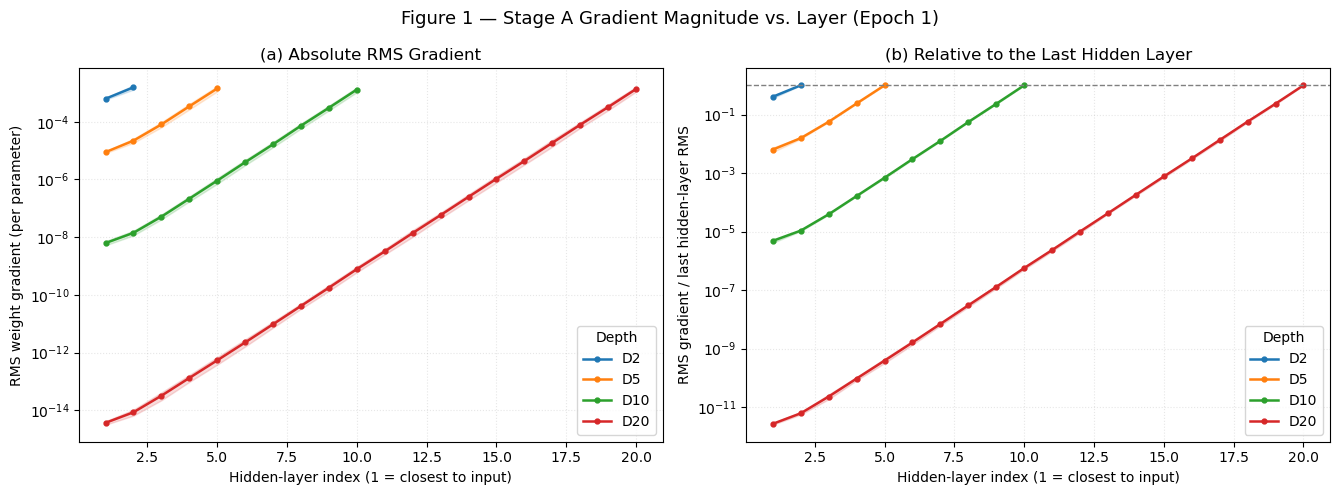

=== Figure 1 — First Hidden-Layer Gradient Summary (Epoch 1) ===
 depth  grad_mean  grad_std  ratio_mean  ratio_std
     2  6.259e-04 4.655e-05   4.070e-01  4.482e-02
     5  8.823e-06 7.251e-07   6.369e-03  1.129e-03
    10  6.227e-09 1.040e-09   4.837e-06  6.791e-07
    20  3.664e-15 5.195e-16   2.711e-12  1.922e-13

Figure 1 saved to: results/stage_a/figure1_gradient_vs_layer.png
Vector version saved to: results/stage_a/figure1_gradient_vs_layer.pdf
Section 6.4 completed — Figure 1 is ready for H1 analysis.


In [ ]:
# Select early-training RMS gradients recorded during the first 10 batches of epoch 1.
fig1_epoch = 1                                           # Compare all depths at the same training epoch
fig1_data = stage_a_gradients_df.loc[
    stage_a_gradients_df["epoch"] == fig1_epoch
].copy()                                                 # Copy the selected records without modifying Section 6.3 data

assert len(fig1_data) == len(cfg.seeds) * sum(cfg.depths)  # 3 seeds × (2 + 5 + 10 + 20) = 111 records
assert np.isfinite(fig1_data["mean_grad_rms"]).all()      # All recorded gradient magnitudes must be finite
assert (fig1_data["mean_grad_rms"] >= 0).all()             # RMS gradients cannot be negative


# Find the last hidden-layer RMS gradient within each depth-seed run.
last_hidden = fig1_data.loc[
    fig1_data["layer"] == fig1_data["depth"],
    ["depth", "seed", "mean_grad_rms"]
].rename(columns={"mean_grad_rms": "last_hidden_rms"})   

assert len(last_hidden) == len(cfg.depths) * len(cfg.seeds)  # Exactly one reference for each of the 12 runs

# Match each hidden layer with its own run's reference, then calculate relative gradient magnitude.
fig1_data = fig1_data.merge(
    last_hidden,
    on=["depth", "seed"],                                 # Match using BOTH depth and seed to avoid mixing runs
    validate="many_to_one"                               # Many layers must match exactly one reference row
)

fig1_data["relative_grad_rms"] = (
    fig1_data["mean_grad_rms"]
    / fig1_data["last_hidden_rms"].replace(0, np.nan)    # RMS(layer l) / RMS(last hidden layer); avoid division by zero
)


# Calculate mean ± sample standard deviation across the three seeds for each depth and hidden layer.
fig1_summary = (
    fig1_data.groupby(["depth", "layer"], as_index=False)  # Group matching hidden layers within each depth
    .agg(
        grad_mean=("mean_grad_rms", "mean"),                # Mean absolute RMS gradient across seeds
        grad_std=("mean_grad_rms", "std"),                  # Sample std of absolute RMS gradients
        ratio_mean=("relative_grad_rms", "mean"),           # Mean of per-run relative gradient ratios
        ratio_std=("relative_grad_rms", "std")              # Sample std of per-run relative ratios
    )
)


# Create one Figure 1 containing absolute and relative gradient comparisons.
fig, (ax_abs, ax_rel) = plt.subplots(1, 2, figsize=(13.5, 5))  

for depth in cfg.depths:

    rows = fig1_summary.loc[
        fig1_summary["depth"] == depth
    ].sort_values("layer")                                

    x = rows["layer"].to_numpy()                           
    grad_mean = rows["grad_mean"].to_numpy()               
    grad_std = rows["grad_std"].fillna(0).to_numpy()       
    ratio_mean = rows["ratio_mean"].to_numpy()            
    ratio_std = rows["ratio_std"].fillna(0).to_numpy()      

    # Panel (a): Plot absolute RMS gradients and their mean ± std bands.
    line, = ax_abs.plot(
        x, np.where(grad_mean > 0, grad_mean, np.nan),      # Log scale requires positive plotted values
        marker="o", markersize=3.5, linewidth=1.8,
        label=f"D{depth}"                                 
    )

    color = line.get_color()                              

    ax_abs.fill_between(
        x,
        np.where(grad_mean - grad_std > 0, grad_mean - grad_std, np.nan),  # Lower mean - std bound
        grad_mean + grad_std,                             # Upper mean + std bound
        color=color, alpha=0.16                            # Light shading for variability across seeds
    )

    # Panel (b): Plot relative gradients using the SAME depth color for easy comparison.
    ax_rel.plot(
        x, np.where(ratio_mean > 0, ratio_mean, np.nan),    
        marker="o", markersize=3.5, linewidth=1.8,
        color=color, label=f"D{depth}"
    )

    ax_rel.fill_between(
        x,
        np.where(ratio_mean - ratio_std > 0, ratio_mean - ratio_std, np.nan),  # Positive lower bound
        ratio_mean + ratio_std,                           # Upper mean + std bound
        color=color, alpha=0.16
    )


# Add scientific labels, logarithmic scales, and legends to both panels.
ax_abs.set_title("(a) Absolute RMS Gradient")
ax_abs.set_ylabel("RMS weight gradient (per parameter)")

ax_rel.set_title("(b) Relative to the Last Hidden Layer")
ax_rel.set_ylabel("RMS gradient / last hidden-layer RMS")
ax_rel.axhline(1.0, color="gray", linestyle="--", linewidth=1)  # Reference ratio of the last hidden layer

for ax in (ax_abs, ax_rel):
    ax.set_xlabel("Hidden-layer index (1 = closest to input)")
    ax.set_yscale("log")                                   
    ax.grid(True, which="both", linestyle=":", alpha=0.3)  
    ax.legend(title="Depth")                              

fig.suptitle(
    f"Figure 1 — Stage A Gradient Magnitude vs. Layer (Epoch {fig1_epoch})",
    fontsize=13
)
fig.tight_layout()                                        


# Save one publication-ready figure in both PNG and vector PDF formats.
fig1_dir = Path(cfg.results_dir) / "stage_a"               
fig1_dir.mkdir(parents=True, exist_ok=True)               

fig1_png = fig1_dir / "figure1_gradient_vs_layer.png"     
fig1_pdf = fig1_dir / "figure1_gradient_vs_layer.pdf"     

fig.savefig(fig1_png, dpi=300, bbox_inches="tight")       
fig.savefig(fig1_pdf, bbox_inches="tight")               
plt.show()                                                
plt.close(fig)                                            


# Display a compact table of first-hidden-layer gradients for comparing network depths.
fig1_first_layer = fig1_summary.loc[
    fig1_summary["layer"] == 1,
    ["depth", "grad_mean", "grad_std", "ratio_mean", "ratio_std"]
].copy()                                                   

print("=== Figure 1 — First Hidden-Layer Gradient Summary (Epoch 1) ===")
print(
    fig1_first_layer.to_string(
        index=False,
        float_format=lambda value: f"{value:.3e}"         
    )
)

# Report any exact-zero gradients, which cannot appear directly on logarithmic axes.
if (fig1_data["mean_grad_rms"] == 0).any():
    print("Note: Exact-zero RMS gradients are omitted from the log-scale curves.")

if (last_hidden["last_hidden_rms"] == 0).any():
    print("Note: Relative gradients are undefined when the last hidden-layer RMS is zero.")

print(f"\nFigure 1 saved to: {fig1_png}")
print(f"Vector version saved to: {fig1_pdf}")
print("Section 6.4 completed — Figure 1 is ready for H1 analysis.")


#### 6.4 — Results & Interpretation

**Implementation & Verification**

Figure 1 was generated from the recorded epoch-1 gradients of all 12 Stage A runs. Both absolute and relative RMS gradients were summarized across three seeds, and the figure was saved in PNG and PDF formats.

**Results & Key Observations**

- **Absolute gradients:** The mean first-layer RMS gradient decreased from \(6.259 \times 10^{-4}\) in D2 to \(3.664 \times 10^{-15}\) in D20, a difference of approximately 11 orders of magnitude.
- **Relative gradients:** The mean first-to-last hidden-layer RMS ratios decreased with depth:

  | Model | First-to-Last RMS Gradient Ratio |
  |---|---:|
  | D2 | \(4.070 \times 10^{-1}\) |
  | D5 | \(6.369 \times 10^{-3}\) |
  | D10 | \(4.837 \times 10^{-6}\) |
  | D20 | \(2.711 \times 10^{-12}\) |

- Both panels show progressively stronger attenuation toward earlier hidden layers in deeper networks, with relatively small variation across the three seeds.

**Interpretation — H1: Depth Effect**

The results provide strong empirical support for H1 under the fixed Sigmoid–Xavier–SGD configuration. Increasing network depth is associated with substantially smaller early-layer weight gradients, both in absolute magnitude and relative to the last hidden layer.

This pattern is consistent with vanishing gradients during backpropagation. Its relationship with training progress and first-layer weight displacement will be examined in Sections 6.5–6.7.

**Limitations**

Figure 1 uses only epoch-1 weight gradients, averaged over the first 10 training batches. These measurements establish the observed attenuation pattern but do not independently identify its underlying causes or demonstrate that gradient attenuation alone explains the differences in model performance.  

---  

### 6.5 — Figure 2: Gradient Evolution During Training

**Objective**

Examine whether the strong early-layer gradient attenuation observed in D20 persists throughout 20 training epochs.

**Procedure**

1. Retrieve D20's layer-wise RMS weight gradients from `stage_a_gradients_df` across all 20 epochs and three random seeds.
2. Calculate the mean RMS gradient across seeds for each hidden layer and epoch.
3. Organize the results into a 20 × 20 matrix (hidden layers × epochs) and apply `log10` to the mean gradients for visualization.
4. Generate a heatmap showing gradient magnitude across hidden layers and training epochs.
5. Save Figure 2 as PNG and PDF, and display the mean RMS gradients of Hidden Layers 1 and 20 at epochs 1, 10, and 20.

**Expected Results**

A 20 × 20 heatmap containing 400 mean RMS gradient measurements, with logarithmic coloring to display differences in gradient magnitude across layers and training epochs.

**Important Distinction**

Each epoch-level gradient is averaged over the first 10 training batches, not the entire epoch. The logarithmic transformation is applied after averaging gradients across seeds. Exact-zero values are displayed as gray cells.

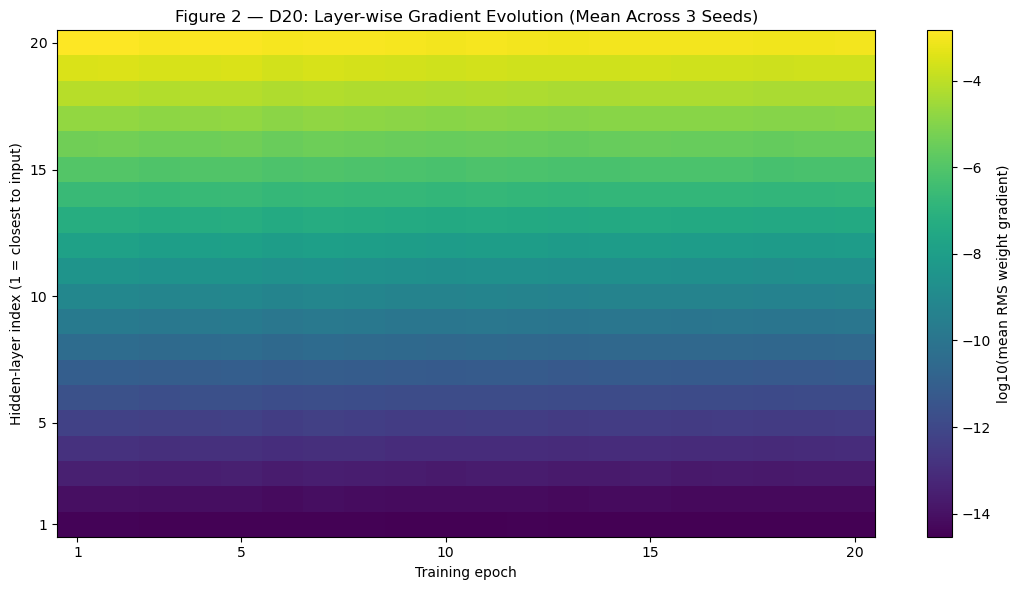

=== Figure 2 — Gradient Evolution Summary (D20, Mean Across 3 Seeds) ===
Epoch    Layer 1 RMS        Layer 20 RMS      
1        3.664e-15          1.362e-03         
10       3.236e-15          9.118e-04         
20       2.918e-15          8.794e-04         

Figure 2 saved to: results/stage_a/figure2_gradient_evolution_d20.png
PDF version saved to: results/stage_a/figure2_gradient_evolution_d20.pdf
Section 6.5 completed — Figure 2 is ready for H1 analysis.


In [ ]:
# Select the deepest Stage A network and its gradient measurements across all training epochs.
fig2_depth = max(cfg.depths)                         # D20: the deepest network in Stage A
fig2_data = stage_a_gradients_df.loc[
    stage_a_gradients_df["depth"] == fig2_depth
].copy()                                             

# Verify that all expected layer, epoch, and seed measurements are available.
expected_records = fig2_depth * cfg.epochs * len(cfg.seeds)  # 20 layers × 20 epochs × 3 seeds = 1200

assert len(fig2_data) == expected_records            
assert np.isfinite(fig2_data["mean_grad_rms"]).all()  
assert (fig2_data["mean_grad_rms"] >= 0).all()         


# Calculate the mean RMS gradient across three seeds for each hidden layer and epoch.
fig2_mean = (
    fig2_data.groupby(["layer", "epoch"], as_index=False)
    ["mean_grad_rms"].mean()                          
)

# Reshape the results into a matrix: rows = hidden layers, columns = training epochs.
fig2_grid = fig2_mean.pivot(
    index="layer",                                    
    columns="epoch",                                  
    values="mean_grad_rms"                            
).sort_index().sort_index(axis=1)                    

assert fig2_grid.shape == (fig2_depth, cfg.epochs)   
assert fig2_grid.notna().all().all()                 


# Convert gradient magnitudes to log10 so very small and large values remain distinguishable.
grad_values = fig2_grid.to_numpy(dtype=float)     
positive = grad_values > 0                           

fig2_log_values = np.full(grad_values.shape, np.nan) # Reserve NaN for exact-zero gradients
fig2_log_values[positive] = np.log10(
    grad_values[positive]                            
)

# Use gray for exact-zero gradients rather than assigning them an artificial positive value.
fig2_cmap = plt.get_cmap("viridis").copy()           
fig2_cmap.set_bad("lightgray")                       


# Create one heatmap showing how gradients evolve across hidden layers and training epochs.
fig, ax = plt.subplots(figsize=(11, 6))

heatmap = ax.imshow(
    fig2_log_values,                                 
    origin="lower",                                  
    aspect="auto",                                   
    interpolation="nearest",                         
    extent=[0.5, cfg.epochs + 0.5, 0.5, fig2_depth + 0.5],
    cmap=fig2_cmap                                   
)

# Add axis labels, integer tick marks, and a colorbar explaining the gradient magnitudes.
ax.set_title(
    f"Figure 2 — D{fig2_depth}: Layer-wise Gradient Evolution "
    f"(Mean Across {len(cfg.seeds)} Seeds)"
)
ax.set_xlabel("Training epoch")
ax.set_ylabel("Hidden-layer index (1 = closest to input)")

ax.set_xticks([1, 5, 10, 15, cfg.epochs])            
ax.set_yticks([1, 5, 10, 15, fig2_depth])            

fig.colorbar(
    heatmap, ax=ax,
    label="log10(mean RMS weight gradient)"           
)

fig.tight_layout()                                   


# Save Figure 2 using the same directory and image quality as Figure 1.
fig2_dir = Path(cfg.results_dir) / "stage_a"         
fig2_dir.mkdir(parents=True, exist_ok=True)          

fig2_png = fig2_dir / "figure2_gradient_evolution_d20.png"
fig2_pdf = fig2_dir / "figure2_gradient_evolution_d20.pdf"

fig.savefig(fig2_png, dpi=300, bbox_inches="tight")  
fig.savefig(fig2_pdf, bbox_inches="tight")           
plt.show()                                           
plt.close(fig)                                     


# Compare the first and last hidden-layer gradients at selected training epochs.
print("=== Figure 2 — Gradient Evolution Summary (D20, Mean Across 3 Seeds) ===")
print(f"{'Epoch':<8} {'Layer 1 RMS':<18} {'Layer 20 RMS':<18}")

for epoch in (1, 10, cfg.epochs):                    

    first_grad = fig2_grid.loc[1, epoch]             
    last_grad = fig2_grid.loc[fig2_depth, epoch]    

    print(
        f"{epoch:<8} "
        f"{first_grad:<18.3e} "                     
        f"{last_grad:<18.3e}"
    )

zero_count = (grad_values == 0).sum()                 

if zero_count > 0:
    print(f"Note: {zero_count} exact-zero values are shown as gray cells.")

print(f"\nFigure 2 saved to: {fig2_png}")
print(f"PDF version saved to: {fig2_pdf}")
print("Section 6.5 completed — Figure 2 is ready for H1 analysis.")



#### 6.5 — Results & Interpretation

**Implementation & Verification**

Figure 2 was generated from 1,200 recorded gradient measurements (20 hidden layers × 20 epochs × 3 seeds), aggregated into a 20 × 20 heatmap. The figure was saved in PNG and PDF formats.

**Results & Key Observations**

- **Persistent early-layer attenuation:** Hidden Layer 1 maintained extremely small mean RMS gradients, decreasing from $3.664 \times 10^{-15}$ at epoch 1 to $2.918 \times 10^{-15}$ at epoch 20.
- **Larger late-layer gradients:** Hidden Layer 20 maintained substantially larger RMS gradients, decreasing from $1.362 \times 10^{-3}$ to $8.794 \times 10^{-4}$.
- **Gradient evolution:** The heatmap shows relatively stable horizontal color bands across epochs, with an approximately 11–12-order-of-magnitude difference between the first and last hidden layers.

**Interpretation — H1: Depth Effect**

Figure 2 shows that severe early-layer gradient attenuation in D20 persisted throughout the 20-epoch training period.

Together with the cross-depth comparison in Figure 1, these findings support H1 under the fixed Sigmoid–Xavier–SGD configuration. The observed pattern is consistent with the vanishing-gradient phenomenon.

Persistent small early-layer gradients may limit SGD parameter updates, but their relationship with actual first-layer weight displacement will be examined in Section 6.7.

**Limitations**

The heatmap displays gradients averaged across three seeds and does not show between-seed variability. Measurements are based on the first 10 batches of each epoch and represent weight-gradient magnitudes, not cumulative parameter changes or direct evidence of causality.  

---  

### 6.6 — Figure 3: Training Loss Curves

**Objective**

Compare training-loss trajectories across D2, D5, D10, and D20 to examine how network depth affects optimization progress over 20 epochs.

**Procedure**

1. Retrieve the training-loss histories from `stage_a_history_df` for all 12 Stage A runs.  

2. Calculate the mean and sample standard deviation of training loss across three seeds for each depth and epoch.  

- For each depth $d$ and epoch $e$:

   $$
   \overline{L}_{d,e}
   = \frac{1}{3}\sum_{s=0}^{2}L_{d,s,e}
   $$

   $$
   SD_{d,e}
   = \sqrt{\frac{\sum_{s=0}^{2}(L_{d,s,e}-\overline{L}_{d,e})^2}{3-1}}
   $$

   where:
   - $d$: Network depth (2, 5, 10, or 20 hidden layers).
   - $e$: Training epoch (1–20).
   - $s$: Random seed (0, 1, or 2).
   - $L_{d,s,e}$: Mean training loss for one independent run at epoch $e$.
   - $\overline{L}_{d,e}$: Mean training loss across the three seeds.
   - $SD_{d,e}$: Sample standard deviation across seeds.  

3. Plot the four mean training-loss curves with ±1 standard deviation bands and a horizontal reference line at the predefined loss threshold of 1.50.  

4. Use `stage_a_summary_df` to report final training losses and epochs-to-threshold statistics for each depth.  

5. Save Figure 3 in PNG and PDF formats.  

**Expected Results**

- One figure showing four training-loss curves across 20 epochs, summarized over three seeds.
- A reference line at the fixed training-loss threshold of 1.50.
- A summary of final training loss, threshold attainment, and epochs-to-threshold for each network depth.
- Saved files: `figure3_training_loss_curves.png` and `figure3_training_loss_curves.pdf`.

**Important Distinction**

Training loss is averaged over batches processed while model parameters are being updated. The threshold of 1.50 is a comparative milestone, not an early-stopping criterion.

Epochs-to-threshold is calculated separately for each run before aggregation across seeds. Runs that do not reach the threshold within 20 epochs are reported as `"Not reached"`.

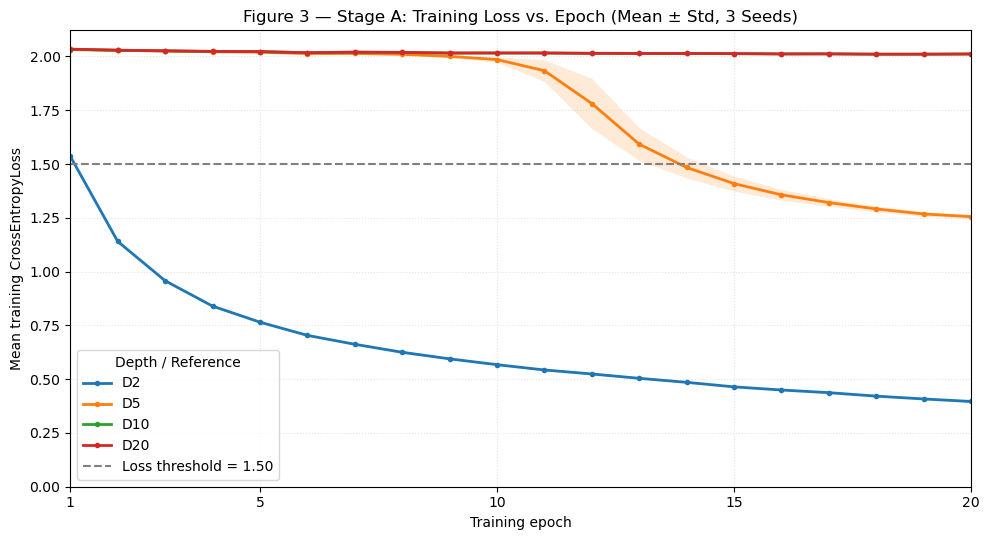

=== Figure 3 — Training Loss & Convergence Summary ===
 depth  train_loss_mean  train_loss_std  seeds_reached_threshold  epochs_to_threshold_mean  epochs_to_threshold_std
     2           0.3963          0.0065                        3                    2.0000                   0.0000
     5           1.2555          0.0086                        3                   14.6667                   0.5774
    10           2.0114          0.0013                        0               Not reached              Not reached
    20           2.0117          0.0014                        0               Not reached              Not reached

Figure 3 saved to: results/stage_a/figure3_training_loss_curves.png
PDF version saved to: results/stage_a/figure3_training_loss_curves.pdf
Section 6.6 completed — Figure 3 is ready for H2 analysis.


In [ ]:
# Reuse the training-loss histories collected from all 12 completed Stage A runs.
expected_rows = len(cfg.depths) * len(cfg.seeds) * cfg.epochs  # 4 depths × 3 seeds × 20 epochs = 240

assert len(stage_a_history_df) == expected_rows              
assert not stage_a_history_df[["depth", "seed", "epoch"]].duplicated().any()  
assert stage_a_history_df.groupby(["depth", "epoch"])["seed"].nunique().eq(len(cfg.seeds)).all()
assert np.isfinite(stage_a_history_df["train_loss"]).all()    
assert (stage_a_history_df["train_loss"] >= 0).all()           
assert cfg.loss_threshold is not None                         


# Calculate mean training loss and sample standard deviation across three seeds at each epoch.
fig3_loss_stats = (
    stage_a_history_df.groupby(["depth", "epoch"], as_index=False)  
    .agg(
        train_loss_mean=("train_loss", "mean"),                
        train_loss_std=("train_loss", "std")                  
    )
)

assert len(fig3_loss_stats) == len(cfg.depths) * cfg.epochs   # 4 depths × 20 epochs = 80 summary rows


# Plot training-loss trajectories for all four depths in one figure.
fig, ax = plt.subplots(figsize=(10, 5.5))                    

for depth in cfg.depths:                                    

    rows = fig3_loss_stats.loc[
        fig3_loss_stats["depth"] == depth
    ].sort_values("epoch")                                  

    x = rows["epoch"].to_numpy()                              
    loss_mean = rows["train_loss_mean"].to_numpy()            
    loss_std = rows["train_loss_std"].to_numpy()              

    # Plot the mean loss curve, then shade the region between mean - std and mean + std.
    line, = ax.plot(
        x, loss_mean,
        marker="o", markersize=3, linewidth=2,
        label=f"D{depth}"                                    
    )

    ax.fill_between(
        x,
        np.maximum(loss_mean - loss_std, 0),                  
        loss_mean + loss_std,                                
        color=line.get_color(), alpha=0.16, linewidth=0      
    )


# Mark the training-loss threshold fixed in Part 5; it does not stop training.
ax.axhline(
    y=cfg.loss_threshold,                                    
    color="gray", linestyle="--", linewidth=1.5,
    label=f"Loss threshold = {cfg.loss_threshold:.2f}"
)

# Format the axes and legend so changes in training loss are easy to compare.
ax.set_title("Figure 3 — Stage A: Training Loss vs. Epoch (Mean ± Std, 3 Seeds)")
ax.set_xlabel("Training epoch")
ax.set_ylabel("Mean training CrossEntropyLoss")

ax.set_xlim(1, cfg.epochs)                                   
ax.set_xticks([1, 5, 10, 15, cfg.epochs])                   
ax.set_ylim(bottom=0)                                     
ax.grid(True, linestyle=":", alpha=0.35)                     
ax.legend(title="Depth / Reference")                        

fig.tight_layout()                                   


# Save Figure 3 in the same Stage A results directory as Figures 1 and 2.
fig3_dir = Path(cfg.results_dir) / "stage_a"                 
fig3_dir.mkdir(parents=True, exist_ok=True)                

fig3_png = fig3_dir / "figure3_training_loss_curves.png"     
fig3_pdf = fig3_dir / "figure3_training_loss_curves.pdf"     

fig.savefig(fig3_png, dpi=300, bbox_inches="tight")         
fig.savefig(fig3_pdf, bbox_inches="tight")                   
plt.show()                                                  
plt.close(fig)                                            


# Review the final training losses and threshold attainment already calculated in Section 6.3.
print("=== Figure 3 — Training Loss & Convergence Summary ===")
print(
    stage_a_summary_df[[
        "depth",
        "train_loss_mean", "train_loss_std",                  # Final epoch-20 training loss: mean ± std
        "seeds_reached_threshold",                           # Number of seeds reaching loss <= 1.50
        "epochs_to_threshold_mean",                          # Average first-reaching epoch among successful runs
        "epochs_to_threshold_std"                            # Variation in reaching epochs among successful runs
    ]].to_string(
        index=False,
        float_format=lambda value: f"{value:.4f}",
        na_rep="Not reached"                                 
    )
)

print(f"\nFigure 3 saved to: {fig3_png}")
print(f"PDF version saved to: {fig3_pdf}")
print("Section 6.6 completed — Figure 3 is ready for H2 analysis.")



#### 6.6 — Results & Interpretation

**Implementation & Verification**

Figure 3 was generated from 240 training-loss records across 12 Stage A runs, summarized into 80 depth–epoch measurements. The figure was saved in PNG and PDF formats.

**Results & Key Observations**

- **D2:** Showed rapid and sustained training-loss reduction, reaching a final mean loss of 0.3963 ± 0.0065. All three seeds reached the threshold of 1.50 at epoch 2.  

- **D5:** Showed delayed loss reduction after approximately 9–10 epochs, reaching a final mean loss of 1.2555 ± 0.0086. All three seeds reached the threshold at epochs 14–15 (mean 14.67 ± 0.58).  

- **D10 and D20:** Maintained nearly flat training-loss curves, ending at 2.0114 ± 0.0013 and 2.0117 ± 0.0014, respectively. Neither model reached the threshold within 20 epochs for any seed.

**Interpretation — H2: Early-Layer Trainability**

Figure 3 shows progressively slower training-loss reduction as network depth increases under the fixed Sigmoid–Xavier–SGD configuration.

Together with the gradient attenuation observed in Figures 1 and 2, these results support an association between smaller early-layer gradients and reduced optimization progress.

The training-loss results support the convergence-related component of H2. Section 6.7 will examine first-layer weight displacement to assess the parameter-change component directly.

**Limitations**

The training-loss threshold is a predefined comparison metric, not proof of complete convergence. The observed relationship between gradient attenuation and slower learning does not independently establish causality.  

---  

### 6.7 — Early-Layer Weight Change Analysis

**Objective**

Compare normalized first-layer weight displacement across D2, D5, D10, and D20 to examine whether stronger early-layer gradient attenuation is associated with smaller parameter changes (H2).

**Procedure**

1. Retrieve the recorded first-layer weight changes from `stage_a_weights_df` for all 12 Stage A runs.
2. Calculate the mean and sample standard deviation across three seeds for each depth and epoch.
3. Examine normalized first-layer weight displacement at epochs 1, 10, and 20, using:

   $$
   C_{1,e} = \frac{\|W_1^{(e)}-W_1^{(0)}\|_F}{\|W_1^{(0)}\|_F}
   $$

   where $W_1^{(0)}$ is the initial first-layer weight matrix and $W_1^{(e)}$ is its value after epoch $e$.

4. Compare final weight displacement at epoch 20 with the first-layer RMS gradients measured during epoch 1, using `stage_a_summary_df`.
5. Verify that the final measurements agree with the existing summaries and identify any exact-zero recorded weight changes.

**Expected Results**

- A summary of normalized first-layer weight displacement at epochs 1, 10, and 20.
- A comparison of epoch-1 first-layer RMS gradients, final weight displacement, and training-loss threshold attainment across four depths.
- Mean ± sample standard deviation across three seeds, without additional training or gradient computation.

**Important Distinction**

Normalized weight displacement measures net movement from initialization, not the sum of individual SGD updates. Exact-zero recorded displacement may reflect floating-point precision and does not necessarily indicate zero gradients.

In [ ]:
# Reuse the cumulative first-layer weight changes recorded during the 12 Stage A runs.
expected_rows = len(cfg.depths) * len(cfg.seeds) * cfg.epochs  

assert len(stage_a_weights_df) == expected_rows               
assert not stage_a_weights_df[["depth", "seed", "epoch"]].duplicated().any() 
assert np.isfinite(stage_a_weights_df["first_layer_weight_change"]).all()  
assert (stage_a_weights_df["first_layer_weight_change"] >= 0).all()        


# Summarize cumulative first-layer weight changes across seeds for every depth and epoch.
stage_a_weight_evolution_df = (
    stage_a_weights_df.groupby(["depth", "epoch"], as_index=False)  
    .agg(
        weight_change_mean=("first_layer_weight_change", "mean"),  
        weight_change_std=("first_layer_weight_change", "std"),    
        n_seeds=("seed", "nunique")                                 
    )
)

assert len(stage_a_weight_evolution_df) == len(cfg.depths) * cfg.epochs  
assert (stage_a_weight_evolution_df["n_seeds"] == len(cfg.seeds)).all()  


# Inspect how the first-layer weight changes develop during early, middle, and late training.
selected_epochs = sorted({1, min(10, cfg.epochs), cfg.epochs})  

weight_checkpoints = stage_a_weight_evolution_df.loc[
    stage_a_weight_evolution_df["epoch"].isin(selected_epochs),
    ["depth", "epoch", "weight_change_mean", "weight_change_std"]
].copy()                                                        

print("=== Section 6.7 — First-Layer Weight Change Across Training ===")
print("Metric: ||W1(epoch) - W1(initial)|| / ||W1(initial)||")
print("Values: Mean ± sample standard deviation across 3 seeds\n")

print(
    weight_checkpoints.to_string(
        index=False,
        float_format=lambda value: f"{value:.3e}"                
    )
)


# Reuse the final statistics and early gradient measurements already calculated in Section 6.3.
weight_comparison = stage_a_summary_df[[
    "depth", "n_seeds",
    "grad_rms_l1_epoch1_mean", "grad_rms_l1_epoch1_std",          
    "weight_change_l1_final_mean", "weight_change_l1_final_std", 
    "seeds_reached_threshold"                                   
]].copy()                                                        


# Verify that the final weight-change means agree with the epoch-20 measurements.
final_weight_stats = stage_a_weight_evolution_df.loc[
    stage_a_weight_evolution_df["epoch"] == cfg.epochs
].sort_values("depth")                                         

assert np.allclose(
    final_weight_stats["weight_change_mean"].to_numpy(),
    weight_comparison.sort_values("depth")["weight_change_l1_final_mean"].to_numpy(),
    rtol=1e-6, atol=0.0                                       
)


# Display the measurements needed to assess the parameter-change component of H2.
print("\n=== Stage A — Gradient Attenuation vs. First-Layer Weight Change ===")
print("Gradients: Epoch 1 | Weight changes: After Epoch 20\n")

with pd.option_context("display.float_format", "{:.3e}".format):
    display(weight_comparison)                                 


# Identify any runs with an exact-zero cumulative first-layer weight change.
zero_change_runs = (
    stage_a_run_summary_df["weight_change_l1_final"] == 0
).sum()                                                        

if zero_change_runs > 0:
    print(
        f"\nNote: {zero_change_runs} run(s) recorded an exact-zero final first-layer weight change."
    )
    print("Extremely small SGD updates may be rounded away at floating-point precision.")

print("\nSection 6.7 completed — First-layer weight changes are ready for H2 analysis.")



=== Section 6.7 — First-Layer Weight Change Across Training ===
Metric: ||W1(epoch) - W1(initial)|| / ||W1(initial)||
Values: Mean ± sample standard deviation across 3 seeds

 depth  epoch  weight_change_mean  weight_change_std
     2      1           7.854e-02          1.657e-03
     2     10           2.331e-01          2.595e-03
     2     20           3.279e-01          2.546e-03
     5      1           2.318e-03          2.020e-04
     5     10           4.004e-02          5.862e-03
     5     20           1.090e-01          4.262e-03
    10      1           1.519e-06          4.733e-07
    10     10           1.458e-05          4.346e-06
    10     20           2.740e-05          8.056e-06
    20      1           0.000e+00          0.000e+00
    20     10           0.000e+00          0.000e+00
    20     20           0.000e+00          0.000e+00

=== Stage A — Gradient Attenuation vs. First-Layer Weight Change ===
Gradients: Epoch 1 | Weight changes: After Epoch 20



,depth,n_seeds,grad_rms_l1_epoch1_mean,grad_rms_l1_epoch1_std,weight_change_l1_final_mean,weight_change_l1_final_std,seeds_reached_threshold
0,2,3,6.259e-04,4.655e-05,3.279e-01,2.546e-03,3
1,5,3,8.823e-06,7.251e-07,1.090e-01,4.262e-03,3
2,10,3,6.227e-09,1.040e-09,2.740e-05,8.056e-06,0
3,20,3,3.664e-15,5.195e-16,0.000e+00,0.000e+00,0



Note: 3 run(s) recorded an exact-zero final first-layer weight change.
Extremely small SGD updates may be rounded away at floating-point precision.

Section 6.7 completed — First-layer weight changes are ready for H2 analysis.
Next: Section 6.8 — Validation Performance & Convergence.


#### 6.7 — Results & Interpretation

**Implementation & Verification**

First-layer weight changes from all 12 Stage A runs were summarized across three seeds. The final measurements matched the existing Stage A summaries, and three D20 runs recorded exact-zero final displacement.

**Results & Key Observations**

- **D2:** Showed the largest first-layer weight displacement, increasing from $7.854 \times 10^{-2}$ at epoch 1 to $3.279 \times 10^{-1}$ at epoch 20.  

- **D5:** Showed smaller displacement, reaching $1.090 \times 10^{-1}$ at epoch 20.  

- **D10:** Exhibited very limited first-layer movement, with a final displacement of $2.740 \times 10^{-5}$, approximately 12,000 times smaller than D2.  

- **D20:** Recorded zero first-layer weight displacement across all three seeds at epoch 20, despite having nonzero measured gradients.

The decrease in first-layer weight displacement with increasing depth was consistent with the smaller early-layer RMS gradients and slower training-loss reduction observed in previous sections.

**Interpretation — H2: Early-Layer Trainability**

The results support the parameter-change component of H2 under the fixed Sigmoid–Xavier–SGD configuration. Networks with stronger early-layer gradient attenuation exhibited substantially smaller normalized first-layer weight displacement.

Combined with Figure 3, these findings support an association between gradient attenuation, reduced early-layer weight movement, and slower optimization.

**Limitations**

D20's zero recorded displacement may result from extremely small SGD updates being lost to floating-point rounding; this explanation has not been independently verified. The metric measures net displacement of Hidden Layer 1 only, and the observed associations do not establish gradient attenuation as the sole cause of optimization difficulty.  

---  

### 6.8 — Validation Performance & Convergence

**Objective**

Summarize and compare the final training loss, validation performance, and convergence behavior of D2, D5, D10, and D20 across three random seeds.

**Procedure**

1. Retrieve the aggregated results from `stage_a_summary_df` without retraining or reevaluating any models.
2. Report final training loss, validation loss, accuracy, and macro-F1 as mean ± sample standard deviation across three seeds.
3. Include epochs-to-threshold using the predefined training-loss threshold of 1.50, along with the number of seeds reaching it within 20 epochs.
4. Create a formatted Stage A results table while preserving the original numerical DataFrame.
5. Save the table as `stage_a_results_table.csv`.

**Expected Results**

A consolidated table with one row per network depth, reporting final training and validation metrics, epochs-to-threshold, and threshold-attainment counts.

All values are based on the completed 20-epoch Stage A runs. No additional training or evaluation is performed.

In [ ]:
# Reuse the final Stage A metrics already aggregated across three seeds in Section 6.3.
assert set(stage_a_summary_df["depth"]) == set(cfg.depths)  
assert (stage_a_summary_df["n_seeds"] == len(cfg.seeds)).all()  
assert stage_a_summary_df["seeds_reached_threshold"].between(0, len(cfg.seeds)).all()

# Confirm that the main performance metrics are valid before preparing the report table.
metric_columns = [
    "train_loss_mean", "val_loss_mean",
    "val_accuracy_mean", "val_macro_f1_mean"
]

assert np.isfinite(stage_a_summary_df[metric_columns].to_numpy()).all() 
assert stage_a_summary_df["val_accuracy_mean"].between(0, 1).all()    
assert stage_a_summary_df["val_macro_f1_mean"].between(0, 1).all()     


# Prepare one formatted results row per depth using the statistics already calculated in Section 6.3.
results_rows = []                                    

for _, row in stage_a_summary_df.sort_values("depth").iterrows():

    depth = int(row["depth"])                            
    n_seeds = int(row["n_seeds"])                      
    n_reached = int(row["seeds_reached_threshold"])    

    # Format epochs-to-threshold without assigning artificial values to unsuccessful runs.
    if n_reached == 0:
        threshold_text = "Not reached"                  

    elif n_reached == 1:
        threshold_text = f"{row['epochs_to_threshold_mean']:.2f} (SD N/A)"  # One qualifying run has no sample std

    else:
        threshold_text = (
            f"{row['epochs_to_threshold_mean']:.2f} ± "
            f"{row['epochs_to_threshold_std']:.2f}"    
        )

    # Collect final loss, validation metrics, and convergence status for the current network depth.
    results_rows.append({
        "Model": f"D{depth}",                            # D2, D5, D10, or D20
        "Train Loss": f"{row['train_loss_mean']:.4f} ± {row['train_loss_std']:.4f}",
        "Val Loss": f"{row['val_loss_mean']:.4f} ± {row['val_loss_std']:.4f}",
        "Val Accuracy": f"{row['val_accuracy_mean']:.4f} ± {row['val_accuracy_std']:.4f}",
        "Val Macro-F1": f"{row['val_macro_f1_mean']:.4f} ± {row['val_macro_f1_std']:.4f}",
        "Epochs to Threshold": threshold_text,           
        "Seeds Reached": f"{n_reached}/{n_seeds}"      
    })


# Create one publication-friendly table without modifying the original numeric DataFrame.
stage_a_results_table = pd.DataFrame(results_rows)  

assert len(stage_a_results_table) == len(cfg.depths)   


# Save the formatted table for the technical report and subsequent Stage A interpretation.
stage_a_output_dir = Path(cfg.results_dir) / "stage_a" 
stage_a_output_dir.mkdir(parents=True, exist_ok=True)

results_table_path = stage_a_output_dir / "stage_a_results_table.csv"

stage_a_results_table.to_csv(
    results_table_path, index=False                   
)


# Display the complete validation and convergence comparison.
print("=== Section 6.8 — Stage A Validation Performance & Convergence ===")
print(f"Depths: {cfg.depths} | Seeds: {cfg.seeds} | Epochs: {cfg.epochs}")
print(f"Training-loss threshold: {cfg.loss_threshold:.2f}")
print("Metrics: Final epoch (Mean ± sample std across seeds)\n")

display(stage_a_results_table)                         

print(f"\nResults table saved to: {results_table_path}")
print("Section 6.8 completed — Validation and convergence results are ready for Stage A interpretation.")



=== Section 6.8 — Stage A Validation Performance & Convergence ===
Depths: (2, 5, 10, 20) | Seeds: (0, 1, 2) | Epochs: 20
Training-loss threshold: 1.50
Metrics: Final epoch (Mean ± sample std across seeds)



,Model,Train Loss,Val Loss,Val Accuracy,Val Macro-F1,Epochs to Threshold,Seeds Reached
0,D2,0.3963 ± 0.0065,0.5104 ± 0.0266,0.8123 ± 0.0112,0.7851 ± 0.0208,2.00 ± 0.00,3/3
1,D5,1.2555 ± 0.0086,1.2689 ± 0.0228,0.4663 ± 0.0195,0.3377 ± 0.0213,14.67 ± 0.58,3/3
2,D10,2.0114 ± 0.0013,2.0148 ± 0.0040,0.1820 ± 0.0126,0.0385 ± 0.0022,Not reached,0/3
3,D20,2.0117 ± 0.0014,2.0157 ± 0.0045,0.1820 ± 0.0126,0.0385 ± 0.0022,Not reached,0/3



Results table saved to: results/stage_a/stage_a_results_table.csv
Section 6.8 completed — Validation and convergence results are ready for Stage A interpretation.
Next: Section 6.9 — Stage A Findings & Interpretation.


#### 6.8 — Results & Interpretation

**Implementation & Verification**

Final training, validation, and convergence results from all 12 Stage A runs were consolidated into one table and saved to `results/stage_a/stage_a_results_table.csv`.

**Results & Key Observations**

- **D2:** Achieved the highest mean validation accuracy (0.8123 ± 0.0112) and macro-F1 (0.7851 ± 0.0208). All three seeds reached the training-loss threshold at epoch 2. 
 
- **D5:** Achieved lower validation accuracy (0.4663 ± 0.0195) and macro-F1 (0.3377 ± 0.0213). All three seeds reached the threshold at epochs 14–15.  

- **D10 and D20:** Both reported mean validation accuracy of 0.1820 ± 0.0126 and macro-F1 of 0.0385 ± 0.0022. Neither depth reached the threshold within 20 epochs.

**Interpretation**

Validation performance deteriorated substantially with increasing depth under the fixed Sigmoid–Xavier–SGD configuration.

These results are consistent with the slower training-loss reduction observed in Figure 3 and the reduced first-layer weight displacement measured in Section 6.7.

Together, the findings support an association between stronger early-layer gradient attenuation, reduced trainability, and poorer classification performance. The combined evidence for H1 and H2 will be evaluated in Section 6.9.

**Limitations**

The results reflect a fixed 20-epoch training budget and three random seeds. Identical aggregate validation metrics for D10 and D20 do not establish identical predictions. Poor validation performance alone does not identify gradient vanishing as the sole cause.

### 6.9 — Stage A Findings & Interpretation

**Objective**

Integrate the gradient, first-layer weight displacement, training-loss, and validation results to evaluate the two Stage A hypotheses:

- **H1 — Depth Effect:** Increasing network depth is associated with stronger early-layer gradient attenuation.
- **H2 — Early-Layer Trainability:** Stronger gradient attenuation is associated with smaller first-layer weight displacement and slower training-loss reduction.

**Procedure**

1. Retrieve the aggregated results from `stage_a_summary_df` and the relative gradient ratios from `fig1_summary`.
2. Verify that all four network depths and three random seeds are represented.
3. Compare first-layer RMS gradients and first-to-last hidden-layer gradient ratios to assess H1.
4. Compare normalized first-layer weight displacement, training-loss reduction, and epochs-to-threshold to assess H2.
5. Review validation accuracy and macro-F1 as complementary measures of classification performance.

**Expected Results**

A consolidated summary of gradient attenuation, first-layer weight displacement, training-loss convergence, and validation performance across D2, D5, D10, and D20.

The results provide the evidence needed to evaluate H1 and H2, discuss the experimental limitations, and inform depth selection for Stage B.

No additional training or gradient computation is performed.

In [ ]:
# Verify that all Stage A depths and seeds are represented in the completed results.
assert set(stage_a_summary_df["depth"]) == set(cfg.depths)  
assert not stage_a_summary_df["depth"].duplicated().any()   
assert (stage_a_summary_df["n_seeds"] == len(cfg.seeds)).all()  

# Check that the main measurements are finite; a zero weight change is a valid recorded value.
evidence_columns = [
    "grad_rms_l1_epoch1_mean",          
    "weight_change_l1_final_mean",      
    "train_loss_mean",                  
    "val_accuracy_mean",               
    "val_macro_f1_mean"                
]

assert np.isfinite(stage_a_summary_df[evidence_columns].to_numpy()).all()


# Reuse the normalized gradient ratios calculated for Figure 1 in Section 6.4.
first_layer_ratios = fig1_summary.loc[
    fig1_summary["layer"] == 1,
    ["depth", "ratio_mean"]
].copy()                                

assert set(first_layer_ratios["depth"]) == set(cfg.depths)  
assert not first_layer_ratios["depth"].duplicated().any()    

ratio_by_depth = first_layer_ratios.set_index("depth")["ratio_mean"]  

assert np.isfinite(ratio_by_depth.to_numpy()).all()  


# Review H1 and H2 evidence using the same measurements reported in earlier sections.
print("=== Section 6.9 — Stage A Findings & Interpretation ===")
print(f"Depths: {cfg.depths} | Seeds: {cfg.seeds} | Epochs: {cfg.epochs}")
print(f"Activation: Sigmoid | Initialization: Xavier | SGD LR: {cfg.lr}")
print(f"Training-loss threshold: {cfg.loss_threshold:.2f}")
print("\nMeasurements: Mean across 3 seeds (refer to Sections 6.3–6.8 for standard deviations)")

for _, row in stage_a_summary_df.sort_values("depth").iterrows():

    depth = int(row["depth"])                         
    n_reached = int(row["seeds_reached_threshold"])   
    n_seeds = int(row["n_seeds"])                     

    # Describe convergence without assigning artificial epochs to unsuccessful runs.
    if n_reached == 0:
        threshold_text = "Not reached"               

    elif n_reached == 1:
        threshold_text = f"{row['epochs_to_threshold_mean']:.2f} (SD N/A)"

    else:
        threshold_text = (
            f"{row['epochs_to_threshold_mean']:.2f} ± "
            f"{row['epochs_to_threshold_std']:.2f}"  
        )

    # Present gradient, parameter-change, convergence, and validation evidence together.
    print(f"\n--- D{depth} | {n_seeds} seeds ---")

    print(
        f"H1 | First-layer RMS gradient (epoch 1): "
        f"{row['grad_rms_l1_epoch1_mean']:.3e}"
    )                                                  

    print(
        f"H1 | First-to-last hidden-layer RMS ratio: "
        f"{ratio_by_depth.loc[depth]:.3e}"
    )                                                  

    print(
        f"H2 | Final normalized first-layer weight change: "
        f"{row['weight_change_l1_final_mean']:.3e}"
    )                                                  # ||W1(20) - W1(0)|| / ||W1(0)||

    print(
        f"H2 | Final train loss: {row['train_loss_mean']:.4f} | "
        f"Threshold reached: {n_reached}/{n_seeds} | "
        f"Epochs to threshold: {threshold_text}"
    )                                                  

    print(
        f"Validation | Accuracy: {row['val_accuracy_mean']:.4f} | "
        f"Macro-F1: {row['val_macro_f1_mean']:.4f}"
    )                                                  


# Identify the evidence needed for the Stage A research conclusions.
print("\n=== Stage A Interpretation Checklist ===")
print("H1: Compare the first-layer RMS gradients and first-to-last gradient ratios across depths.")
print("H1: Use Figure 2 to examine whether severe attenuation persists during training.")
print("H2: Compare early-layer weight changes with training-loss trajectories and threshold attainment.")
print("Performance: Compare validation accuracy and macro-F1 across depths.")
print("Limitations: Distinguish measured associations from causal explanations.")

print("\nSection 6.9 completed — Stage A evidence is ready for final interpretation.")



=== Section 6.9 — Stage A Findings & Interpretation ===
Depths: (2, 5, 10, 20) | Seeds: (0, 1, 2) | Epochs: 20
Activation: Sigmoid | Initialization: Xavier | SGD LR: 0.1
Training-loss threshold: 1.50

Measurements: Mean across 3 seeds (refer to Sections 6.3–6.8 for standard deviations)

--- D2 | 3 seeds ---
H1 | First-layer RMS gradient (epoch 1): 6.259e-04
H1 | First-to-last hidden-layer RMS ratio: 4.070e-01
H2 | Final normalized first-layer weight change: 3.279e-01
H2 | Final train loss: 0.3963 | Threshold reached: 3/3 | Epochs to threshold: 2.00 ± 0.00
Validation | Accuracy: 0.8123 | Macro-F1: 0.7851

--- D5 | 3 seeds ---
H1 | First-layer RMS gradient (epoch 1): 8.823e-06
H1 | First-to-last hidden-layer RMS ratio: 6.369e-03
H2 | Final normalized first-layer weight change: 1.090e-01
H2 | Final train loss: 1.2555 | Threshold reached: 3/3 | Epochs to threshold: 14.67 ± 0.58
Validation | Accuracy: 0.4663 | Macro-F1: 0.3377

--- D10 | 3 seeds ---
H1 | First-layer RMS gradient (epoch 1): 

#### 6.9 — Results & Stage A Conclusions

**Implementation & Verification**

Results from all 12 Stage A runs were consolidated using the existing gradient, weight-change, training-loss, and validation summaries. No additional experiments were performed.

**Key Findings**

- **Gradient attenuation:** The mean first-layer RMS gradient decreased from $6.259 \times 10^{-4}$ in D2 to $3.664 \times 10^{-15}$ in D20. The corresponding first-to-last hidden-layer gradient ratio decreased from 0.4070 to $2.711 \times 10^{-12}$.  

- **Gradient evolution:** Figure 2 showed that extremely small early-layer gradients persisted in D20 throughout 20 training epochs.  

- **First-layer weight displacement:** Final normalized weight change decreased from 0.3279 (D2) to 0.1090 (D5), $2.740 \times 10^{-5}$ (D10), and 0 (D20).  

- **Training-loss reduction:** D2 reached the threshold of 1.50 at epoch 2 across all seeds. D5 reached it at epochs 14–15, while D10 and D20 did not reach it within 20 epochs.  

- **Validation performance:** Mean validation accuracy decreased from 81.23% in D2 to 46.63% in D5 and 18.20% in both D10 and D20.

**Interpretation — H1: Depth Effect**

The results strongly support H1 under the tested Sigmoid–Xavier–SGD configuration. Increasing depth was associated with substantially smaller early-layer weight gradients, both in absolute magnitude and relative to later hidden layers.

The persistent attenuation observed in D20 is consistent with the vanishing-gradient phenomenon.

**Interpretation — H2: Early-Layer Trainability**

The results also support H2. Models with stronger early-layer gradient attenuation exhibited smaller first-layer weight displacement and slower training-loss reduction.

Together, these measurements indicate an association between gradient attenuation and reduced early-layer trainability. However, they do not establish gradient vanishing as the sole cause of poor optimization or validation performance.

**Limitations**

The findings are based on BloodMNIST, one constant-width MLP architecture family, three random seeds, and a fixed 20-epoch Sigmoid–Xavier–SGD protocol. Parameter counts also increase with depth.

D20's exact-zero recorded first-layer weight displacement may reflect floating-point rounding, but this explanation was not independently verified.

**Stage A Conclusion**

Stage A provides consistent empirical evidence for H1 and H2 under the tested conditions.

The results motivate selecting a network depth that exhibits meaningful gradient attenuation while retaining measurable learning progress for the Stage B activation-function comparison.  

---  

## Part 7 — Stage B: Activation Function Experiment

### 1. Overview & Objectives

Stage B investigates how activation functions affect gradient propagation, early-layer trainability, and optimization in MLPs trained on BloodMNIST.

Based on the Stage A findings, three activation functions—**Sigmoid, Tanh, and ReLU**—are compared at a fixed depth of **D5 (five hidden layers)**.

The experiment evaluates **H3 — Activation Effect:** Whether changing the activation function is associated with differences in layer-wise RMS gradients, first-layer weight displacement, training-loss reduction, and validation performance.

All models use the same architecture (hidden width 256), Xavier Uniform initialization (gain = 1), and plain SGD with learning rate 0.1. Each model is trained for 20 epochs using seeds 0, 1, and 2.

The comparison contains **nine activation–seed results**: three existing D5 Sigmoid runs from Stage A and six new Tanh and ReLU runs.

### 2. Workflow & Section Guide

| Section | Main Task |
|---|---|
| **7.1 — Depth Selection for Stage B** | Review Stage A findings and select D5 for the activation comparison. |
| **7.2 — Controlled Activation Setup** | Verify the D5 architecture, parameter counts, activation functions, and initialization consistency. |
| **7.3 — Single-Seed Activation Comparison** | Train D5 with Tanh and ReLU using seed 0. |
| **7.4 — Complete Multi-Seed Runs** | Complete the remaining Tanh and ReLU runs using seeds 1 and 2. |
| **7.5 — Organize & Aggregate Results** | Prepare analysis DataFrames and calculate mean ± sample standard deviation across seeds. |
| **7.6 — Gradient Propagation & Trainability Analysis** | Compare gradients, first-layer weight displacement, training-loss behavior, and validation performance across activations. |
| **7.7 — Stage B Findings & Interpretation** | Integrate the evidence to evaluate H3 and discuss limitations. |

Sections 7.1–7.4 establish and complete the controlled activation experiment. Sections 7.5–7.7 organize, analyze, and interpret the results.

### 3. Important Objects & Their Roles

| Object / Measurement | Role |
|---|---|
| `stage_a_runs` | Provide the three completed D5 Sigmoid baseline runs. |
| `stage_b_runs` | Store the nine activation–seed results for Stage B. |
| `run_training()` | Train new Tanh and ReLU models using the established experimental protocol. |
| Layer-wise RMS gradients | Compare absolute and relative gradient magnitudes across the five hidden layers. |
| First-to-last gradient ratio | Measure early-layer gradient attenuation relative to the final hidden layer. |
| Normalized first-layer weight displacement | Compare first-layer parameter movement from initialization. |
| Training loss and epochs-to-threshold | Compare optimization progress using the fixed loss threshold of 1.50. |
| Validation metrics | Compare validation loss, accuracy, and macro-F1. |

**Experimental controls:**

- **Fixed architecture:** D5, hidden width 256, and 867,592 trainable parameters.
- **Initialization:** Xavier Uniform (gain = 1), with zero biases for all activations.
- **Optimizer:** SGD, learning rate 0.1, momentum 0, and weight decay 0.
- **Training:** Batch size 128, 20 epochs, and seeds 0, 1, 2.
- **Gradient recording:** First 100 global steps and first 10 batches of each epoch.

### 4. Expected Outcomes & Role in the Experiment

Stage B produces a controlled comparison of Sigmoid, Tanh, and ReLU at fixed D5 depth, summarized across three random seeds.

The analysis evaluates whether activation choice is associated with differences in gradient attenuation, first-layer weight displacement, training-loss reduction, and validation performance.

The shared Xavier Uniform initialization allows activation functions to be compared under the same initialization rule, although this rule may not be optimal for every activation.

The results provide evidence for evaluating H3 under the tested D5–Xavier–SGD configuration. Part 8 will integrate the findings from Stage A and Stage B into the final experimental conclusions.

The official BloodMNIST test split remains unused in these comparisons.  

---  

### 7.1 — Depth Selection for Stage B

**Objective**

Select a fixed network depth for Stage B that exhibits substantial early-layer gradient attenuation while retaining measurable training progress.

**Procedure**

1. Retrieve the Stage A results from `stage_a_summary_df` and the relative gradient ratios from `fig1_summary`.
2. Compare D5, D10, and D20 using first-layer RMS gradients, first-to-last gradient ratios, normalized first-layer weight displacement, training-loss reduction, and validation performance.
3. Review threshold attainment across three seeds using the fixed training-loss threshold of 1.50.
4. Select D5 based on the balance between gradient attenuation and trainability, and verify that its relative gradient ratio is smaller than D2's and all three seeds reached the threshold.
5. Store the selected depth in `stage_b_depth`.

**Expected Results**

D5 is selected as the fixed architecture for Stage B, supported by substantial gradient attenuation and measurable training progress across three seeds.

No additional training or gradient computation is performed.

In [ ]:
# Select the deep-network candidates using the completed Stage A results.
candidate_depths = (5, 10, 20)

candidate_summary = stage_a_summary_df.loc[
    stage_a_summary_df["depth"].isin(candidate_depths),
    [
        "depth",
        "n_seeds",
        "grad_rms_l1_epoch1_mean",
        "weight_change_l1_final_mean",
        "train_loss_mean",
        "seeds_reached_threshold",
        "epochs_to_threshold_mean",
        "val_accuracy_mean",
        "val_macro_f1_mean"
    ]
].copy()


# Reuse the first-to-last hidden-layer gradient ratios from Stage A Figure 1.
gradient_ratios = fig1_summary.loc[
    fig1_summary["layer"] == 1,
    ["depth", "ratio_mean"]
].rename(
    columns={"ratio_mean": "first_to_last_gradient_ratio"}
)

candidate_summary = candidate_summary.merge(
    gradient_ratios,                 
    on="depth",                     
    validate="one_to_one"           
).sort_values("depth")

assert set(candidate_summary["depth"]) == set(candidate_depths)
assert (candidate_summary["n_seeds"] == len(cfg.seeds)).all()


# Display the evidence for selecting the Stage B network depth.
print("=== Section 7.1 — Stage B Depth Selection ===")
print(f"Candidate depths: {candidate_depths}")
print(f"Training-loss threshold: {cfg.loss_threshold:.2f}")
print("Results: Mean across 3 seeds\n")

with pd.option_context("display.float_format", "{:.4e}".format):
    display(candidate_summary)


# Select D5 based on gradient attenuation and measurable training progress.
stage_b_depth = 5

selected = candidate_summary.set_index("depth").loc[stage_b_depth]

d2_ratio = fig1_summary.loc[
    (fig1_summary["depth"] == 2) &
    (fig1_summary["layer"] == 1),
    "ratio_mean"
].iloc[0]

# Confirm that D5 exhibits attenuation and reaches the loss threshold.
assert stage_b_depth in cfg.depths
assert selected["first_to_last_gradient_ratio"] < d2_ratio
assert selected["seeds_reached_threshold"] == len(cfg.seeds)

print(f"\nSelected Stage B Depth: D{stage_b_depth}")
print("Reason: Substantial gradient attenuation with measurable learning progress.")
print(f"First-to-last gradient ratio: {selected['first_to_last_gradient_ratio']:.3e}")
print(f"Final training loss: {selected['train_loss_mean']:.4f}")
print(f"Seeds reaching threshold: {int(selected['seeds_reached_threshold'])}/{len(cfg.seeds)}")
print("\nStage B depth selection: COMPLETE")


=== Section 7.1 — Stage B Depth Selection ===
Candidate depths: (5, 10, 20)
Training-loss threshold: 1.50
Results: Mean across 3 seeds



,depth,n_seeds,grad_rms_l1_epoch1_mean,weight_change_l1_final_mean,train_loss_mean,seeds_reached_threshold,epochs_to_threshold_mean,val_accuracy_mean,val_macro_f1_mean,first_to_last_gradient_ratio
0,5,3,8.8233e-06,1.0899e-01,1.2555e+00,3,1.4667e+01,4.6632e-01,3.3774e-01,6.3689e-03
1,10,3,6.2274e-09,2.7401e-05,2.0114e+00,0,NaN,1.8205e-01,3.8487e-02,4.8366e-06
2,20,3,3.6640e-15,0.0000e+00,2.0117e+00,0,NaN,1.8205e-01,3.8487e-02,2.7105e-12



Selected Stage B Depth: D5
Reason: Substantial gradient attenuation with measurable learning progress.
First-to-last gradient ratio: 6.369e-03
Final training loss: 1.2555
Seeds reaching threshold: 3/3

Stage B depth selection: COMPLETE


#### 7.1 — Results & Depth Selection

**Implementation & Verification**

The three candidate depths (D5, D10, and D20) were compared using the completed Stage A results. D5 passed the selection checks and was stored as `stage_b_depth = 5`.

**Results & Key Observations**

- **D5:** Exhibited substantial early-layer gradient attenuation, with a first-to-last hidden-layer RMS ratio of $6.369 \times 10^{-3}$. Its final normalized first-layer weight change was 0.1090, and all three seeds reached the training-loss threshold within 14–15 epochs.
- **D10 and D20:** Exhibited much stronger gradient attenuation but substantially smaller first-layer weight changes. Neither depth reached the threshold within 20 epochs for any seed.

**Interpretation & Depth Selection**

**D5 is selected for Stage B** because it provides a suitable balance between gradient attenuation and measurable learning progress under the tested Sigmoid–Xavier–SGD configuration.

Stage B will compare Sigmoid, Tanh, and ReLU at this fixed depth, using the existing D5 Sigmoid runs as the baseline.

**Limitations**

The selection is based on Stage A results under a fixed 20-epoch training protocol. D5 is not necessarily the optimal depth for other activation functions or training configurations.  

---  

### 7.2 — Controlled Activation Comparison Setup

**Objective**

Establish a controlled comparison of Sigmoid, Tanh, and ReLU using the fixed D5 architecture selected in Section 7.1.

**Procedure**

1. Define the three activation conditions and reuse the finalized experimental settings: D5, Xavier Uniform initialization, SGD (learning rate 0.1), 20 epochs, and seeds 0, 1, and 2.
2. Build one untrained D5 model for each activation using seed 0.
3. Verify that all models have five hidden layers, the correct activation functions, identical parameter counts, and matching initial weights and biases.
4. Reuse the three completed D5 Sigmoid runs from Stage A and store them in `stage_b_runs[(activation, seed)]`.
5. Identify the six remaining Tanh and ReLU runs for Sections 7.3–7.4.

**Expected Results**

- Three D5 models, each containing **867,592 parameters**.
- Identical initial Linear weights and biases across the three models constructed with seed 0.
- Three Sigmoid baseline runs successfully reused from Stage A.
- Six remaining training runs: Tanh and ReLU, each with three seeds.

**Important Distinction**

Activation function is the only intentionally varied experimental factor. All three conditions use the same Xavier Uniform initialization rule, although it may not be optimal for every activation.

Matching initial parameters does not imply identical gradients or training behavior because the activation functions differ.

In [ ]:
# Define the activation conditions and reuse the fixed Stage A training settings.
stage_b_activations = ("sigmoid", "tanh", "relu")
stage_b_seeds = tuple(cfg.seeds)

assert stage_b_depth == 5                         # Use D5 selected from Stage A in Section 7.1.
assert cfg.init == "xavier_uniform"               
assert cfg.lr == 0.1                              
assert cfg.epochs == 20                           
assert cfg.loss_threshold == 1.50                 

print("=== Section 7.2 — Controlled Activation Comparison Setup ===")
print(f"Fixed network depth: D{stage_b_depth}")
print(f"Activation functions: {stage_b_activations}")
print(f"Random seeds: {stage_b_seeds}")
print(f"Initialization: {cfg.init}")
print(f"Optimizer: SGD | LR: {cfg.lr} | Epochs: {cfg.epochs}")
print(f"Training-loss threshold: {cfg.loss_threshold:.2f}")


# Build one untrained D5 model per activation using the same random seed.
# This verifies the architecture and initialization before the main comparison.
verification_seed = stage_b_seeds[0]

stage_b_models = {
    activation: build_model(                
        depth=stage_b_depth,                    
        seed=verification_seed,                 
        activation=activation                   
    )
    for activation in stage_b_activations
}

reference_model = stage_b_models["sigmoid"]     

for activation, model in stage_b_models.items():
    assert len(model.hidden_layers) == stage_b_depth    
    assert isinstance(                         
        model.activation,
        {"sigmoid": nn.Sigmoid, "tanh": nn.Tanh, "relu": nn.ReLU}[activation]
    )

    assert sum(p.numel() for p in model.parameters()) == sum(
        p.numel() for p in reference_model.parameters()
    )                                          

    for (name, parameter), (ref_name, ref_parameter) in zip(
        model.named_parameters(), reference_model.named_parameters()
    ):
        assert name == ref_name                 
        assert torch.equal(parameter, ref_parameter)   

    print(
        f"{activation.capitalize():7s} | "
        f"Hidden layers: {len(model.hidden_layers)} | "
        f"Parameters: {sum(p.numel() for p in model.parameters()):,} | "
        "Initialization: MATCH"
    )


# Reuse the completed D5 + Sigmoid runs from Stage A without retraining.
# The dictionary key (activation, seed) will also be used for future Tanh/ReLU runs.
stage_b_runs = {}

for seed in stage_b_seeds:
    assert (stage_b_depth, seed) in stage_a_runs  
    stage_b_runs[("sigmoid", seed)] = stage_a_runs[(stage_b_depth, seed)]

assert len(stage_b_runs) == len(stage_b_seeds)     

print(f"\nReused Sigmoid baseline runs: {len(stage_b_runs)}")
print(f"Stage B run keys: {list(stage_b_runs.keys())}")


# Confirm that Stage B is ready for training the remaining activation conditions.
remaining_activations = tuple(
    activation for activation in stage_b_activations if activation != "sigmoid"
)

print(f"\nRemaining activations to train: {remaining_activations}")
print(f"Remaining training runs: {len(remaining_activations) * len(stage_b_seeds)}")
print("Stage B activation setup: COMPLETE")


=== Section 7.2 — Controlled Activation Comparison Setup ===
Fixed network depth: D5
Activation functions: ('sigmoid', 'tanh', 'relu')
Random seeds: (0, 1, 2)
Initialization: xavier_uniform
Optimizer: SGD | LR: 0.1 | Epochs: 20
Training-loss threshold: 1.50
Sigmoid | Hidden layers: 5 | Parameters: 867,592 | Initialization: MATCH
Tanh    | Hidden layers: 5 | Parameters: 867,592 | Initialization: MATCH
Relu    | Hidden layers: 5 | Parameters: 867,592 | Initialization: MATCH

Reused Sigmoid baseline runs: 3
Stage B run keys: [('sigmoid', 0), ('sigmoid', 1), ('sigmoid', 2)]

Remaining activations to train: ('tanh', 'relu')
Remaining training runs: 6
Stage B activation setup: COMPLETE


#### 7.2 — Verification Results & Interpretation

**Implementation & Verification**

All three D5 models passed the architecture, activation-function, parameter-count, and initialization checks. Each model contains 867,592 parameters, and the initial Linear weights and biases matched across activation conditions using seed 0.

The three Sigmoid baseline runs were successfully reused from Stage A. Six Tanh and ReLU runs remain to be trained.

**Interpretation**

The setup establishes a controlled activation-function comparison with matched initial parameters and fixed training settings.

These checks verify experimental consistency but do not evaluate H3. The activation effects will be examined using the training and gradient measurements collected in subsequent sections.  

---  

### 7.3 — Single-Seed Activation Comparison

**Objective**

Conduct the initial Stage B comparison of Sigmoid, Tanh, and ReLU at fixed D5 depth using random seed 0.

**Procedure**

1. Reuse the completed D5 Sigmoid baseline from Stage A without retraining.
2. Train D5 with Tanh and ReLU independently for 20 complete epochs using `run_training()`, Xavier Uniform initialization, and SGD with learning rate 0.1.
3. Verify that each new run contains 20 training-history entries, 100 epoch-level gradient records, 20 first-layer weight-change records, and finite measurements.
4. Store the results in `stage_b_runs[(activation, seed)]`.
5. Compare the final training loss, validation accuracy, and macro-F1 across the three activation functions.

**Expected Results**

- Two new completed training runs: D5 + Tanh and D5 + ReLU, both using seed 0.
- Three activation conditions available for the initial comparison, including the reused Sigmoid baseline.
- Five of the nine planned Stage B activation–seed results stored successfully.

**Important Distinction**

This is a full 20-epoch experiment, but the comparison currently uses only one random seed. The remaining seeds will be completed in Section 7.4 before evaluating H3 across seeds.

In [ ]:
# Reuse the completed Sigmoid baseline and prepare the two new activation runs.
stage_b_seed = stage_b_seeds[0]                       
assert stage_b_seed == 0                             # Section 7.3 is specifically the seed-0 experiment.
assert ("sigmoid", stage_b_seed) in stage_b_runs       

print("=== Section 7.3 — Single-Seed Activation Comparison ===")
print(f"Fixed depth: D{stage_b_depth} | Seed: {stage_b_seed} | Epochs: {cfg.epochs}")
print(f"Activations: {stage_b_activations}")
print(f"Initialization: {cfg.init} | Optimizer: {cfg.optimizer.upper()} | LR: {cfg.lr:g}")
print("Sigmoid baseline: REUSED from Stage A")


# Train Tanh and ReLU independently using the existing training and gradient-recording pipeline.
for activation in remaining_activations:

    run_key = (activation, stage_b_seed)             

    if run_key in stage_b_runs:
        print(f"\nSkipping {activation.upper()} (seed={stage_b_seed}): already completed.")
        continue                                   

    print(f"\nTraining D{stage_b_depth} + {activation.upper()} (seed={stage_b_seed})...")

    result = run_training(
        depth=stage_b_depth,                        
        seed=stage_b_seed,                      
        activation=activation,                       
        lr=cfg.lr,                          
        epochs=cfg.epochs,                           
        max_batches=None                             
    )

    # Check that training produced the complete history and gradient/weight-change records.
    history = result["history"]                     
    epoch_gradients = result["epoch_gradients"]    
    weight_changes = result["weight_changes"]      

    assert result["run_config"]["activation"] == activation  
    assert result["run_config"]["depth"] == stage_b_depth     
    assert result["run_config"]["seed"] == stage_b_seed       
    assert result["run_config"]["max_batches"] is None       

    assert len(history) == cfg.epochs                        
    assert len(epoch_gradients) == stage_b_depth * cfg.epochs 
    assert len(weight_changes) == cfg.epochs                 
    assert len(result["step_records"]) > 0                  

    assert all(
        np.isfinite(row[metric])
        for row in history
        for metric in ("train_loss", "val_loss", "val_accuracy", "val_macro_f1")
    )                                                       # Ensure all training/validation metrics are finite.

    assert all(np.isfinite(row["mean_grad_rms"]) for row in epoch_gradients)
    assert all(np.isfinite(row["first_layer_weight_change"]) for row in weight_changes)

    # Store the verified run and display its final training and validation performance.
    stage_b_runs[run_key] = result                    # Preserve the complete result for Sections 7.4–7.7.
    last_epoch = history[-1]                         

    print(
        f"D{stage_b_depth} + {activation.upper()} complete | "
        f"Train loss: {last_epoch['train_loss']:.4f} | "
        f"Val loss: {last_epoch['val_loss']:.4f} | "
        f"Val acc: {last_epoch['val_accuracy']:.4f} | "
        f"Val macro-F1: {last_epoch['val_macro_f1']:.4f}"
    )


# Verify that Sigmoid, Tanh, and ReLU are all available for the first random seed.
for activation in stage_b_activations:
    assert (activation, stage_b_seed) in stage_b_runs  

print(f"\nStage B seed-{stage_b_seed} comparison:")
for activation in stage_b_activations:
    final_metrics = stage_b_runs[(activation, stage_b_seed)]["history"][-1]

    print(
        f"{activation.capitalize():7s} | "
        f"Train loss: {final_metrics['train_loss']:.4f} | "
        f"Val acc: {final_metrics['val_accuracy']:.4f} | "
        f"Val macro-F1: {final_metrics['val_macro_f1']:.4f}"
    )

print(f"\nStage B stored runs: {len(stage_b_runs)} / {len(stage_b_activations) * len(stage_b_seeds)}")
print("Stage B single-seed activation comparison: COMPLETE")


=== Section 7.3 — Single-Seed Activation Comparison ===
Fixed depth: D5 | Seed: 0 | Epochs: 20
Activations: ('sigmoid', 'tanh', 'relu')
Initialization: xavier_uniform | Optimizer: SGD | LR: 0.1
Sigmoid baseline: REUSED from Stage A

Training D5 + TANH (seed=0)...
D5 + TANH complete | Train loss: 0.1212 | Val loss: 0.4436 | Val acc: 0.8627 | Val macro-F1: 0.8458

Training D5 + RELU (seed=0)...
D5 + RELU complete | Train loss: 0.1474 | Val loss: 0.8238 | Val acc: 0.7891 | Val macro-F1: 0.7665

Stage B seed-0 comparison:
Sigmoid | Train loss: 1.2604 | Val acc: 0.4486 | Val macro-F1: 0.3133
Tanh    | Train loss: 0.1212 | Val acc: 0.8627 | Val macro-F1: 0.8458
Relu    | Train loss: 0.1474 | Val acc: 0.7891 | Val macro-F1: 0.7665

Stage B stored runs: 5 / 9
Stage B single-seed activation comparison: COMPLETE


#### 7.3 — Results & Preliminary Interpretation

**Implementation & Verification**

The D5 Sigmoid baseline was reused from Stage A, and both Tanh and ReLU completed 20 training epochs with seed 0. The recorded training, validation, gradient, and first-layer weight-change measurements passed the verification checks.

Five of the nine planned Stage B results are now available.

**Results & Key Observations**

- **Sigmoid:** Final training loss of 1.2604, validation accuracy of 44.86%, and macro-F1 of 0.3133.  

- **Tanh:** Achieved the lowest training loss (0.1212), highest validation accuracy (86.27%), and highest macro-F1 (0.8458).  

- **ReLU:** Achieved a training loss of 0.1474, validation accuracy of 78.91%, and macro-F1 of 0.7665.

Both Tanh and ReLU substantially outperformed Sigmoid on the displayed training and validation metrics.

**Preliminary Interpretation — H3: Activation Effect**

The seed-0 results suggest that activation choice substantially affects optimization and classification performance at fixed D5 depth under the shared Xavier–SGD protocol.

Tanh performed best among the three activations in this initial comparison. However, conclusions about gradient propagation and early-layer trainability require the recorded gradient and weight-change analyses.

The remaining two seeds will be included before drawing the final conclusions about H3.  

---  

### 7.4 — Complete Multi-Seed Stage B Runs

**Objective**

Complete the Stage B activation-function experiment across three random seeds (0, 1, 2) at fixed D5 depth.

**Procedure**

1. Reuse the five completed runs from Sections 7.2–7.3: three Sigmoid baselines and the seed-0 Tanh and ReLU runs.
2. Train the four remaining combinations: Tanh and ReLU, each using seeds 1 and 2.
3. Use `run_training()` with the finalized protocol: D5, Xavier Uniform initialization, SGD (learning rate 0.1), and 20 complete epochs.
4. Verify each new run's configuration, training history, gradient records, first-layer weight-change records, and numerical validity.
5. Store the completed results in `stage_b_runs[(activation, seed)]` and confirm that all nine activation–seed combinations are available.
6. Display the final training loss, validation accuracy, and macro-F1 for each run.

**Expected Results**

- Four additional completed training runs, each with 20 epochs.
- Nine activation–seed results: three each for Sigmoid, Tanh, and ReLU.
- Complete training, validation, gradient, and first-layer weight-change records for subsequent analysis.
- All previously completed runs preserved without retraining.

The complete Stage B results will be organized and summarized across seeds in Section 7.5.

In [ ]:
# Identify the remaining seeds and preserve all completed Stage B runs.
stage_b_remaining_seeds = tuple(seed for seed in stage_b_seeds if seed != stage_b_seed)

assert stage_b_remaining_seeds == (1, 2)             # Section 7.4 completes seeds 1 and 2.
assert len(stage_b_runs) == 5                       

print("=== Section 7.4 — Complete Multi-Seed Stage B Runs ===")
print(f"Fixed depth: D{stage_b_depth} | Epochs: {cfg.epochs}")
print(f"Remaining activations: {remaining_activations}")
print(f"Remaining seeds: {stage_b_remaining_seeds}")
print(f"Initialization: {cfg.init} | Optimizer: {cfg.optimizer.upper()} | LR: {cfg.lr:g}")
print(f"Completed runs before training: {len(stage_b_runs)} / 9")


# Train each remaining activation with seeds 1 and 2 using the existing pipeline.
# Each call creates a fresh model and records its training, validation, and gradient history.
for activation in remaining_activations:
    for seed in stage_b_remaining_seeds:

        run_key = (activation, seed)                  

        if run_key in stage_b_runs:
            print(f"\nSkipping {activation.upper()} (seed={seed}): already completed.")
            continue                                 

        print(f"\nTraining D{stage_b_depth} + {activation.upper()} (seed={seed})...")

        result = run_training(
            depth=stage_b_depth,                      
            seed=seed,                               
            activation=activation,                    
            epochs=cfg.epochs,                        
            max_batches=None                       
        )

        # Verify the run configuration and ensure all required measurements were recorded.
        run_config = result["run_config"]              
        history = result["history"]                    
        epoch_gradients = result["epoch_gradients"]    # Layer-wise RMS gradient records.
        weight_changes = result["weight_changes"]     # Normalized first-layer weight-change records.

        assert run_config["depth"] == stage_b_depth    # Confirm the fixed D5 architecture.
        assert run_config["activation"] == activation  # Confirm the intended activation function.
        assert run_config["seed"] == seed              # Confirm the intended random seed.
        assert run_config["max_batches"] is None       

        assert len(history) == cfg.epochs              # Expect one training/validation record per epoch.
        assert len(epoch_gradients) == stage_b_depth * cfg.epochs  # D5 × 20 epochs = 100 records.
        assert len(weight_changes) == cfg.epochs       # Expect 20 first-layer weight-change records.
        assert len(result["step_records"]) > 0         # Confirm early-step gradient records exist.

        assert all(
            np.isfinite(row[metric])
            for row in history
            for metric in ("train_loss", "val_loss", "val_accuracy", "val_macro_f1")
        )                                              # Reject NaN/Inf in training and validation metrics.

        assert all(np.isfinite(row["mean_grad_rms"]) for row in epoch_gradients)
        assert all(np.isfinite(row["first_layer_weight_change"]) for row in weight_changes)

        # Store the verified result and report its final-epoch performance.
        stage_b_runs[run_key] = result                  # Add this run without replacing previous results.
        last_epoch = history[-1]                       # Read the final epoch (epoch 20).

        print(
            f"D{stage_b_depth} + {activation.upper()} (seed={seed}) complete | "
            f"Train loss: {last_epoch['train_loss']:.4f} | "
            f"Val acc: {last_epoch['val_accuracy']:.4f} | "
            f"Val macro-F1: {last_epoch['val_macro_f1']:.4f}"
        )


# Verify that all activation–seed combinations are now available.
expected_stage_b_keys = {
    (activation, seed)
    for activation in stage_b_activations
    for seed in stage_b_seeds
}

assert expected_stage_b_keys == set(stage_b_runs.keys())  # Require exactly 3 activations × 3 seeds.

print("\n=== Complete Stage B Run Summary ===")
print(f"{'Activation':<12} {'Seed':<6} {'Train Loss':<12} {'Val Accuracy':<14} {'Val Macro-F1':<12}")
print("-" * 60)

for activation in stage_b_activations:
    for seed in stage_b_seeds:
        last_epoch = stage_b_runs[(activation, seed)]["history"][-1]

        print(
            f"{activation.capitalize():<12} "
            f"{seed:<6} "
            f"{last_epoch['train_loss']:<12.4f} "
            f"{last_epoch['val_accuracy']:<14.4f} "
            f"{last_epoch['val_macro_f1']:<12.4f}"
        )

print(f"\nStage B completed runs: {len(stage_b_runs)} / {len(expected_stage_b_keys)}")
print("Stage B multi-seed training: COMPLETE")


=== Section 7.4 — Complete Multi-Seed Stage B Runs ===
Fixed depth: D5 | Epochs: 20
Remaining activations: ('tanh', 'relu')
Remaining seeds: (1, 2)
Initialization: xavier_uniform | Optimizer: SGD | LR: 0.1
Completed runs before training: 5 / 9

Training D5 + TANH (seed=1)...
D5 + TANH (seed=1) complete | Train loss: 0.3287 | Val acc: 0.8540 | Val macro-F1: 0.8331

Training D5 + TANH (seed=2)...
D5 + TANH (seed=2) complete | Train loss: 0.1302 | Val acc: 0.8697 | Val macro-F1: 0.8534

Training D5 + RELU (seed=1)...
D5 + RELU (seed=1) complete | Train loss: 0.1632 | Val acc: 0.8096 | Val macro-F1: 0.7882

Training D5 + RELU (seed=2)...
D5 + RELU (seed=2) complete | Train loss: 0.2871 | Val acc: 0.8522 | Val macro-F1: 0.8291

=== Complete Stage B Run Summary ===
Activation   Seed   Train Loss   Val Accuracy   Val Macro-F1
------------------------------------------------------------
Sigmoid      0      1.2604       0.4486         0.3133      
Sigmoid      1      1.2606       0.4632        

#### 7.4 — Results & Preliminary Interpretation

**Implementation & Verification**

All four remaining Tanh and ReLU runs completed 20 training epochs. Their training histories, gradient measurements, and first-layer weight-change records passed the verification checks.

All nine Stage B activation–seed combinations are now available in `stage_b_runs`.

**Results & Key Observations**

- **Sigmoid:** Showed the weakest training and validation performance, with a preliminary mean validation accuracy of 46.63% across three seeds.  

- **Tanh:** Achieved the highest validation accuracy and macro-F1 across all three seeds, with preliminary means of 86.21% and 0.8441, respectively.  

- **ReLU:** Also substantially outperformed Sigmoid, achieving preliminary mean validation accuracy of 81.70% and macro-F1 of 0.7946.

Both Tanh and ReLU achieved lower final training losses than Sigmoid in every seed.

**Preliminary Interpretation — H3: Activation Effect**

The completed runs show consistent activation-dependent differences in optimization and validation performance under the fixed D5–Xavier–SGD configuration.

Tanh achieved the strongest observed validation performance, followed by ReLU and Sigmoid. These findings provide preliminary support for the performance-related aspect of H3.

The multi-seed gradient and first-layer weight-displacement analyses in subsequent sections are needed to evaluate whether these performance differences are associated with changes in gradient attenuation and early-layer trainability.  

---  

### 7.5 — Organize & Aggregate Stage B Results

**Objective**

Organize the nine completed Stage B runs into analysis-ready DataFrames and summarize gradient propagation, first-layer weight changes, convergence, and validation performance across three random seeds.

**Procedure**

1. Retrieve `stage_b_runs` for Sigmoid, Tanh, and ReLU at fixed D5 depth, using seeds 0, 1, and 2. Verify the shared experimental configuration.
2. Create three DataFrames containing:
   - `stage_b_history_df`: Training and validation metrics for each epoch.
   - `stage_b_gradient_df`: Layer-wise mean RMS weight gradients for each epoch.
   - `stage_b_weights_df`: Normalized first-layer weight changes after each epoch.
3. Create `stage_b_run_df` with one summary per activation–seed run, including final performance, epoch-1 gradient measurements, final first-layer weight change, and epochs-to-threshold.
4. Calculate each run's first-to-last hidden-layer gradient ratio using its epoch-1 RMS measurements:

   $$
   R = \frac{G_1}{G_5}
   $$

   where $G_1$ and $G_5$ are the mean RMS weight gradients of Hidden Layers 1 and 5, respectively.
5. Group the per-run results by activation to calculate mean and sample standard deviation across three seeds in `stage_b_summary_df`.
6. Verify record counts, epoch and layer coverage, numerical validity, and the fixed gradient-logging protocol. Save the complete results and summary tables under `results/stage_b/`.

**Expected Results**

| DataFrame | Rows |
|---|---:|
| `stage_b_history_df` | 180 |
| `stage_b_gradient_df` | 900 |
| `stage_b_weights_df` | 180 |
| `stage_b_run_df` | 9 |
| `stage_b_summary_df` | 3 |

The resulting tables provide multi-seed summaries of gradient magnitudes, relative attenuation, normalized first-layer weight changes, training-loss convergence, and validation performance.

**Important Distinction**

Gradient ratios are calculated within each run before averaging across seeds. Epoch-level RMS gradients use the first 10 training batches, while epochs-to-threshold is based on the first epoch with mean training loss ≤ 1.50.

This section organizes existing measurements without additional training or gradient computation.

In [ ]:
# Verify that all nine Stage B runs are available before processing their measurements.
expected_runs = {
    (activation, seed)
    for activation in stage_b_activations
    for seed in stage_b_seeds
}

assert set(stage_b_runs) == expected_runs             # Require all 3 activations × 3 random seeds.
assert cfg.loss_threshold is not None                 # The convergence threshold must be frozen from Part 5.

print("=== Section 7.5 — Organize & Aggregate Stage B Results ===")
print(f"Completed runs: {len(stage_b_runs)}")
print(f"Fixed depth: D{stage_b_depth}")
print(f"Activations: {stage_b_activations}")
print(f"Random seeds: {stage_b_seeds}")
print(f"Training-loss threshold: {cfg.loss_threshold:.2f}")


# Prepare containers for the recorded measurements and one summary per training run.
history_rows = []           # Training/validation metrics for every epoch.
gradient_rows = []          # Layer-wise RMS gradients averaged over the first 10 batches per epoch.
weight_rows = []            # Cumulative first-layer weight changes after each epoch.
run_summary_rows = []       # Final metrics and convergence information for each activation–seed run.


# Extract measurements from the completed runs without retraining or modifying the models.
for activation in stage_b_activations:
    for seed in stage_b_seeds:

        result = stage_b_runs[(activation, seed)]     
        settings = result["run_config"]               

        # Confirm that only the activation function differs between corresponding conditions.
        assert settings["depth"] == stage_b_depth
        assert settings["activation"] == activation
        assert settings["seed"] == seed
        assert settings["initialization"] == cfg.init
        assert settings["learning_rate"] == cfg.lr
        assert settings["epochs"] == cfg.epochs
        assert settings["batch_size"] == cfg.batch_size
        assert settings["momentum"] == cfg.momentum
        assert settings["weight_decay"] == cfg.weight_decay
        assert settings["max_batches"] is None        

        history = result["history"]                   
        gradients = result["epoch_gradients"]         
        weight_changes = result["weight_changes"]     

        assert len(history) == cfg.epochs
        assert len(gradients) == stage_b_depth * cfg.epochs
        assert len(weight_changes) == cfg.epochs
        assert len(result["step_records"]) == 100 * stage_b_depth  # First 100 steps × five hidden layers.

        # Organize epoch-level training and validation metrics using the original record fields.
        for row in history:
            history_rows.append({
                "activation": activation,             # Independent variable in Stage B.
                "seed": seed,                         # Random seed identifying this independent run.
                "epoch": row["epoch"],                # Recorded epoch number, starting at 1.
                "train_loss": row["train_loss"],      # Mean training CrossEntropyLoss during this epoch.
                "val_loss": row["val_loss"],          # Validation CrossEntropyLoss after this epoch.
                "val_accuracy": row["val_accuracy"],  # Correct predictions / total validation samples.
                "val_macro_f1": row["val_macro_f1"]   # Mean of the eight class-specific F1 scores.
            })

        # Organize the gradient and first-layer weight-change measurements already recorded in Part 4.
        for row in gradients:
            gradient_rows.append({
                "activation": activation,
                "seed": seed,
                "epoch": row["epoch"],
                "layer": row["layer"],                 
                "mean_grad_rms": row["mean_grad_rms"], 
                "batches": row["batches"]             
            })

        for row in weight_changes:
            weight_rows.append({
                "activation": activation,
                "seed": seed,
                "epoch": row["epoch"],
                "first_layer_weight_change": row["first_layer_weight_change"]  # ||W1(t)-W1(0)|| / ||W1(0)||.
            })

        # Extract the first and last hidden-layer RMS gradients from epoch 1.
        first_grad = next(
            row["mean_grad_rms"] for row in gradients
            if row["epoch"] == 1 and row["layer"] == 1
        )                                              

        last_grad = next(
            row["mean_grad_rms"] for row in gradients
            if row["epoch"] == 1 and row["layer"] == stage_b_depth
        )                                              

        assert last_grad > 0                           

        gradient_ratio = first_grad / last_grad        

        # Find the first epoch when mean training loss reaches the predefined threshold.
        reached_epoch = next(
            (
                row["epoch"] for row in history
                if row["train_loss"] <= cfg.loss_threshold
            ),
            np.nan                                     # Missing value if the threshold was never reached.
        )

        final = history[-1]                            # Final epoch's training/validation measurements.
        final_weight = weight_changes[-1]              # Final cumulative first-layer weight displacement.

        assert final["epoch"] == cfg.epochs
        assert final_weight["epoch"] == cfg.epochs

        # Store one compact summary for this completed activation–seed training run.
        run_summary_rows.append({
            "activation": activation,
            "seed": seed,
            "train_loss": final["train_loss"],
            "val_loss": final["val_loss"],
            "val_accuracy": final["val_accuracy"],
            "val_macro_f1": final["val_macro_f1"],
            "weight_change_l1_final": final_weight["first_layer_weight_change"],
            "reached_threshold": not pd.isna(reached_epoch), # True if loss <= threshold in any epoch.
            "epochs_to_threshold": reached_epoch,            # First qualifying epoch, or NaN.
            "grad_rms_l1_epoch1": first_grad,                 # First hidden-layer mean RMS at epoch 1.
            "grad_rms_last_epoch1": last_grad,                # Last hidden-layer mean RMS at epoch 1.
            "first_to_last_gradient_ratio": gradient_ratio   # Calculated separately for each seed.
        })


# Convert the collected measurements into structured, analysis-ready Pandas DataFrames.
stage_b_history_df = pd.DataFrame(history_rows)         # One row per activation, seed, and epoch.
stage_b_gradient_df = pd.DataFrame(gradient_rows)       # One row per activation, seed, epoch, and layer.
stage_b_weights_df = pd.DataFrame(weight_rows)          # One cumulative weight-change record per epoch.
stage_b_run_df = pd.DataFrame(run_summary_rows)         # One final summary per independent run.


# Verify the expected record counts and ensure no run/epoch/layer measurements are duplicated.
n_runs = len(expected_runs)

assert len(stage_b_history_df) == n_runs * cfg.epochs
assert len(stage_b_gradient_df) == n_runs * cfg.epochs * stage_b_depth
assert len(stage_b_weights_df) == n_runs * cfg.epochs
assert len(stage_b_run_df) == n_runs

assert not stage_b_history_df.duplicated(["activation", "seed", "epoch"]).any()
assert not stage_b_gradient_df.duplicated(["activation", "seed", "epoch", "layer"]).any()
assert not stage_b_weights_df.duplicated(["activation", "seed", "epoch"]).any()

# Verify complete epoch/layer coverage and the original fixed gradient-recording protocol.
expected_epochs = set(range(1, cfg.epochs + 1))
expected_layers = set(range(1, stage_b_depth + 1))

for _, group in stage_b_history_df.groupby(["activation", "seed"]):
    assert set(group["epoch"]) == expected_epochs     # Every run must contain epochs 1–20.

for _, group in stage_b_gradient_df.groupby(["activation", "seed", "epoch"]):
    assert set(group["layer"]) == expected_layers     # Each epoch must contain hidden layers 1–5.

assert (stage_b_gradient_df["batches"] == 10).all()    # Every epoch-level RMS mean uses 10 batches.

# Reject non-finite measurements while allowing very small or exactly zero gradient magnitudes.
history_metrics = ["train_loss", "val_loss", "val_accuracy", "val_macro_f1"]

assert np.isfinite(stage_b_history_df[history_metrics].to_numpy()).all()
assert np.isfinite(stage_b_gradient_df["mean_grad_rms"].to_numpy()).all()
assert np.isfinite(stage_b_weights_df["first_layer_weight_change"].to_numpy()).all()
assert np.isfinite(stage_b_run_df["first_to_last_gradient_ratio"].to_numpy()).all()

assert (stage_b_gradient_df["mean_grad_rms"] >= 0).all()             
assert (stage_b_weights_df["first_layer_weight_change"] >= 0).all()  


# Aggregate the principal metrics across three seeds for each activation.
# Pandas std() uses sample standard deviation (ddof=1) by default.
stage_b_summary_df = (
    stage_b_run_df.groupby("activation", as_index=False, sort=False)
    .agg(
        n_seeds=("seed", "nunique"),                          

        seeds_reached_threshold=("reached_threshold", "sum"),  # Number reaching loss <= 1.50.

        train_loss_mean=("train_loss", "mean"),                
        train_loss_std=("train_loss", "std"),                  

        val_loss_mean=("val_loss", "mean"),                    
        val_loss_std=("val_loss", "std"),

        val_accuracy_mean=("val_accuracy", "mean"),            
        val_accuracy_std=("val_accuracy", "std"),

        val_macro_f1_mean=("val_macro_f1", "mean"),           
        val_macro_f1_std=("val_macro_f1", "std"),

        grad_rms_l1_epoch1_mean=("grad_rms_l1_epoch1", "mean"), # Mean early RMS gradient at Hidden Layer 1.
        grad_rms_l1_epoch1_std=("grad_rms_l1_epoch1", "std"),

        first_to_last_gradient_ratio_mean=("first_to_last_gradient_ratio", "mean"),  # Mean of per-run ratios.
        first_to_last_gradient_ratio_std=("first_to_last_gradient_ratio", "std"),

        weight_change_l1_final_mean=("weight_change_l1_final", "mean"),  # Mean final relative W1 displacement.
        weight_change_l1_final_std=("weight_change_l1_final", "std"),

        epochs_to_threshold_mean=("epochs_to_threshold", "mean"),  # Mean among runs reaching the threshold.
        epochs_to_threshold_std=("epochs_to_threshold", "std")     # NaN if fewer than 2 runs reached it.
    )
)

assert len(stage_b_summary_df) == len(stage_b_activations)
assert (stage_b_summary_df["n_seeds"] == len(stage_b_seeds)).all()
assert stage_b_summary_df["seeds_reached_threshold"].between(0, len(stage_b_seeds)).all()


# Save the complete run records and compact CSV summaries, following the Stage A results structure.
stage_b_output_dir = Path(cfg.results_dir) / "stage_b"
stage_b_output_dir.mkdir(parents=True, exist_ok=True)

torch.save(stage_b_runs, stage_b_output_dir / "stage_b_runs.pt")  
stage_b_run_df.to_csv(stage_b_output_dir / "stage_b_run_summary.csv", index=False)
stage_b_summary_df.to_csv(stage_b_output_dir / "stage_b_summary.csv", index=False)


# Report the organized record counts, then display the full-precision data in readable tables.
print("\n=== Stage B Organized Results ===")
print(f"Training/validation history: {len(stage_b_history_df)} rows")
print(f"Layer-wise RMS gradients: {len(stage_b_gradient_df)} rows")
print(f"First-layer weight changes: {len(stage_b_weights_df)} rows")
print(f"Per-run summaries: {len(stage_b_run_df)} rows")
print(f"Activation-level summaries: {len(stage_b_summary_df)} rows")

# Use four significant digits for display only; the DataFrames retain full numerical precision.
with pd.option_context("display.float_format", lambda value: f"{value:.4g}"):
    print("\n=== Stage B Per-Run Results ===")
    display(stage_b_run_df)

    print("\n=== Stage B Multi-Seed Summary (Mean ± Sample SD) ===")
    display(stage_b_summary_df)

print(f"\nResults saved to: {stage_b_output_dir}")
print("Stage B results aggregation: COMPLETE")



=== Section 7.5 — Organize & Aggregate Stage B Results ===
Completed runs: 9
Fixed depth: D5
Activations: ('sigmoid', 'tanh', 'relu')
Random seeds: (0, 1, 2)
Training-loss threshold: 1.50

=== Stage B Organized Results ===
Training/validation history: 180 rows
Layer-wise RMS gradients: 900 rows
First-layer weight changes: 180 rows
Per-run summaries: 9 rows
Activation-level summaries: 3 rows

=== Stage B Per-Run Results ===


,activation,seed,train_loss,val_loss,val_accuracy,val_macro_f1,weight_change_l1_final,reached_threshold,epochs_to_threshold,grad_rms_l1_epoch1,grad_rms_last_epoch1,first_to_last_gradient_ratio
0,sigmoid,0,1.26,1.27,0.4486,0.3133,0.107,True,15,8.862e-06,0.001161,0.007631
1,sigmoid,1,1.261,1.246,0.4632,0.3473,0.1061,True,15,8.079e-06,0.001343,0.006018
2,sigmoid,2,1.246,1.291,0.4871,0.3526,0.1139,True,14,9.528e-06,0.001746,0.005458
3,tanh,0,0.1212,0.4436,0.8627,0.8458,0.3944,True,1,0.003441,0.007006,0.4912
4,tanh,1,0.3287,0.4273,0.854,0.8331,0.404,True,1,0.003227,0.006431,0.5018
5,tanh,2,0.1302,0.4192,0.8697,0.8534,0.3959,True,1,0.003346,0.007745,0.432
6,relu,0,0.1474,0.8238,0.7891,0.7665,0.4008,True,1,0.00179,0.003441,0.5202
7,relu,1,0.1632,0.7152,0.8096,0.7882,0.4073,True,1,0.001891,0.003913,0.4832
8,relu,2,0.2871,0.4855,0.8522,0.8291,0.4018,True,1,0.002293,0.004751,0.4827



=== Stage B Multi-Seed Summary (Mean ± Sample SD) ===


,activation,n_seeds,seeds_reached_threshold,train_loss_mean,train_loss_std,val_loss_mean,val_loss_std,val_accuracy_mean,val_accuracy_std,val_macro_f1_mean,val_macro_f1_std,grad_rms_l1_epoch1_mean,grad_rms_l1_epoch1_std,first_to_last_gradient_ratio_mean,first_to_last_gradient_ratio_std,weight_change_l1_final_mean,weight_change_l1_final_std,epochs_to_threshold_mean,epochs_to_threshold_std
0,sigmoid,3,3,1.256,0.008627,1.269,0.02278,0.4663,0.01946,0.3377,0.02129,8.823e-06,7.251e-07,0.006369,0.001129,0.109,0.004262,14.67,0.5774
1,tanh,3,3,0.1934,0.1173,0.4301,0.01244,0.8621,0.007902,0.8441,0.01023,0.003338,0.0001072,0.475,0.03762,0.3981,0.005189,1,0
2,relu,3,3,0.1992,0.0765,0.6748,0.1727,0.817,0.03219,0.7946,0.03174,0.001991,0.0002662,0.4954,0.02151,0.4033,0.00348,1,0



Results saved to: results/stage_b
Stage B results aggregation: COMPLETE


#### 7.5 — Results & Preliminary Interpretation

**Implementation & Verification**

All nine Stage B runs were successfully organized and aggregated. The expected record counts, experimental configurations, and gradient-logging checks passed.

The complete run records and summary tables were saved under `results/stage_b/`.

**Results & Key Observations**

- **Gradient attenuation:** Sigmoid had a much smaller mean first-to-last hidden-layer RMS gradient ratio (0.00637) than Tanh (0.4750) and ReLU (0.4954), indicating substantially stronger relative early-layer gradient attenuation.  

- **First-layer weight changes:** Mean final normalized weight displacement was 0.1090 for Sigmoid, compared with 0.3981 for Tanh and 0.4033 for ReLU.  

- **Training progress:** Sigmoid required an average of 14.67 epochs to reach the predefined training-loss threshold of 1.50. Tanh and ReLU reached it at epoch 1 across all three seeds.  

- **Validation performance:** Tanh achieved the highest mean validation accuracy (86.21%) and macro-F1 (0.8441), followed by ReLU (81.70%, 0.7946) and Sigmoid (46.63%, 0.3377).

**Preliminary Interpretation — H3: Activation Effect**

Under the fixed D5–Xavier–SGD configuration, Tanh and ReLU exhibited substantially less relative gradient attenuation, larger first-layer weight changes, faster training-loss reduction, and better validation performance than Sigmoid.

ReLU had a slightly higher relative gradient ratio and final weight displacement than Tanh, but Tanh achieved better validation performance. This shows that stronger relative gradient propagation does not necessarily correspond to higher classification accuracy.

These results provide preliminary support for H3. The detailed analysis in Sections 7.6–7.7 will assess the observed relationships and their limitations without treating them as proof of a single causal mechanism.

### 7.6 — Activation Effects on Gradient Propagation & Trainability

**Objective**

Compare gradient propagation, first-layer weight displacement, training-loss reduction, and validation performance across Sigmoid, Tanh, and ReLU at fixed D5 depth.

**Procedure**

1. Reuse the completed Stage B measurements from Section 7.5 without retraining any models.
2. Compare absolute and relative RMS weight gradients across all five hidden layers at epoch 1. For each activation–seed run, normalize each layer's RMS gradient by that of the last hidden layer:

   $$
   R_{\ell,e} = \frac{G_{\ell,e}}{G_{5,e}}
   $$

   where $G_{\ell,e}$ is the mean RMS weight gradient of hidden layer $\ell$ at epoch $e$, and $G_{5,e}$ is the corresponding RMS gradient of Hidden Layer 5.

3. Examine how first-layer RMS gradients, relative gradient ratios, normalized first-layer weight changes, and training/validation metrics evolve across 20 epochs.
4. Calculate mean and sample standard deviation across three seeds for each activation and epoch.
5. Create two analysis DataFrames:
   - `stage_b_layer_profile_df`: Epoch-1 absolute and relative gradients across five hidden layers.
   - `stage_b_dynamics_df`: Gradient, weight-change, training-loss, and validation measurements across 20 epochs.
6. Verify consistency with Section 7.5 and display representative measurements at epochs 1, 5, 10, and 20.

**Purpose**

Examine whether activation functions associated with stronger early-layer gradients also show greater first-layer weight displacement, faster training-loss reduction, and better validation performance.

**Expected Results**

- `stage_b_layer_profile_df`: 15 rows (3 activations × 5 hidden layers).
- `stage_b_dynamics_df`: 60 rows (3 activations × 20 epochs).
- Layer-wise gradient comparisons at epoch 1.
- Training-dynamics summaries across selected epochs.
- A final three-seed comparison of gradient attenuation, first-layer weight changes, convergence, and validation performance.

**Important Distinction**

Relative gradient ratios are calculated within each run and epoch before averaging across seeds. Gradient RMS values represent the first 10 training batches of each epoch, while normalized weight changes are measured after the epoch's optimizer updates.

A larger relative gradient ratio does not necessarily mean better classification performance.

In [ ]:
# Verify that the completed Stage B measurements are available for analysis.
assert len(stage_b_run_df) == len(stage_b_activations) * len(stage_b_seeds)
assert len(stage_b_summary_df) == len(stage_b_activations)
assert len(stage_b_history_df) == len(stage_b_run_df) * cfg.epochs
assert len(stage_b_gradient_df) == len(stage_b_run_df) * cfg.epochs * stage_b_depth
assert len(stage_b_weights_df) == len(stage_b_run_df) * cfg.epochs

print("=== Section 7.6 — Activation Effects on Gradient Propagation & Trainability ===")
print(f"Fixed depth: D{stage_b_depth}")
print(f"Activations: {stage_b_activations}")
print(f"Random seeds: {stage_b_seeds}")
print("Analysis: Gradient propagation, gradient evolution, weight changes, and convergence")


# Normalize each layer's recorded RMS gradient by the last hidden layer of the same run and epoch.
# This preserves the per-run normalization used in Stage A before averaging across seeds.
last_layer_gradients = stage_b_gradient_df.loc[
    stage_b_gradient_df["layer"] == stage_b_depth,
    ["activation", "seed", "epoch", "mean_grad_rms"]
].rename(
    columns={"mean_grad_rms": "last_layer_grad_rms"}
)

assert (last_layer_gradients["last_layer_grad_rms"] > 0).all()  # Avoid division by zero.

relative_gradients = stage_b_gradient_df.merge(
    last_layer_gradients,
    on=["activation", "seed", "epoch"],                 # Match the same run and training epoch.
    validate="many_to_one"                             # Five hidden layers share one last-layer reference.
)

relative_gradients["relative_grad_rms"] = (
    relative_gradients["mean_grad_rms"]
    / relative_gradients["last_layer_grad_rms"]        
)


# Compare absolute and relative gradients across the five hidden layers at epoch 1.
# Aggregate each hidden-layer measurement across the three random seeds.
stage_b_layer_profile_df = (
    relative_gradients.loc[relative_gradients["epoch"] == 1]
    .groupby(["activation", "layer"], as_index=False, sort=False)
    .agg(
        grad_rms_mean=("mean_grad_rms", "mean"),        
        grad_rms_std=("mean_grad_rms", "std"),          
        relative_grad_rms_mean=("relative_grad_rms", "mean"), 
        relative_grad_rms_std=("relative_grad_rms", "std")
    )
)

assert len(stage_b_layer_profile_df) == len(stage_b_activations) * stage_b_depth


# Extract the first-layer gradient magnitude and attenuation ratio at every epoch.
# These records allow gradient evolution to be compared throughout the 20-epoch training budget.
first_layer_gradients = relative_gradients.loc[
    relative_gradients["layer"] == 1,
    ["activation", "seed", "epoch", "mean_grad_rms", "relative_grad_rms"]
].rename(
    columns={
        "mean_grad_rms": "grad_rms_l1",                 # First hidden-layer RMS gradient at each epoch.
        "relative_grad_rms": "gradient_ratio"          # First-to-last RMS gradient ratio at each epoch.
    }
)


# Combine the already recorded gradients, weight changes, and training histories.
# Each merge matches the same activation, random seed, and epoch without changing measurements.
stage_b_epoch_records = stage_b_history_df.merge(
    stage_b_weights_df,
    on=["activation", "seed", "epoch"],
    validate="one_to_one"                             # Each run has one weight-change record per epoch.
).merge(
    first_layer_gradients,
    on=["activation", "seed", "epoch"],
    validate="one_to_one"                             # Each run has one first-layer gradient record per epoch.
)

assert len(stage_b_epoch_records) == len(stage_b_history_df)


# Aggregate gradient evolution, weight displacement, loss, and validation performance by epoch.
# Keep both the mean and sample SD so comparisons do not depend on a single random seed.
stage_b_dynamics_df = (
    stage_b_epoch_records
    .groupby(["activation", "epoch"], as_index=False, sort=False)
    .agg(
        grad_rms_l1_mean=("grad_rms_l1", "mean"),       # First-layer RMS gradient over training.
        grad_rms_l1_std=("grad_rms_l1", "std"),

        gradient_ratio_mean=("gradient_ratio", "mean"), # First-to-last gradient attenuation over training.
        gradient_ratio_std=("gradient_ratio", "std"),

        weight_change_l1_mean=("first_layer_weight_change", "mean"), 
        weight_change_l1_std=("first_layer_weight_change", "std"),

        train_loss_mean=("train_loss", "mean"),        
        train_loss_std=("train_loss", "std"),

        val_loss_mean=("val_loss", "mean"),            
        val_loss_std=("val_loss", "std"),

        val_accuracy_mean=("val_accuracy", "mean"),  
        val_accuracy_std=("val_accuracy", "std"),

        val_macro_f1_mean=("val_macro_f1", "mean"),    
        val_macro_f1_std=("val_macro_f1", "std")
    )
)

assert len(stage_b_dynamics_df) == len(stage_b_activations) * cfg.epochs


# Confirm that the new analysis views agree with the independent run summaries from Section 7.5.
# This prevents accidental changes in gradient normalization or aggregation methodology.
for activation in stage_b_activations:

    summary = stage_b_summary_df.loc[
        stage_b_summary_df["activation"] == activation
    ].iloc[0]                                        # The existing three-seed summary for this activation.

    first_epoch = stage_b_dynamics_df.loc[
        (stage_b_dynamics_df["activation"] == activation)
        & (stage_b_dynamics_df["epoch"] == 1)
    ].iloc[0]                                        # Measurements averaged across seeds at epoch 1.

    final_epoch = stage_b_dynamics_df.loc[
        (stage_b_dynamics_df["activation"] == activation)
        & (stage_b_dynamics_df["epoch"] == cfg.epochs)
    ].iloc[0]                                        # Measurements averaged across seeds at epoch 20.

    assert np.isclose(
        first_epoch["grad_rms_l1_mean"],
        summary["grad_rms_l1_epoch1_mean"]
    )                                                # Epoch-1 first-layer RMS must match Section 7.5.

    assert np.isclose(
        first_epoch["gradient_ratio_mean"],
        summary["first_to_last_gradient_ratio_mean"]
    )                                                # Compare means of per-seed ratios, not ratio of means.

    assert np.isclose(
        final_epoch["weight_change_l1_mean"],
        summary["weight_change_l1_final_mean"]
    )                                                # Final cumulative W1 displacement must agree.

    assert np.isclose(
        final_epoch["train_loss_mean"],
        summary["train_loss_mean"]
    )                                                # Final training-loss mean must agree.

    assert np.isclose(
        final_epoch["val_accuracy_mean"],
        summary["val_accuracy_mean"]
    )                                                # Final validation accuracy must agree.


# Display the epoch-1 gradient profiles across all five hidden layers.
# Scientific notation keeps small Sigmoid gradients visible rather than rounding them to zero.
with pd.option_context("display.float_format", lambda value: f"{value:.4g}"):

    print("\n=== Stage B — Gradient Magnitude vs. Hidden Layer (Epoch 1) ===")
    print("Absolute and last-layer-normalized RMS gradients, mean ± sample SD.")
    display(stage_b_layer_profile_df)


    # Display selected epochs to compare learning dynamics without printing all 60 summary rows.
    # The complete mean/SD trajectories remain available in stage_b_dynamics_df.
    selected_epochs = (1, 5, 10, cfg.epochs)

    dynamics_snapshot = stage_b_dynamics_df.loc[
        stage_b_dynamics_df["epoch"].isin(selected_epochs),
        [
            "activation",
            "epoch",
            "grad_rms_l1_mean",
            "gradient_ratio_mean",
            "weight_change_l1_mean",
            "train_loss_mean",
            "val_loss_mean",
            "val_accuracy_mean",
            "val_macro_f1_mean"
        ]
    ]

    print("\n=== Stage B — Gradient, Weight Change & Learning Dynamics ===")
    print(f"Selected epochs: {selected_epochs} | Values: mean across 3 seeds")
    print("Sample SD values remain available in stage_b_dynamics_df.")
    display(dynamics_snapshot)


# Summarize the existing final multi-seed results without recalculating the measurements.
# These comparisons combine gradient attenuation, trainability, convergence, and performance.
print("\n=== Stage B — Final Activation Comparison (Mean ± Sample SD) ===")

for _, row in stage_b_summary_df.iterrows():

    print(f"\n{row['activation'].upper()}")

    print(
        f"  First-to-last gradient ratio: "
        f"{row['first_to_last_gradient_ratio_mean']:.4e} "
        f"± {row['first_to_last_gradient_ratio_std']:.4e}"
    )

    print(
        f"  Final normalized first-layer weight change: "
        f"{row['weight_change_l1_final_mean']:.4f} "
        f"± {row['weight_change_l1_final_std']:.4f}"
    )

    print(
        f"  Epochs-to-threshold: "
        f"{row['epochs_to_threshold_mean']:.2f} "
        f"± {row['epochs_to_threshold_std']:.2f} | "
        f"Seeds reached: {int(row['seeds_reached_threshold'])}/{int(row['n_seeds'])}"
    )

    print(
        f"  Final train loss: {row['train_loss_mean']:.4f} | "
        f"Val loss: {row['val_loss_mean']:.4f}"
    )

    print(
        f"  Val accuracy: {row['val_accuracy_mean']:.4f} | "
        f"Val macro-F1: {row['val_macro_f1_mean']:.4f}"
    )


print("\nStage B activation comparison: COMPLETE")


=== Section 7.6 — Activation Effects on Gradient Propagation & Trainability ===
Fixed depth: D5
Activations: ('sigmoid', 'tanh', 'relu')
Random seeds: (0, 1, 2)
Analysis: Gradient propagation, gradient evolution, weight changes, and convergence

=== Stage B — Gradient Magnitude vs. Hidden Layer (Epoch 1) ===
Absolute and last-layer-normalized RMS gradients, mean ± sample SD.


,activation,layer,grad_rms_mean,grad_rms_std,relative_grad_rms_mean,relative_grad_rms_std
0,sigmoid,1,8.823e-06,7.251e-07,0.006369,0.001129
1,sigmoid,2,2.207e-05,3.599e-06,0.01569,0.0009561
2,sigmoid,3,8.028e-05,1.639e-05,0.05673,0.0004945
3,sigmoid,4,0.0003405,7.61e-05,0.24,0.003214
4,sigmoid,5,0.001417,0.0002992,1,0
5,tanh,1,0.003338,0.0001072,0.475,0.03762
6,tanh,2,0.004764,0.000168,0.6773,0.04137
7,tanh,3,0.005168,0.0002342,0.7342,0.03679
8,tanh,4,0.006055,0.0005205,0.8581,0.008186
9,tanh,5,0.007061,0.0006588,1,0



=== Stage B — Gradient, Weight Change & Learning Dynamics ===
Selected epochs: (1, 5, 10, 20) | Values: mean across 3 seeds
Sample SD values remain available in stage_b_dynamics_df.


,activation,epoch,grad_rms_l1_mean,gradient_ratio_mean,weight_change_l1_mean,train_loss_mean,val_loss_mean,val_accuracy_mean,val_macro_f1_mean
0,sigmoid,1,8.823e-06,0.006369,0.002318,2.034,2.059,0.1587,0.0342
4,sigmoid,5,1.008e-05,0.00793,0.01285,2.02,2.019,0.1713,0.03647
9,sigmoid,10,2.487e-05,0.02637,0.04004,1.986,1.983,0.2255,0.07929
19,sigmoid,20,0.0004515,0.4069,0.109,1.256,1.269,0.4663,0.3377
20,tanh,1,0.003338,0.475,0.08846,1.214,0.937,0.6269,0.5487
24,tanh,5,0.002162,1.053,0.2074,0.5121,0.8008,0.7321,0.7024
29,tanh,10,0.002029,1.234,0.2889,0.3149,0.5461,0.8144,0.7748
39,tanh,20,0.00341,1.574,0.3981,0.1934,0.4301,0.8621,0.8441
40,relu,1,0.001991,0.4954,0.08107,1.31,0.9371,0.6433,0.5551
44,relu,5,0.002585,1.194,0.2046,0.6149,0.6141,0.7784,0.7311



=== Stage B — Final Activation Comparison (Mean ± Sample SD) ===

SIGMOID
  First-to-last gradient ratio: 6.3689e-03 ± 1.1286e-03
  Final normalized first-layer weight change: 0.1090 ± 0.0043
  Epochs-to-threshold: 14.67 ± 0.58 | Seeds reached: 3/3
  Final train loss: 1.2555 | Val loss: 1.2689
  Val accuracy: 0.4663 | Val macro-F1: 0.3377

TANH
  First-to-last gradient ratio: 4.7499e-01 ± 3.7617e-02
  Final normalized first-layer weight change: 0.3981 ± 0.0052
  Epochs-to-threshold: 1.00 ± 0.00 | Seeds reached: 3/3
  Final train loss: 0.1934 | Val loss: 0.4301
  Val accuracy: 0.8621 | Val macro-F1: 0.8441

RELU
  First-to-last gradient ratio: 4.9540e-01 ± 2.1509e-02
  Final normalized first-layer weight change: 0.4033 ± 0.0035
  Epochs-to-threshold: 1.00 ± 0.00 | Seeds reached: 3/3
  Final train loss: 0.1992 | Val loss: 0.6748
  Val accuracy: 0.8170 | Val macro-F1: 0.7946

Stage B activation comparison: COMPLETE


#### 7.6 — Results & Preliminary Interpretation

**Implementation & Verification**

The analysis was completed using the nine existing Stage B runs, without additional training or gradient computation.

Two DataFrames were created:

- `stage_b_layer_profile_df`: 15 epoch-1 layer-wise gradient summaries.
- `stage_b_dynamics_df`: 60 activation–epoch summaries containing gradient, weight-change, training-loss, and validation measurements.

The selected measurements were consistent with the results aggregated in Section 7.5.

**Results & Key Observations**

1. **Sigmoid showed substantially stronger early-layer gradient attenuation.** At epoch 1, its mean first-to-last hidden-layer RMS gradient ratio was 0.00637, compared with 0.4750 for Tanh and 0.4954 for ReLU. Tanh and ReLU also had much larger absolute first-layer RMS gradients.

2. **Gradient behavior changed during training.** Sigmoid's mean first-to-last gradient ratio increased from 0.00637 at epoch 1 to 0.4069 at epoch 20, indicating reduced relative attenuation over time. Tanh and ReLU maintained larger ratios, reaching 1.574 and 1.653, respectively, at epoch 20.

3. **First-layer weight displacement differed substantially.** After 20 epochs, mean normalized first-layer weight change was 0.1090 for Sigmoid, compared with 0.3981 for Tanh and 0.4033 for ReLU.

4. **Tanh and ReLU showed faster training-loss reduction.** Both reached the predefined threshold of 1.50 at epoch 1 across all three seeds. Sigmoid required an average of 14.67 epochs.

5. **Tanh achieved the strongest validation performance.** Its final mean validation accuracy and macro-F1 were 0.8621 and 0.8441, compared with 0.8170 and 0.7946 for ReLU, and 0.4663 and 0.3377 for Sigmoid.

**Preliminary Interpretation — H3: Activation Effect**

Under the fixed D5–Xavier–SGD configuration, activation choice was associated with substantial differences in gradient propagation, first-layer weight displacement, optimization progress, and validation performance.

Tanh and ReLU exhibited less severe early-layer gradient attenuation than Sigmoid, particularly at the beginning of training. They also showed larger first-layer weight changes and faster training-loss reduction.

Although ReLU had a slightly higher relative gradient ratio and final weight displacement than Tanh, Tanh achieved better validation results. This indicates that gradient magnitude and parameter movement do not determine classification performance on their own.

These findings support activation-dependent differences relevant to H3, but do not establish gradient attenuation as the sole cause of the observed performance differences.

**Limitations**

The comparison uses one fixed depth, three random seeds, and a common Xavier Uniform initialization that may not be optimal for every activation. Gradient measurements are based on sampled batches rather than complete epochs.

Section 7.7 will integrate these findings into the final evaluation of H3.  

---  

### 7.7 — Stage B Findings & Interpretation

Stage B evaluates **H3 — Activation Effect** by comparing gradient propagation, first-layer weight displacement, optimization, and validation performance across Sigmoid, Tanh, and ReLU at fixed D5 depth.

This section synthesizes the completed three-seed results from Sections 7.5–7.6. No additional experiments or calculations are performed.

#### 7.7.1 — Summary of Experimental Evidence

All three activations were evaluated using the same D5 architecture (five hidden layers, width 256), Xavier Uniform initialization (gain = 1), and SGD with learning rate 0.1. Each condition used 20 epochs and random seeds 0, 1, and 2.

The nine activation–seed results include three Sigmoid baselines reused from Stage A and six new Tanh/ReLU runs.

**Principal Results — Mean ± Sample SD Across Three Seeds**

| Metric | Sigmoid | Tanh | ReLU |
|---|---:|---:|---:|
| First-layer RMS gradient, epoch 1 | 8.823e-6 ± 7.251e-7 | 0.003338 ± 0.000107 | 0.001991 ± 0.000266 |
| First-to-last gradient ratio, epoch 1 | 0.006369 ± 0.001129 | 0.474989 ± 0.037617 | 0.495396 ± 0.021509 |
| Final normalized first-layer weight change | 0.108987 ± 0.004262 | 0.398082 ± 0.005189 | 0.403325 ± 0.003480 |
| Epochs-to-threshold | 14.67 ± 0.58 | 1.00 ± 0.00 | 1.00 ± 0.00 |
| Final training loss | 1.2555 ± 0.0086 | 0.1934 ± 0.1173 | 0.1992 ± 0.0765 |
| Final validation loss | 1.2689 ± 0.0228 | 0.4301 ± 0.0124 | 0.6748 ± 0.1727 |
| Final validation accuracy | 0.4663 ± 0.0195 | 0.8621 ± 0.0079 | 0.8170 ± 0.0322 |
| Final validation macro-F1 | 0.3377 ± 0.0213 | 0.8441 ± 0.0102 | 0.7946 ± 0.0317 |

All nine runs reached the predefined training-loss threshold of 1.50 within 20 epochs.

#### 7.7.2 — Finding 1: Activation Choice Affected Gradient Propagation

**Observation**

At epoch 1, Sigmoid exhibited substantially stronger early-layer gradient attenuation than Tanh and ReLU.

The mean first-to-last hidden-layer RMS gradient ratios were 0.006369 for Sigmoid, 0.474989 for Tanh, and 0.495396 for ReLU.

Tanh and ReLU had approximately 75–78 times the relative gradient ratio of Sigmoid. Their absolute first-layer RMS gradients were also approximately 378 and 226 times larger, respectively.

**Interpretation**

Tanh and ReLU maintained considerably larger early-layer weight gradients under the same D5–Xavier–SGD configuration.

This pattern is consistent with the role of activation derivatives in backpropagation. Sigmoid derivatives are bounded above by 0.25 and can become smaller in saturated regions, contributing to gradient attenuation through repeated layers.

However, activation saturation and individual derivative contributions were not directly measured.

#### 7.7.3 — Finding 2: Gradient Attenuation Changed During Training

**Observation**

The mean first-to-last hidden-layer gradient ratios changed across the 20 training epochs.

| Epoch | Sigmoid | Tanh | ReLU |
|---|---:|---:|---:|
| 1 | 0.006369 | 0.4750 | 0.4954 |
| 5 | 0.007930 | 1.053 | 1.194 |
| 10 | 0.02637 | 1.234 | 1.283 |
| 20 | 0.4069 | 1.574 | 1.653 |

Sigmoid showed severe relative attenuation during early training, but its ratio increased substantially by epoch 20. Tanh and ReLU maintained higher ratios throughout the selected epochs.

**Interpretation**

Relative gradient attenuation was not constant during training. Sigmoid's increasing ratio indicates that its first-layer gradients became larger relative to its last hidden-layer gradients.

An increasing ratio does not necessarily imply increasing absolute gradient magnitudes. Similarly, a ratio above 1 does not establish exploding gradients.

These observations show why relative ratios should be examined alongside absolute RMS gradients.

#### 7.7.4 — Finding 3: Activation Choice Was Associated with First-Layer Weight Displacement

**Observation**

At epoch 20, mean normalized first-layer weight displacement was:

- **Sigmoid:** 0.1090
- **Tanh:** 0.3981
- **ReLU:** 0.4033

Tanh and ReLU exhibited approximately 3.65 and 3.70 times the first-layer displacement of Sigmoid, respectively.

**Interpretation**

The larger first-layer weight changes under Tanh and ReLU are consistent with their larger early-layer RMS gradients.

Under plain SGD, individual parameter updates are proportional to the gradients and learning rate. However, normalized weight displacement measures net movement from initialization, not the sum of individual updates.

These results support an association between gradient attenuation and early-layer parameter movement, without establishing a unique causal explanation.

#### 7.7.5 — Finding 4: Activation Choice Affected Optimization Progress

**Observation**

Tanh and ReLU showed substantially faster training-loss reduction than Sigmoid.

At epoch 1, mean training losses were 2.034 for Sigmoid, 1.214 for Tanh, and 1.310 for ReLU.

Using the fixed training-loss threshold of 1.50:

- **Sigmoid:** Reached the threshold at epochs 14–15 (mean 14.67 ± 0.58).
- **Tanh:** Reached the threshold at epoch 1 across all three seeds.
- **ReLU:** Reached the threshold at epoch 1 across all three seeds.

By epoch 20, Tanh and ReLU achieved much lower mean training losses (0.1934 and 0.1992) than Sigmoid (1.2555).

**Interpretation**

Tanh and ReLU demonstrated faster optimization under the shared training protocol, consistent with their stronger early-layer gradients and larger first-layer weight displacement.

Epochs-to-threshold measures a predefined training-loss milestone, not complete convergence. Because Tanh and ReLU both reached the threshold during epoch 1, this metric cannot distinguish their later optimization progress.

#### 7.7.6 — Finding 5: Gradient Propagation Did Not Directly Determine Validation Performance

**Observation**

Tanh achieved the strongest final validation performance, with mean accuracy of 86.21% and macro-F1 of 0.8441.

ReLU achieved 81.70% accuracy and 0.7946 macro-F1, while Sigmoid achieved 46.63% accuracy and 0.3377 macro-F1.

However, ReLU exhibited a slightly higher mean first-to-last gradient ratio and final normalized first-layer weight displacement than Tanh.

**Interpretation**

The activation with the highest relative gradient ratio did not achieve the highest validation accuracy.

Gradient propagation and parameter displacement are related to optimization but do not independently determine classification performance. Activation functions also affect forward representations and learning trajectories.

Thus, better relative gradient preservation does not guarantee better validation performance.

#### 7.7.7 — Evaluation of H3: Activation Effect

**Original Hypothesis — H3**

Under a common controlled initialization, Sigmoid and Tanh may show stronger depth-dependent gradient attenuation than ReLU, and the magnitude of these differences may depend on initialization.

**Evidence**

- Sigmoid exhibited substantially stronger early-layer gradient attenuation than both Tanh and ReLU.
- ReLU showed slightly higher mean first-to-last gradient ratios than Tanh, although this difference was modest.
- Tanh and ReLU exhibited larger first-layer weight displacement, faster training-loss reduction, and better validation performance than Sigmoid.
- The major differences between Sigmoid and the other two activations were consistent across three seeds.

**H3 Assessment — Partially Supported as Originally Formulated**

The experiment provides strong empirical evidence that activation choice affects gradient propagation and learning behavior at fixed D5 depth.

However, two aspects of the original H3 were not directly tested:

1. **Depth dependence:** Activation functions were compared only at D5, so activation-by-depth interactions remain unresolved.
2. **Initialization sensitivity:** All models used Xavier Uniform initialization, so the effects of alternative initialization methods remain unknown.

The small difference between Tanh and ReLU also does not establish that ReLU consistently preserves gradients better across other configurations.

Therefore, H3 is supported for activation-dependent differences under the tested conditions, but its broader claims remain unverified.

#### 7.7.8 — Connections to Stage A, H1, and H2

**H1 — Depth Effect**

Stage A showed that increasing MLP depth under Sigmoid was associated with stronger early-layer gradient attenuation.

Stage B complements this finding by showing that gradient attenuation also varies with activation choice when depth is fixed at D5.

**H2 — Early-Layer Trainability**

Both stages showed a similar association: conditions with stronger early-layer gradient attenuation exhibited smaller first-layer weight displacement and slower training-loss reduction.

Stage A observed this pattern across network depths, while Stage B observed it across activation functions.

Together, these findings support examining gradient propagation, parameter displacement, and optimization progress as complementary measures of trainability.

Neither stage establishes gradient attenuation as the sole cause of the observed learning difficulties.

#### 7.7.9 — Limitations

The Stage B findings have several limitations:

1. **Dataset and architecture:** Only BloodMNIST and constant-width MLPs were evaluated. The findings may not generalize to other datasets or network architectures.
2. **Fixed depth and initialization:** Stage B used only D5 and Xavier Uniform initialization. Activation-by-depth interactions and initialization sensitivity were not tested.
3. **Training protocol:** All runs used SGD with learning rate 0.1 for 20 epochs. Different optimization settings or longer training could change the results.
4. **Random seeds:** Three seeds provide limited information about variability beyond the tested runs.
5. **Measurements:** RMS weight gradients do not fully describe activation-gradient propagation. Normalized first-layer weight displacement measures net parameter movement, not total SGD update magnitude.
6. **Mechanism-specific analysis:** Activation saturation, dead-neuron behavior, and other possible causes of optimization differences were not directly investigated.
7. **Evaluation:** Performance was reported on the validation split. The official test split was not used to estimate independent held-out performance.

These limitations define the scope of the conclusions without requiring additional experiments in the current study.

#### 7.7.10 — Stage B Conclusion

The controlled D5 activation-function experiment showed substantial differences in gradient propagation, first-layer weight displacement, optimization, and validation performance.

Under the shared Xavier Uniform initialization and SGD protocol:

- **Sigmoid** exhibited the strongest early-layer gradient attenuation, smallest first-layer weight displacement, slowest training-loss reduction, and weakest validation performance.
- **Tanh** maintained substantially larger early-layer gradients than Sigmoid and achieved the strongest final validation performance.
- **ReLU** also showed substantially less gradient attenuation than Sigmoid, with slightly higher relative gradient ratios and final weight displacement than Tanh.

These findings demonstrate that gradient propagation, parameter displacement, and classification performance are related but distinct measurements.

**Stage B Conclusion:** Activation choice substantially influenced gradient attenuation and trainability under the tested D5 configuration. The results support the activation-dependent component of H3, while depth-dependent activation effects and initialization sensitivity remain unresolved.

**Stage B Status: Complete.** All nine activation–seed results have been verified, organized, and analyzed. The findings are ready for integration with Stage A in Part 8.

## Part 8 — Final Analysis & Scientific Reporting

### 1. Overview & Objectives

Part 8 brings together the completed Stage A and Stage B experiments to examine how network depth and activation choice relate to gradient attenuation, early-layer trainability, and optimization performance in MLPs trained on BloodMNIST.

The objectives are to:

1. Verify the completeness and consistency of the experimental results.
2. Prepare the final figures and summary tables for scientific reporting.
3. Evaluate the three research hypotheses:
   - **H1 — Depth Effect:** Whether increasing network depth is associated with stronger early-layer gradient attenuation.
   - **H2 — Trainability Effect:** Whether stronger gradient attenuation is associated with smaller first-layer weight displacement and slower training-loss reduction.
   - **H3 — Activation Effect:** Whether activation choice affects gradient propagation and trainability under controlled conditions.
4. Summarize the findings, experimental limitations, and conclusions.

The analysis uses the existing measurements from Parts 6–7 without additional model training or gradient computation.

### 2. Workflow & Section Guide

| Section | Main Task | Purpose |
|---|---|---|
| **8.1 — Final Experiment Verification** | Verify run completeness, experimental settings, measurement records, and reused baseline consistency. | Confirm the integrity of the results. |
| **8.2 — Final Figures & Captions** | Review the three existing figures and prepare their scientific captions. | Present the visual evidence clearly. |
| **8.3 — Final Summary Tables** | Prepare report-ready Stage A and Stage B tables using the existing aggregated results. | Consolidate the main quantitative findings. |
| **8.4 — Integrated Findings & Hypothesis Evaluation** | Evaluate H1, H2, and H3 using the completed experimental evidence. | Connect the results to the research questions. |
| **8.5 — Limitations, Future Work & Conclusion** | Summarize limitations, possible research extensions, and final conclusions. | Establish the scope and contribution of the study. |

### 3. Important Objects & Their Roles

Part 8 reuses the results and analysis objects created in earlier sections.

| Object | Role |
|---|---|
| `stage_a_runs` | Stores the 12 completed depth–seed runs from Stage A. |
| `stage_b_runs` | Stores nine activation–seed results, including three reused D5 Sigmoid runs. |
| `stage_a_summary_df` | Contains Stage A metrics aggregated across three seeds for each network depth. |
| `stage_b_summary_df` | Contains Stage B metrics aggregated across three seeds for each activation. |
| `fig1_summary` | Provides layer-wise gradient statistics and first-to-last gradient ratios for Stage A. |
| Figures 1–3 | Present depth-dependent gradient attenuation, D20 gradient evolution, and training-loss trajectories. |

**Experimental coverage:**

- **Stage A:** 4 depths × 3 seeds = 12 runs.
- **Stage B:** 3 activations × 3 seeds = 9 result entries, including 3 reused Sigmoid runs.
- **Total:** 18 unique main training runs.

All main runs use the finalized protocol: Xavier Uniform initialization, SGD with learning rate 0.1, 20 training epochs, and random seeds 0, 1, and 2.

The principal results are reported as mean ± sample standard deviation across three seeds, where applicable. The official BloodMNIST test split remains unused.

### 4. Expected Outcomes & Role in the Experiment

Part 8 produces the final scientific reporting materials:

- **Three figures:** Gradient Magnitude vs. Layer, D20 Gradient Evolution, and Training Loss Curves, with descriptive captions.
- **Two summary tables:** Stage A depth comparison and Stage B activation comparison.
- **Hypothesis evaluation:** An evidence-based assessment of H1, H2, and H3.
- **Discussion and conclusion:** Principal findings, methodological limitations, and possible future work.

Together, these outputs provide a complete interpretation of the experimental results.

The conclusions distinguish measured gradient magnitudes, cumulative weight displacement, optimization progress, and validation performance. Their observed relationships do not independently establish causality.

Stage A conclusions are limited to the tested Sigmoid MLPs, while Stage B conclusions apply to activation comparisons at fixed D5 depth under common Xavier Uniform initialization and SGD settings.

The completed analyses provide the basis for the accompanying technical report without requiring additional experiments.  

---  

### 8.1 — Final Experiment Verification

**Objective**

Verify the completeness and consistency of the Stage A and Stage B experiments before preparing the final figures, summary tables, and scientific conclusions.

**Procedure**

1. Verify the finalized experimental protocol: Stage A depths (D2, D5, D10, D20), Stage B activations (Sigmoid, Tanh, ReLU) at D5, Xavier Uniform initialization, SGD (learning rate 0.1), 20 epochs, and seeds 0, 1, and 2.
2. Confirm that `stage_a_runs` contains all 12 depth–seed combinations and `stage_b_runs` contains all nine activation–seed combinations.
3. Check each run's recorded configuration, complete 20-epoch history, first-100-step gradient records, epoch-level gradient records, and first-layer weight-change records.
4. Verify that `stage_a_summary_df` contains four depth-level summaries and `stage_b_summary_df` contains three activation-level summaries, each based on three seeds.
5. Confirm that the three reused D5 Sigmoid runs have identical recorded results in both stages. Cross-check their aggregated metrics and epoch-1 gradient ratio.
6. Calculate the number of unique training runs after accounting for the reused Sigmoid baseline.

**Expected Results**

- **Stage A:** 12/12 completed depth–seed runs and four depth-level summaries.
- **Stage B:** 9/9 activation–seed result entries and three activation-level summaries.
- Complete training histories and gradient/weight-change records under the fixed measurement protocol.
- Matching D5 Sigmoid baseline records and aggregated metrics across both stages.
- **18 unique main training runs:** 12 from Stage A and six additional Tanh/ReLU runs from Stage B.

All implemented verification checks should pass without retraining models or modifying the existing results.

In [ ]:
# Verify the frozen main-experiment protocol established in Part 5.
# Unlike smoke tests or LR pilots, all main runs must use the full 20-epoch configuration.
assert tuple(cfg.depths) == (2, 5, 10, 20)                # Stage A compares four hidden-layer depths.
assert tuple(cfg.seeds) == (0, 1, 2)                      # Every condition uses the same three seeds.
assert tuple(stage_b_activations) == ("sigmoid", "tanh", "relu")
assert stage_b_depth == 5                                 # Stage B uses D5 selected in Section 7.1.
assert cfg.activation == "sigmoid" and cfg.init == "xavier_uniform"
assert cfg.optimizer == "sgd" and np.isclose(cfg.lr, 0.1)
assert cfg.epochs == 20 and np.isclose(cfg.loss_threshold, 1.50)

print("=== Section 8.1 — Final Experiment Verification ===")
print(f"Stage A depths: {cfg.depths}")
print(f"Stage B activations: {stage_b_activations} | Fixed depth: D{stage_b_depth}")
print(f"Random seeds: {cfg.seeds} | Epochs: {cfg.epochs}")
print(f"Initialization: {cfg.init} | Optimizer: {cfg.optimizer.upper()} | LR: {cfg.lr:g}")
print(f"Training-loss threshold: {cfg.loss_threshold:.2f}")


# Verify that both stages contain exactly the planned experimental conditions.
# Set equality checks the actual keys, not just the number of stored results.
expected_stage_a = {
    (depth, seed) for depth in cfg.depths for seed in cfg.seeds
}

expected_stage_b = {
    (activation, seed) for activation in stage_b_activations for seed in cfg.seeds
}

assert set(stage_a_runs) == expected_stage_a              # Require all 4 depths × 3 seeds.
assert set(stage_b_runs) == expected_stage_b              # Require all 3 activations × 3 seeds.

print("\n=== Experiment Completeness ===")
print(f"Stage A: {len(stage_a_runs)} / {len(expected_stage_a)} runs VERIFIED")
print(f"Stage B: {len(stage_b_runs)} / {len(expected_stage_b)} entries VERIFIED")


# Check the actual settings and measurement records saved by run_training().
# Each main run must match the fixed protocol, except for its intended depth or activation.
for stage, runs in (("A", stage_a_runs), ("B", stage_b_runs)):
    for (condition, seed), result in runs.items():

        depth = condition if stage == "A" else stage_b_depth  # Stage A varies depth; Stage B fixes D5.
        activation = "sigmoid" if stage == "A" else condition # Stage A fixes Sigmoid; Stage B varies activation.
        settings = result["run_config"]                       # Actual arguments recorded by run_training().

        assert settings["depth"] == depth and settings["seed"] == seed
        assert settings["activation"] == activation
        assert settings["initialization"] == cfg.init
        assert np.isclose(settings["learning_rate"], cfg.lr)
        assert settings["epochs"] == cfg.epochs
        assert settings["max_batches"] is None               # Full main run, not a limited-batch debugging run.
        assert settings["batch_size"] == cfg.batch_size
        assert settings["momentum"] == cfg.momentum
        assert settings["weight_decay"] == cfg.weight_decay

        # Confirm complete epoch histories and the gradient/weight recording protocol from Part 4.
        assert [row["epoch"] for row in result["history"]] == list(range(1, cfg.epochs + 1))
        assert len(result["step_records"]) == 100 * depth       # First 100 steps × hidden layers.
        assert len(result["epoch_gradients"]) == cfg.epochs * depth  # One RMS mean per layer and epoch.
        assert len(result["weight_changes"]) == cfg.epochs      # One first-layer displacement per epoch.
        assert all(row["batches"] == 10 for row in result["epoch_gradients"])  # First 10 batches per epoch.

print("\nMain-run configurations: VERIFIED")
print("Training and gradient-recording completeness: VERIFIED")


# Confirm that both previously aggregated summary tables contain every experimental condition.
# Reuse the existing mean ± sample SD rather than calculating statistics again.
assert set(stage_a_summary_df["depth"]) == set(cfg.depths)
assert not stage_a_summary_df["depth"].duplicated().any()

assert set(stage_b_summary_df["activation"]) == set(stage_b_activations)
assert not stage_b_summary_df["activation"].duplicated().any()

assert (stage_a_summary_df["n_seeds"] == len(cfg.seeds)).all()
assert (stage_b_summary_df["n_seeds"] == len(cfg.seeds)).all()

print("\n=== Multi-Seed Summary Verification ===")
print(f"Stage A depth summaries: {len(stage_a_summary_df)} / {len(cfg.depths)}")
print(f"Stage B activation summaries: {len(stage_b_summary_df)} / {len(stage_b_activations)}")
print(f"Random seeds per condition: {len(cfg.seeds)}")
print("Multi-seed summaries: VERIFIED")


# Verify that the three D5 + Sigmoid baseline results are identical across Stage A and B.
# Compare recorded contents rather than object identity, so verification also works after loading saved files.
for seed in cfg.seeds:

    original = stage_a_runs[(stage_b_depth, seed)]        # Original Sigmoid result from Stage A.
    reused = stage_b_runs[("sigmoid", seed)]               # Corresponding baseline result in Stage B.

    for field in ("run_config", "history", "step_records", "epoch_gradients", "weight_changes"):
        assert original[field] == reused[field], (
            f"D5 Sigmoid baseline mismatch: seed={seed}, field={field}"
        )                                                 


# Compare the aggregated D5 + Sigmoid metrics calculated independently in Sections 6.3 and 7.5.
stage_a_d5 = stage_a_summary_df.set_index("depth").loc[stage_b_depth]
stage_b_sigmoid = stage_b_summary_df.set_index("activation").loc["sigmoid"]

shared_metrics = (
    "train_loss_mean",
    "val_loss_mean",
    "val_accuracy_mean",
    "val_macro_f1_mean",
    "grad_rms_l1_epoch1_mean",
    "weight_change_l1_final_mean",
    "epochs_to_threshold_mean",
    "seeds_reached_threshold"
)

for metric in shared_metrics:
    assert np.isclose(
        stage_a_d5[metric],
        stage_b_sigmoid[metric],
        equal_nan=True                                   # Allow matching missing threshold values if applicable.
    ), f"Aggregated D5 Sigmoid mismatch: {metric}"


# Cross-check the epoch-1 first-to-last gradient ratio from Stage A Figure 1 and Stage B.
stage_a_d5_ratio = fig1_summary.loc[
    (fig1_summary["depth"] == stage_b_depth)
    & (fig1_summary["layer"] == 1),
    "ratio_mean"
]

assert len(stage_a_d5_ratio) == 1                         # Exactly one D5 first-layer ratio is expected.
assert np.isclose(
    stage_a_d5_ratio.iloc[0],
    stage_b_sigmoid["first_to_last_gradient_ratio_mean"]
)                                                        # Both stages must use consistent gradient ratios.

print("\n=== D5 Sigmoid Baseline Consistency ===")
print(f"Reused baseline seeds: {len(cfg.seeds)} / {len(cfg.seeds)}")
print("Recorded run results: MATCH")
print("Aggregated performance and trainability metrics: MATCH")
print("First-to-last gradient ratio: MATCH")


# Count unique training runs only after confirming the baseline is reused consistently.
# The 9 Stage B entries include three Sigmoid results already present in Stage A.
unique_runs = len(stage_a_runs) + len(stage_b_runs) - len(cfg.seeds)

assert unique_runs == 18                                # 12 Stage A runs + 6 new Stage B runs.

print("\n=== Final Experiment Summary ===")
print(f"Stage A result entries: {len(stage_a_runs)}")
print(f"Stage B result entries: {len(stage_b_runs)}")
print(f"Reused D5 Sigmoid results: {len(cfg.seeds)}")
print(f"Unique completed training runs: {unique_runs}")
print("Final experiment verification: COMPLETE")



=== Section 8.1 — Final Experiment Verification ===
Stage A depths: (2, 5, 10, 20)
Stage B activations: ('sigmoid', 'tanh', 'relu') | Fixed depth: D5
Random seeds: (0, 1, 2) | Epochs: 20
Initialization: xavier_uniform | Optimizer: SGD | LR: 0.1
Training-loss threshold: 1.50

=== Experiment Completeness ===
Stage A: 12 / 12 runs VERIFIED
Stage B: 9 / 9 entries VERIFIED

Main-run configurations: VERIFIED
Training and gradient-recording completeness: VERIFIED

=== Multi-Seed Summary Verification ===
Stage A depth summaries: 4 / 4
Stage B activation summaries: 3 / 3
Random seeds per condition: 3
Multi-seed summaries: VERIFIED

=== D5 Sigmoid Baseline Consistency ===
Reused baseline seeds: 3 / 3
Recorded run results: MATCH
Aggregated performance and trainability metrics: MATCH
First-to-last gradient ratio: MATCH

=== Final Experiment Summary ===
Stage A result entries: 12
Stage B result entries: 9
Reused D5 Sigmoid results: 3
Unique completed training runs: 18
Final experiment verification:

#### 8.1 — Verification Results & Interpretation

**Implementation & Verification**

All final experiment checks passed. The completed runs matched the planned experimental conditions, recorded training configurations, and expected measurement counts.

The Stage A and Stage B summary tables also passed the completeness checks.

**Results & Key Observations**

- **Stage A:** All 12 depth–seed runs and four depth-level summaries were verified.
- **Stage B:** All nine activation–seed entries and three activation-level summaries were verified.
- **Baseline consistency:** The three reused D5 Sigmoid runs had matching recorded configurations, training histories, gradient measurements, and first-layer weight changes across both stages.
- **Cross-stage summaries:** The checked aggregated D5 Sigmoid metrics and first-to-last gradient ratio were consistent.
- **Unique training runs:** 18, after excluding the three reused Sigmoid baseline entries from the combined count.

**Interpretation**

The verification confirms that the Stage A and Stage B records are complete and internally consistent under the implemented checks.

The verified results are ready for the final figures, summary tables, and integrated hypothesis evaluation in Sections 8.2–8.4.

No additional training or experimental measurements were required.  

---  

### 8.2 — Final Figures & Captions

**Objective**

Verify that the three principal Stage A figures are available in both PNG and PDF formats, and prepare their scientific captions for the final technical report.

**Procedure**

1. Locate the three figures generated in Sections 6.4–6.6 under `results/stage_a/`:
   - **Figure 1:** Gradient Magnitude vs. Layer.
   - **Figure 2:** Gradient Evolution During Training.
   - **Figure 3:** Training Loss vs. Epoch.
2. Verify that each figure has a PNG and PDF file, and that all six files exist and are nonempty.
3. Review the figure descriptions and prepare captions that explain the measurements, axes, aggregation across seeds, and experimental conditions.
4. Preserve the original figure files without regenerating plots or recalculating measurements.

**Expected Results**

- Three existing Stage A figures available for reporting.
- Six verified files: three PNG and three PDF.
- Three scientific captions describing the corresponding experimental measurements.
- No additional training, gradient computation, or figure generation.

**Important Distinction**

The code verifies file existence and nonzero size. It does not independently validate the plotted data, visual formatting, or scientific captions. Those elements are reviewed using the original figure definitions and results from Sections 6.4–6.6.

In [ ]:
# Locate the Stage A figures saved in Sections 6.4–6.6.
# Reuse the configured results directory; do not recreate or modify the figures.
stage_a_figures_dir = Path(cfg.results_dir) / "stage_a"  

assert stage_a_figures_dir.is_dir(), (
    f"Stage A figure directory not found: {stage_a_figures_dir}"
)                                                         


# List the exact PNG and PDF filenames created by the original Stage A plotting sections.
# Each figure must have both formats for review and final-report use.
final_figure_files = {
    "Figure 1 — Gradient Magnitude vs. Layer": (
        "figure1_gradient_vs_layer.png",                   # Raster image created in Section 6.4.
        "figure1_gradient_vs_layer.pdf"                    # Scalable PDF version of Figure 1.
    ),
    "Figure 2 — Gradient Evolution During Training": (
        "figure2_gradient_evolution_d20.png",             # D20 heatmap created in Section 6.5.
        "figure2_gradient_evolution_d20.pdf"              # Scalable PDF version of Figure 2.
    ),
    "Figure 3 — Training Loss vs. Epoch": (
        "figure3_training_loss_curves.png",                # Training-loss curves created in Section 6.6.
        "figure3_training_loss_curves.pdf"                 # Scalable PDF version of Figure 3.
    )
}

print("=== Section 8.2 — Final Figures & Captions ===")
print(f"Figure directory: {stage_a_figures_dir}")
print(f"Expected figures: {len(final_figure_files)}")
print("Required formats: PNG and PDF")


# Verify that every expected figure file exists and contains data.
# File checks do not recalculate measurements or regenerate the original plots.
verified_files = 0

for figure_name, filenames in final_figure_files.items():
    print(f"\n{figure_name}")

    for filename in filenames:
        file_path = stage_a_figures_dir / filename       

        assert file_path.is_file(), (
            f"Missing figure file: {file_path}"
        )                                                

        file_size = file_path.stat().st_size             

        assert file_size > 0, (
            f"Empty figure file: {file_path}"
        )                                                

        verified_files += 1                             

        print(
            f"  {file_path.suffix.upper()[1:]:<4} | "    
            f"{filename} | "
            f"{file_size:,} bytes | VERIFIED"
        )


# Report completion; the figure content and scientific captions are reviewed separately.
expected_files = len(final_figure_files) * 2              # Three figures × two file formats = six files.

assert verified_files == expected_files                   # Require every PNG and PDF file.

print("\n=== Final Figure File Verification ===")
print(f"Figures reviewed: {len(final_figure_files)}")
print(f"Figure files verified: {verified_files} / {expected_files}")
print("Figure file verification: COMPLETE")



=== Section 8.2 — Final Figures & Captions ===
Figure directory: results/stage_a
Expected figures: 3
Required formats: PNG and PDF

Figure 1 — Gradient Magnitude vs. Layer
  PNG  | figure1_gradient_vs_layer.png | 409,724 bytes | VERIFIED
  PDF  | figure1_gradient_vs_layer.pdf | 25,660 bytes | VERIFIED

Figure 2 — Gradient Evolution During Training
  PNG  | figure2_gradient_evolution_d20.png | 125,867 bytes | VERIFIED
  PDF  | figure2_gradient_evolution_d20.pdf | 24,021 bytes | VERIFIED

Figure 3 — Training Loss vs. Epoch
  PNG  | figure3_training_loss_curves.png | 233,251 bytes | VERIFIED
  PDF  | figure3_training_loss_curves.pdf | 20,615 bytes | VERIFIED

=== Final Figure File Verification ===
Figures reviewed: 3
Figure files verified: 6 / 6
Figure file verification: COMPLETE
Next: Review the final scientific captions and report presentation.


#### 8.2 — Figure Verification & Final Scientific Captions

**Implementation & Verification**

All three Stage A figures were found in `results/stage_a/`. Each figure has a nonempty PNG and PDF file, and all six file checks passed.

The existing figures were preserved without modification. File verification confirms their availability but does not independently validate the plotted measurements or visual formatting.

**Final Scientific Captions**

**Figure 1 — Gradient Magnitude vs. Layer**

*Figure 1.* Layer-wise RMS weight gradients for Sigmoid MLPs with 2, 5, 10, and 20 hidden layers, trained on BloodMNIST using Xavier Uniform initialization and SGD (learning rate 0.1).

Panel (a) shows absolute RMS gradients, while panel (b) shows relative RMS gradients normalized by the last hidden layer within each run. Measurements use the first 10 training batches of epoch 1. Curves represent means across three seeds, with shaded regions indicating ±1 sample standard deviation. Both panels use logarithmic y-axes.

The figure shows progressively stronger early-layer gradient attenuation as network depth increases.

**Figure 2 — Gradient Evolution During Training**

*Figure 2.* Evolution of layer-wise RMS weight gradients in the D20 Sigmoid MLP over 20 training epochs on BloodMNIST.

The heatmap displays the base-10 logarithm of the mean RMS gradient across three seeds, using the first 10 training batches of each epoch. Training epochs appear on the horizontal axis, and hidden layers appear on the vertical axis, with Hidden Layer 1 at the bottom.

The figure shows that extremely small early-layer gradients persist throughout the observed training period.

**Figure 3 — Training Loss vs. Epoch**

*Figure 3.* Training cross-entropy loss over 20 epochs for Sigmoid MLPs with 2, 5, 10, and 20 hidden layers, using Xavier Uniform initialization and SGD (learning rate 0.1) on BloodMNIST.

Curves show mean training loss across three seeds, with shaded regions representing ±1 sample standard deviation. The horizontal reference line marks the predefined training-loss threshold of 1.50.

D2 shows rapid training-loss reduction, D5 improves more slowly, and D10 and D20 remain near a high-loss plateau within the 20-epoch training budget.

**Interpretation**

The three figures provide complementary evidence from Stage A:

- **Figure 1:** Shows stronger early-layer gradient attenuation with increasing depth, supporting H1.
- **Figure 2:** Shows that severe early-layer attenuation persists during D20 training.
- **Figure 3:** Shows slower or limited training-loss reduction in deeper networks, providing optimization-related evidence for H2.

Together with the first-layer weight-change measurements from Section 6.7, these results support an association between gradient attenuation and reduced trainability under the tested Sigmoid–Xavier–SGD configuration.

The figures do not establish gradient attenuation as the sole cause of optimization difficulties. H3 is evaluated separately using Stage B results.

The integrated hypothesis evaluation is presented in Section 8.4.  

---  

### 8.3 — Final Stage A & Stage B Summary Tables

**Objective**

Prepare two report-ready tables summarizing the principal Stage A and Stage B results using the previously calculated mean ± sample standard deviation across three random seeds.

**Procedure**

1. Reuse `stage_a_summary_df`, `fig1_summary`, and `stage_a_results_table` for Stage A, and `stage_b_summary_df` for Stage B.
2. Create **Table 1A** comparing D2, D5, D10, and D20 under fixed Sigmoid activation.
3. Create **Table 1B** comparing Sigmoid, Tanh, and ReLU at fixed D5 depth.
4. Report the same principal metrics in both tables:
   - First-to-last hidden-layer RMS gradient ratio at epoch 1.
   - Final normalized first-layer weight displacement at epoch 20.
   - Final training loss and epochs-to-threshold (loss ≤ 1.50).
   - Number of seeds reaching the threshold.
   - Final validation accuracy and macro-F1.
5. Format the existing mean ± sample SD values, using scientific notation for gradient ratios and weight changes. Display "Not reached" when no seed reaches the threshold within 20 epochs.
6. Verify the experimental conditions, display both tables, and export them as CSV files under `results/final_report/`.

**Expected Results**

- `final_stage_a_table`: Four rows representing D2, D5, D10, and D20.
- `final_stage_b_table`: Three rows representing Sigmoid, Tanh, and ReLU.
- Consistent metric definitions and numerical formatting across both tables.
- Two CSV files saved for the final technical report.

**Important Distinction**

The tables reuse existing three-seed statistics without recalculating experimental measurements or performing new statistical analyses.

"Not reached" means the training-loss threshold was not attained within the 20-epoch budget. It does not imply that the model cannot converge with additional training.

In [ ]:
# Verify that the existing Stage A and Stage B summaries are ready for final reporting.
# These statistics were already calculated in Parts 6–7; no new aggregation is needed.
assert set(stage_a_summary_df["depth"]) == set(cfg.depths)          # Require D2, D5, D10, D20.
assert set(stage_b_summary_df["activation"]) == set(stage_b_activations)  # Require Sigmoid, Tanh, ReLU.
assert (stage_a_summary_df["n_seeds"] == len(cfg.seeds)).all()      # Three seeds per depth.
assert (stage_b_summary_df["n_seeds"] == len(cfg.seeds)).all()      # Three seeds per activation.

print("=== Section 8.3 — Final Stage A & Stage B Summary Tables ===")
print(f"Stage A conditions: {len(stage_a_summary_df)}")
print(f"Stage B conditions: {len(stage_b_summary_df)}")
print(f"Random seeds per condition: {len(cfg.seeds)}")
print(f"Training-loss threshold: {cfg.loss_threshold:.2f}")


# Retrieve the existing epoch-1 gradient ratios and formatted Stage A performance results.
# Use the first hidden layer because the ratio is defined relative to the last hidden layer.
stage_a_first_grad = fig1_summary.loc[
    fig1_summary["layer"] == 1,
    ["depth", "ratio_mean", "ratio_std"]
].set_index("depth")                                              # One relative-gradient summary per depth.

stage_a_existing = stage_a_results_table.set_index("Model")       # Reuse the formatted results from Section 6.8.

assert stage_a_first_grad.index.is_unique                         # Each depth has exactly one first-layer summary.
assert set(stage_a_first_grad.index) == set(cfg.depths)
assert stage_a_existing.index.is_unique
assert set(stage_a_existing.index) == {f"D{depth}" for depth in cfg.depths}


# Prepare Table 1A using the original Stage A mean/SD measurements.
# Combine the gradient ratio, final weight change, and existing performance/convergence columns.
stage_a_report_rows = []

for _, row in stage_a_summary_df.sort_values("depth").iterrows():

    depth = int(row["depth"])                                    # Convert the depth identifier to an integer.
    model_name = f"D{depth}"                                    # Report label: D2, D5, D10, or D20.

    gradient = stage_a_first_grad.loc[depth]                     # Precomputed mean/SD of per-run gradient ratios.
    performance = stage_a_existing.loc[model_name]              # Preformatted final performance statistics.

    stage_a_report_rows.append({
        "Depth": model_name,

        "Gradient Ratio (E1)": (
            f"{gradient['ratio_mean']:.3e} ± {gradient['ratio_std']:.3e}"
        ),                                                       # Epoch-1 RMS(H1)/RMS(last hidden layer).

        "W1 Change (E20)": (
            f"{row['weight_change_l1_final_mean']:.3e} ± "
            f"{row['weight_change_l1_final_std']:.3e}"
        ),                                                       # Final normalized displacement from initial W1.

        "Train Loss": performance["Train Loss"],                  # Final training loss, mean ± sample SD.
        "Epochs to Threshold": performance["Epochs to Threshold"],# First epoch reaching loss <= 1.50, if reached.
        "Seeds Reached": performance["Seeds Reached"],            # Number reaching threshold out of 3 seeds.
        "Val Accuracy": performance["Val Accuracy"],              # Final validation accuracy, mean ± sample SD.
        "Val Macro-F1": performance["Val Macro-F1"]               # Final validation macro-F1, mean ± sample SD.
    })

final_stage_a_table = pd.DataFrame(stage_a_report_rows)          # Four report-ready rows, one per network depth.


# Prepare Table 1B using the existing activation-level statistics from Section 7.5.
# Keep the same metric columns as Stage A, changing only the experimental condition label.
stage_b_report_rows = []
stage_b_ordered = stage_b_summary_df.set_index("activation").loc[list(stage_b_activations)]

activation_labels = {
    "sigmoid": "Sigmoid",
    "tanh": "Tanh",
    "relu": "ReLU"
}                                                                 # Preserve the standard capitalization of ReLU.

for activation, row in stage_b_ordered.iterrows():

    reached = int(row["seeds_reached_threshold"])                 # Number of seeds reaching loss <= 1.50.

    # Format convergence without inventing epoch values for runs that never reached the threshold.
    if reached == 0:
        threshold_text = "Not reached"                             # No successful run within 20 epochs.

    elif reached == 1:
        threshold_text = (
            f"{row['epochs_to_threshold_mean']:.2f} (SD N/A)"
        )                                                         # Sample SD is undefined with one observation.

    else:
        threshold_text = (
            f"{row['epochs_to_threshold_mean']:.2f} ± "
            f"{row['epochs_to_threshold_std']:.2f}"
        )                                                         # Mean ± sample SD among successful seeds.

    # Use the same output columns and numerical precision as Table 1A.
    stage_b_report_rows.append({
        "Activation": activation_labels[activation],

        "Gradient Ratio (E1)": (
            f"{row['first_to_last_gradient_ratio_mean']:.3e} ± "
            f"{row['first_to_last_gradient_ratio_std']:.3e}"
        ),                                                       # Mean of per-run H1/H5 gradient ratios.

        "W1 Change (E20)": (
            f"{row['weight_change_l1_final_mean']:.3e} ± "
            f"{row['weight_change_l1_final_std']:.3e}"
        ),                                                       # Final normalized first-layer weight displacement.

        "Train Loss": (
            f"{row['train_loss_mean']:.4f} ± {row['train_loss_std']:.4f}"
        ),                                                       # Final training loss across three seeds.

        "Epochs to Threshold": threshold_text,
        "Seeds Reached": f"{reached}/{int(row['n_seeds'])}",

        "Val Accuracy": (
            f"{row['val_accuracy_mean']:.4f} ± {row['val_accuracy_std']:.4f}"
        ),                                                       # Accuracy remains a fraction between 0 and 1.

        "Val Macro-F1": (
            f"{row['val_macro_f1_mean']:.4f} ± {row['val_macro_f1_std']:.4f}"
        )                                                        # Equal-weighted mean F1 across eight classes.
    })

final_stage_b_table = pd.DataFrame(stage_b_report_rows)          # Three report-ready rows, one per activation.


# Verify the final table structure and the preserved threshold outcomes.
# The consistency of the shared D5 Sigmoid baseline was independently checked in Section 8.1.
assert len(final_stage_a_table) == len(cfg.depths)                # Exactly four depth conditions.
assert len(final_stage_b_table) == len(stage_b_activations)       # Exactly three activation conditions.

assert final_stage_a_table["Depth"].is_unique
assert final_stage_b_table["Activation"].is_unique

assert set(final_stage_a_table["Depth"]) == {f"D{d}" for d in cfg.depths}
assert set(final_stage_b_table["Activation"]) == set(activation_labels.values())

assert final_stage_a_table.set_index("Depth").loc["D10", "Epochs to Threshold"] == "Not reached"
assert final_stage_a_table.set_index("Depth").loc["D20", "Epochs to Threshold"] == "Not reached"


# Export only the two final presentation tables while retaining the original numeric DataFrames.
final_report_dir = Path(cfg.results_dir) / "final_report"           # Keep report outputs separate from raw Stage A/B.
final_report_dir.mkdir(parents=True, exist_ok=True)

stage_a_table_path = final_report_dir / "table1a_stage_a_depth.csv"
stage_b_table_path = final_report_dir / "table1b_stage_b_activation.csv"

final_stage_a_table.to_csv(stage_a_table_path, index=False, encoding="utf-8-sig")
final_stage_b_table.to_csv(stage_b_table_path, index=False, encoding="utf-8-sig")


# Display the two final report tables without modifying the full-precision source statistics.
print("\n=== Table 1A — Stage A: Network Depth Experiment ===")
print("Sigmoid + Xavier Uniform + SGD | Mean ± Sample SD across 3 seeds")
display(final_stage_a_table)

print("\n=== Table 1B — Stage B: Activation Function Experiment ===")
print("D5 + Xavier Uniform + SGD | Mean ± Sample SD across 3 seeds")
display(final_stage_b_table)

print("\n=== Final Table Verification ===")
print(f"Table 1A: {len(final_stage_a_table)} depth conditions")
print(f"Table 1B: {len(final_stage_b_table)} activation conditions")
print(f"Saved Table 1A: {stage_a_table_path}")
print(f"Saved Table 1B: {stage_b_table_path}")
print("Final summary tables: COMPLETE")



=== Section 8.3 — Final Stage A & Stage B Summary Tables ===
Stage A conditions: 4
Stage B conditions: 3
Random seeds per condition: 3
Training-loss threshold: 1.50

=== Table 1A — Stage A: Network Depth Experiment ===
Sigmoid + Xavier Uniform + SGD | Mean ± Sample SD across 3 seeds


,Depth,Gradient Ratio (E1),W1 Change (E20),Train Loss,Epochs to Threshold,Seeds Reached,Val Accuracy,Val Macro-F1
0,D2,4.070e-01 ± 4.482e-02,3.279e-01 ± 2.546e-03,0.3963 ± 0.0065,2.00 ± 0.00,3/3,0.8123 ± 0.0112,0.7851 ± 0.0208
1,D5,6.369e-03 ± 1.129e-03,1.090e-01 ± 4.262e-03,1.2555 ± 0.0086,14.67 ± 0.58,3/3,0.4663 ± 0.0195,0.3377 ± 0.0213
2,D10,4.837e-06 ± 6.791e-07,2.740e-05 ± 8.056e-06,2.0114 ± 0.0013,Not reached,0/3,0.1820 ± 0.0126,0.0385 ± 0.0022
3,D20,2.711e-12 ± 1.922e-13,0.000e+00 ± 0.000e+00,2.0117 ± 0.0014,Not reached,0/3,0.1820 ± 0.0126,0.0385 ± 0.0022



=== Table 1B — Stage B: Activation Function Experiment ===
D5 + Xavier Uniform + SGD | Mean ± Sample SD across 3 seeds


,Activation,Gradient Ratio (E1),W1 Change (E20),Train Loss,Epochs to Threshold,Seeds Reached,Val Accuracy,Val Macro-F1
0,Sigmoid,6.369e-03 ± 1.129e-03,1.090e-01 ± 4.262e-03,1.2555 ± 0.0086,14.67 ± 0.58,3/3,0.4663 ± 0.0195,0.3377 ± 0.0213
1,Tanh,4.750e-01 ± 3.762e-02,3.981e-01 ± 5.189e-03,0.1934 ± 0.1173,1.00 ± 0.00,3/3,0.8621 ± 0.0079,0.8441 ± 0.0102
2,ReLU,4.954e-01 ± 2.151e-02,4.033e-01 ± 3.480e-03,0.1992 ± 0.0765,1.00 ± 0.00,3/3,0.8170 ± 0.0322,0.7946 ± 0.0317



=== Final Table Verification ===
Table 1A: 4 depth conditions
Table 1B: 3 activation conditions
Saved Table 1A: results/final_report/table1a_stage_a_depth.csv
Saved Table 1B: results/final_report/table1b_stage_b_activation.csv
Final summary tables: COMPLETE


#### 8.3 — Results & Final Summary Table Interpretation

**Implementation & Verification**

Both final summary tables were created successfully using the existing Stage A and Stage B statistics.

- **Table 1A:** Four network-depth conditions (D2, D5, D10, D20).
- **Table 1B:** Three activation conditions (Sigmoid, Tanh, ReLU) at fixed D5 depth.

Both tables use consistent metric definitions and report mean ± sample SD across three seeds. The formatted tables were saved as `table1a_stage_a_depth.csv` and `table1b_stage_b_activation.csv` under `results/final_report/`.

**Results & Key Observations**

**Table 1A — Stage A: Network Depth Experiment**

The mean first-to-last gradient ratio decreased from 0.4070 at D2 to approximately \(2.711 \times 10^{-12}\) at D20, indicating substantially stronger early-layer gradient attenuation with increasing depth.

Deeper networks also showed smaller first-layer weight displacement and slower training-loss reduction. D2 reached the loss threshold in 2 epochs, D5 required an average of 14.67 epochs, and neither D10 nor D20 reached it within 20 epochs.

**Table 1B — Stage B: Activation Function Experiment**

At fixed D5 depth, Sigmoid exhibited much stronger early-layer gradient attenuation than Tanh and ReLU.

Tanh and ReLU also showed larger first-layer weight displacement and faster training-loss reduction. Tanh achieved the highest mean validation accuracy (86.21%) and macro-F1 (0.8441), although ReLU had a slightly higher relative gradient ratio.

**Interpretation**

The two tables provide complementary evidence for the relationship between gradient attenuation and trainability.

Stage A examines changes across network depths under fixed Sigmoid activation, while Stage B examines activation-dependent differences at fixed D5 depth.

These results provide the principal quantitative evidence for the integrated evaluation of H1, H2, and H3 in Section 8.4. They describe observed associations rather than establishing gradient attenuation as the sole cause of the optimization differences.  

---  

### 8.4 — Integrated Findings & Hypothesis Evaluation 

**Objective:**

Integrate the verified Stage A and Stage B results to evaluate H1, H2, and H3 and answer the research questions defined in Project Outline Version 4. Distinguish directly measured outcomes from interpretations that are consistent with, but not causally established by, the experiment.

**Procedure:**

1. Review the three Stage A figures and the final multi-seed Tables 1A and 1B from Sections 8.2–8.3.
2. Evaluate H1 using the epoch-1 layer-wise RMS weight-gradient profiles and the D20 gradient-evolution heatmap.
3. Evaluate H2 by comparing gradient attenuation with cumulative normalized first-layer weight displacement, training-loss trajectories, and epochs-to-threshold.
4. Evaluate H3 using the Sigmoid/Tanh/ReLU comparison at fixed D5 under identical initialization and training settings.
5. Combine the findings to answer the primary and secondary research questions, while documenting which aspects of the hypotheses remain untested.

**Purpose:**

Provide one evidence-based interpretation of the two controlled experiments rather than repeat every result from Parts 6–7. Emphasize what the measurements show, how the results relate to backpropagation theory, and where the experimental design limits the conclusions.

**Expected Results:**

- H1: Supported under the tested Sigmoid MLP configuration.
- H2: Supported as an observed association between gradient attenuation, first-layer parameter displacement, and optimization progress.
- H3: Partially supported as originally formulated: activation-dependent differences are observed at D5, but activation-by-depth interactions and initialization sensitivity are not tested.

**Role in the Experiment:**

Section 8.4 completes the integrated hypothesis evaluation. It draws on the training and measurement pipeline from Parts 0–5, Stage A results from Part 6, Stage B results from Part 7, and the verified figures and tables in Sections 8.1–8.3. It provides the scientific basis for the limitations and conclusion in Section 8.5. No additional Python calculations or experiments are performed.


#### 8.4.1 — H1: Depth Effect

**Hypothesis:** Increasing network depth is expected to produce stronger attenuation of RMS weight gradients in hidden layers closer to the input relative to later hidden layers.

**Evidence:** Stage A compared D2, D5, D10, and D20 using Sigmoid, Xavier Uniform (gain = 1), plain SGD (learning rate = 0.1), and three seeds per depth. The mean epoch-1 first-to-last hidden-layer RMS gradient ratios were:

- **D2:** 4.070e-1.
- **D5:** 6.369e-3.
- **D10:** 4.837e-6.
- **D20:** 2.711e-12.

Figure 1 shows that gradients in earlier hidden layers become much smaller relative to the last hidden layer as depth increases. Figure 2 shows that the exceptionally small early-layer RMS gradients in D20 persist across the observed 20 epochs.

**Interpretation:** These observations are consistent with gradient attenuation during backpropagation through repeated weight and activation-derivative terms. Sigmoid derivatives are at most 0.25, which provides one theoretical reason why repeated application can contribute to attenuated gradients. However, activation derivatives and layer Jacobians were not measured directly. Also, increasing depth with hidden width fixed increases the number of trainable parameters, so this design does not isolate depth from all changes in model size.

**H1 assessment: SUPPORTED WITHIN THE TESTED CONFIGURATION.** The measured early-layer RMS gradient ratios decrease sharply across D2–D20 under the Sigmoid–Xavier–SGD protocol. This is not a claim about all deep neural networks or activation functions.

#### 8.4.2 — H2: Early-Layer Trainability

**Hypothesis:** Conditions with stronger early-layer gradient attenuation are expected to show smaller normalized first-layer weight changes and slower training-loss reduction.

**Evidence:** The final cumulative normalized first-layer weight displacements in Stage A were:

- **D2:** 0.3279.
- **D5:** 0.1090.
- **D10:** 2.740e-5.
- **D20:** 0.0000 (recorded numerical value).

At the predefined mean training-loss threshold of 1.50, D2 reached the threshold at epoch 2 in all three seeds, D5 reached it in epochs 14–15, and D10/D20 did not reach it within 20 epochs. Figure 3 likewise shows markedly slower or limited training-loss reduction in the deeper Sigmoid networks.

Stage B provides complementary evidence at fixed D5: compared with Tanh and ReLU, Sigmoid showed substantially smaller early-layer gradients, less first-layer parameter displacement, and later attainment of the same training-loss threshold.

**Interpretation:** Under the implemented plain SGD configuration (zero momentum and weight decay), individual weight updates are proportional to gradients. The joint trends are therefore consistent with restricted early-layer updates accompanying strong gradient attenuation. Nevertheless, the recorded weight-change metric measures **net displacement from initialization**, not the sum of all updates. The epoch training loss is averaged over batches while weights are being updated; epochs-to-threshold is a predefined learning milestone, not proof of full convergence. D20's recorded zero displacement may reflect finite floating-point precision and does not establish exactly zero mathematical gradients.

**H2 assessment: SUPPORTED AS AN EMPIRICAL ASSOCIATION.** The results link stronger early-layer attenuation with smaller recorded first-layer displacement and weaker optimization progress, but do not isolate gradient attenuation as the only causal factor.

#### 8.4.3 — H3: Activation Effect

**Hypothesis:** With a common initialization, Sigmoid and Tanh may exhibit stronger gradient attenuation than ReLU; differences may depend on depth and initialization.

**Evidence:** Stage B held depth fixed at D5 and compared Sigmoid, Tanh, and ReLU using the same Xavier Uniform initialization, optimizer, learning rate, data protocol, and three seeds. The three D5 Sigmoid runs were reused from Stage A and verified as consistent in Section 8.1.

The mean epoch-1 first-to-last gradient ratios were **0.006369 (Sigmoid), 0.474989 (Tanh), and 0.495396 (ReLU)**. Mean final normalized first-layer weight displacements were 0.108987, 0.398082, and 0.403325, respectively. Tanh and ReLU reached the predefined training-loss threshold in the first epoch for all three seeds; Sigmoid required a mean of 14.67 epochs. Final mean validation accuracy was 0.4663, 0.8621, and 0.8170, respectively, with mean macro-F1 of 0.3377, 0.8441, and 0.7946. Full mean ± sample SD values are available in Table 1B.

**Interpretation:** Tanh and ReLU exhibited substantially less relative early-layer gradient attenuation than Sigmoid and made greater first-layer parameter displacement. Both reached the training-loss threshold earlier and achieved better final validation performance. ReLU's mean gradient ratio was only slightly higher than Tanh's, while Tanh obtained the highest observed final validation accuracy and macro-F1. Thus, a higher relative gradient ratio or greater parameter displacement does not guarantee better classification performance.

**H3 assessment: PARTIALLY SUPPORTED AS ORIGINALLY FORMULATED.** The activation-effect component is strongly supported at D5, particularly for the contrast between Sigmoid and Tanh/ReLU. Stage B does **not** test whether activation differences change systematically with depth or with alternative initialization schemes. With only three seeds and no inferential tests, the small ReLU–Tanh difference should not be generalized as a universal ranking.

#### 8.4.4 — Integrated Scientific Interpretation

**Primary research question — How does increasing depth affect gradient propagation and early-layer trainability?**

Under the tested Sigmoid–Xavier–SGD configuration, increasing depth from D2 to D20 was associated with dramatically smaller first-to-last hidden-layer RMS gradient ratios, lower cumulative first-layer weight displacement, and slower or limited training-loss reduction. The strongest evidence for the gradient pattern comes from Figures 1–2 and Table 1A; the corresponding optimization evidence comes from Figure 3 and the weight-change measurements.

**Secondary research question — How do activation functions affect those behaviors at a selected depth?**

At D5, changing the activation from Sigmoid to Tanh or ReLU was associated with substantially less early-layer attenuation, larger recorded first-layer displacement, faster attainment of the training-loss threshold, and stronger validation performance. Tanh achieved the highest final validation performance, whereas ReLU had a slightly higher relative gradient ratio. The relevant evidence is in Sections 7.5–7.7 and Table 1B.

**Combined interpretation:** Stage A varies **depth with Sigmoid fixed**; Stage B varies **activation with depth fixed at D5**. The shared D5 Sigmoid results connect the stages, but the experiment is not a full depth-by-activation factorial design. RMS weight-gradient ratios are useful proxies for relative attenuation, not measurements of exact gradient-signal transmission. Together, the observations are consistent with gradient-vanishing-related optimization difficulties, without proving that vanishing gradients are their sole cause.

**Overall assessment:** H1 is supported within the tested conditions; H2 is supported as an empirical association; and the activation-effect component of H3 is supported at D5, while its proposed depth and initialization dependence remains untested. The scope and practical implications of these findings are discussed in Section 8.5.

---  



### 8.5 — Limitations, Future Work & Conclusion

#### 8.5.1 — Study Limitations

**Dataset and generalizability.** The study used the official BloodMNIST training and validation splits, consisting of low-resolution 28 × 28 RGB images. Findings from this dataset may not generalize to other biomedical imaging datasets, higher-resolution images, or clinical applications. The official test split was reserved, and independent final test performance was not reported.

**Architecture and experimental design.** Stage A compared constant-width Sigmoid MLPs with 2, 5, 10, and 20 hidden layers, while Stage B compared Sigmoid, Tanh, and ReLU only at D5. Although hidden width remained fixed at 256, model parameter counts increased with depth. The results therefore characterize depth-dependent behavior within the tested architecture family rather than isolating depth from all changes in model capacity. Activation-by-depth interactions and other network architectures were not evaluated.

**Initialization and optimization.** All main experiments used Xavier Uniform initialization (gain = 1), zero-initialized biases, and plain SGD with a fixed learning rate of 0.1, zero momentum, and zero weight decay. The learning rate was selected following a limited D2/D20 stability pilot rather than an exhaustive hyperparameter search. Using a common initialization supported the controlled activation comparison, but Xavier Uniform may not be optimal for every activation, particularly ReLU. The fixed 20-epoch training budget also limits conclusions about optimization behavior under longer training or alternative hyperparameters.

**Random-seed variability.** Each experimental condition was evaluated using three random seeds. Reporting mean ± sample standard deviation describes variability across these runs but does not establish statistical significance or a universal ranking of configurations. Small differences, particularly between the Tanh and ReLU gradient ratios, should therefore be interpreted cautiously.

**Gradient and weight-displacement measurements.** Layer-wise measurements were based on RMS weight gradients from hidden Linear layers, using the first 10 training batches of each epoch, with additional early-step recording. These measurements do not directly characterize activation-gradient propagation or the complete network Jacobians. Normalized first-layer weight displacement measures net parameter movement from initialization rather than the sum of individual SGD updates. The zero displacement recorded for D20 may reflect floating-point precision limitations and does not establish that all underlying mathematical gradients or parameter updates were exactly zero. Activation saturation and inactive ReLU units were not directly measured.

**Optimization and evaluation metrics.** Epoch-level training loss was accumulated during parameter updates, rather than recomputed using the final parameter values of each epoch. The predefined training-loss threshold of 1.50 provides an operational measure of learning progress, not proof of complete convergence. Validation accuracy and macro-F1 measure performance on held-out development data but do not establish independent test generalization or clinical utility.

**Causal interpretation.** Stronger early-layer gradient attenuation was associated with smaller first-layer weight displacement and slower training-loss reduction under the tested conditions. However, network depth and activation choice also affect feature representations and optimization dynamics. The observed associations do not establish gradient attenuation as the sole cause of reduced trainability.

#### 8.5.2 — Future Research Directions

Several extensions could further investigate the mechanisms and generalizability of the observed gradient and optimization behavior.

1. **Activation–depth–initialization interactions.** A broader factorial experiment could compare Sigmoid, Tanh, and ReLU across multiple network depths and initialization schemes, including Xavier and He initialization. This would help characterize how activation choice, depth, and initialization interact in determining gradient attenuation and trainability.

2. **Gradient-preserving architectures.** Future experiments could investigate Batch Normalization and residual connections to assess their effects on gradient propagation, early-layer parameter displacement, and optimization in deeper networks.

3. **Optimization sensitivity.** Comparing SGD with adaptive optimizers such as Adam, exploring additional learning rates, and extending the training budget could clarify the sensitivity of the observed learning behavior to optimization settings.

4. **Measurement extensions.** Direct measurements of activation gradients, layer-wise activation saturation, and inactive ReLU units could provide additional evidence about the mechanisms associated with weight-gradient attenuation.

5. **Broader architectures and datasets.** Extending the experiments to convolutional neural networks and additional biomedical imaging datasets, with more random seeds and independent held-out test evaluation, could help assess the generalizability of the findings.

#### 8.5.3 — Conclusion

This study investigated gradient attenuation and early-layer trainability in constant-width MLPs trained on BloodMNIST. Stage A compared network depths under a fixed Sigmoid–Xavier–SGD protocol, while Stage B compared Sigmoid, Tanh, and ReLU at D5 using the same initialization and training conditions. The study included 18 unique main training runs, with three D5 Sigmoid runs reused across the two experimental stages.

**H1 — Depth Effect.** Increasing network depth from D2 to D20 was associated with substantial attenuation of early-layer RMS weight gradients relative to later hidden layers. In D20, severe attenuation persisted throughout the observed 20-epoch training period. These findings support H1 within the tested Sigmoid–Xavier–SGD configuration.

**H2 — Early-Layer Trainability.** Conditions exhibiting stronger early-layer gradient attenuation generally showed smaller normalized first-layer weight displacement and slower or limited training-loss reduction. These observations are consistent with gradient-vanishing-related optimization difficulties, although they do not establish a unique causal mechanism.

**H3 — Activation Effect.** At fixed D5 depth, Tanh and ReLU exhibited substantially less relative early-layer gradient attenuation, greater first-layer weight displacement, faster attainment of the training-loss threshold, and better validation performance than Sigmoid. Tanh achieved the highest mean final validation accuracy and macro-F1, while ReLU showed a slightly higher mean first-to-last gradient ratio. These findings characterize activation-dependent differences under the shared Xavier initialization but do not establish activation-by-depth interactions or initialization-independent rankings.

**Overall contribution.** By combining layer-wise RMS weight gradients, first-layer weight displacement, training dynamics, and validation metrics, this study provides a reproducible empirical analysis of gradient attenuation and its association with early-layer trainability. The findings are specific to the evaluated BloodMNIST MLP architectures and experimental protocol; broader conclusions require additional investigation.
